# Лекция 3. Функции, файлы, ошибки: выходим во внешний мир

В прошлый раз мы разобрали, из чего сделан Python: операторы, строки, ветвления, циклы и четыре коллекции — списки, кортежи, множества и словари. Данные хранить вы уже умеете. Но весь наш код до сих пор — это простыня, которая выполняется сверху вниз один раз и умирает вместе с ядром. Сегодня мы научимся упаковывать код в функции, чтобы не писать одно и то же десять раз, и выйдем за пределы тетрадки: в файлы, в чужие модули, в часовые пояса и в ошибки, которые случаются не по вашей вине.

Как и в прошлый раз: не успеем — следующую пару начнём ровно с места остановки.

**План на сегодня.** Он делится на три блока.

**Блок 1 — код, который можно переиспользовать.**

0. План (вы здесь).
1. **Функции** — рецепт кофе, «не повторяйся» и главная путаница новичков: `return` против `print`.
2. **Гибкие аргументы** — значения по умолчанию, именованные аргументы, `*args`, `**kwargs` и ловушка, на которой спотыкаются даже сеньоры.
3. **Область видимости** — правило Лас-Вегаса и почему `global` — это очень плохо.
4. **Comprehensions и lambda** — как превратить цикл на четыре строки в одну и не потерять читаемость. И сортировка по своему ключу: `sorted(…, key=…)`.

**Блок 2 — внешний мир.**

5. **Файлы** — переменные это мысли, файлы это дневник. И кракозябры на Windows.
6. **Пути через `pathlib`** — и почему ваш скрипт не видит файл, который лежит прямо рядом с ним.
7. **JSON** — как сохранить словарь в файл и достать обратно.
8. **Модули** — ящик с инструментами, `uv add` и `if __name__ == "__main__"`. В конце — 🧨 экстра «Не называйте файл `random.py` и не ставьте пакет, который придумал ChatGPT».

**Блок 3 — то, что ломается.**

9. **Даты и время** — часовые пояса и час, который в Берлине в ночь на 25 октября 2026 года случился дважды. В конце — 🧨 экстра «Время — самый опасный тип данных».
10. **Исключения** — как падать предсказуемо и изящно.
11. **Практика** — функция, которая читает число из файла и не падает от любой мелочи.
12. **Итоги и ДЗ3** «Чёрный ящик».

Как и раньше: разделы **🧨 Экстра** можно пропустить — тогда читаете их дома. Разделы **📚 Самостоятельно** — сразу дома, на паре я их только анонсирую одной фразой.

**Если запускаете тетрадку у себя** — один раз перед лекцией, в терминале VS Code в папке проекта:

```
uv add tzdata emoji pendulum
```

Кто в Л1 шёл через Miniforge — в Miniforge Prompt: `conda activate misis`, потом `pip install tzdata emoji pendulum`. Зачем: `emoji` и `pendulum` — сторонние пакеты из примеров разделов 8 и 9, а без `tzdata` на Windows не найдётся ни один часовой пояс, и раздел 9 упадёт на первой же ячейке с Москвой.

#### тут должен был быть мой мем: слева — «Мой код на первых двух лекциях», справа — «Мой код после этой лекции»

#### но мне было влом…

Поэтому просто запомните ощущение. Сейчас ваш код — длинный лист, где одно и то же скопировано пять раз. К концу лекции это будут маленькие функции с понятными именами, которые читают файлы, переживают кривые данные и не путают Москву с Берлином. Поехали.

# 1. Функции

До сих пор наш код выполнялся строго сверху вниз. Это как список дел на один раз: сделал, вычеркнул, забыл. А что, если какое-то дело нужно делать постоянно? Например, заварить кофе. Вы же не пишете себе каждое утро инструкцию: «взять кружку, насыпать две ложки, залить кипятком, не обжечься». Вы говорите себе «надо заварить кофе» — и руки сами делают всё по давно известному рецепту.

В программировании такой рецепт называется **функцией**. Вы один раз записываете, как что-то делается, даёте этому имя — и дальше просто зовёте по имени.

В Python функция объявляется словом `def`. Остальные языки, как видите, относятся к этому серьёзнее.

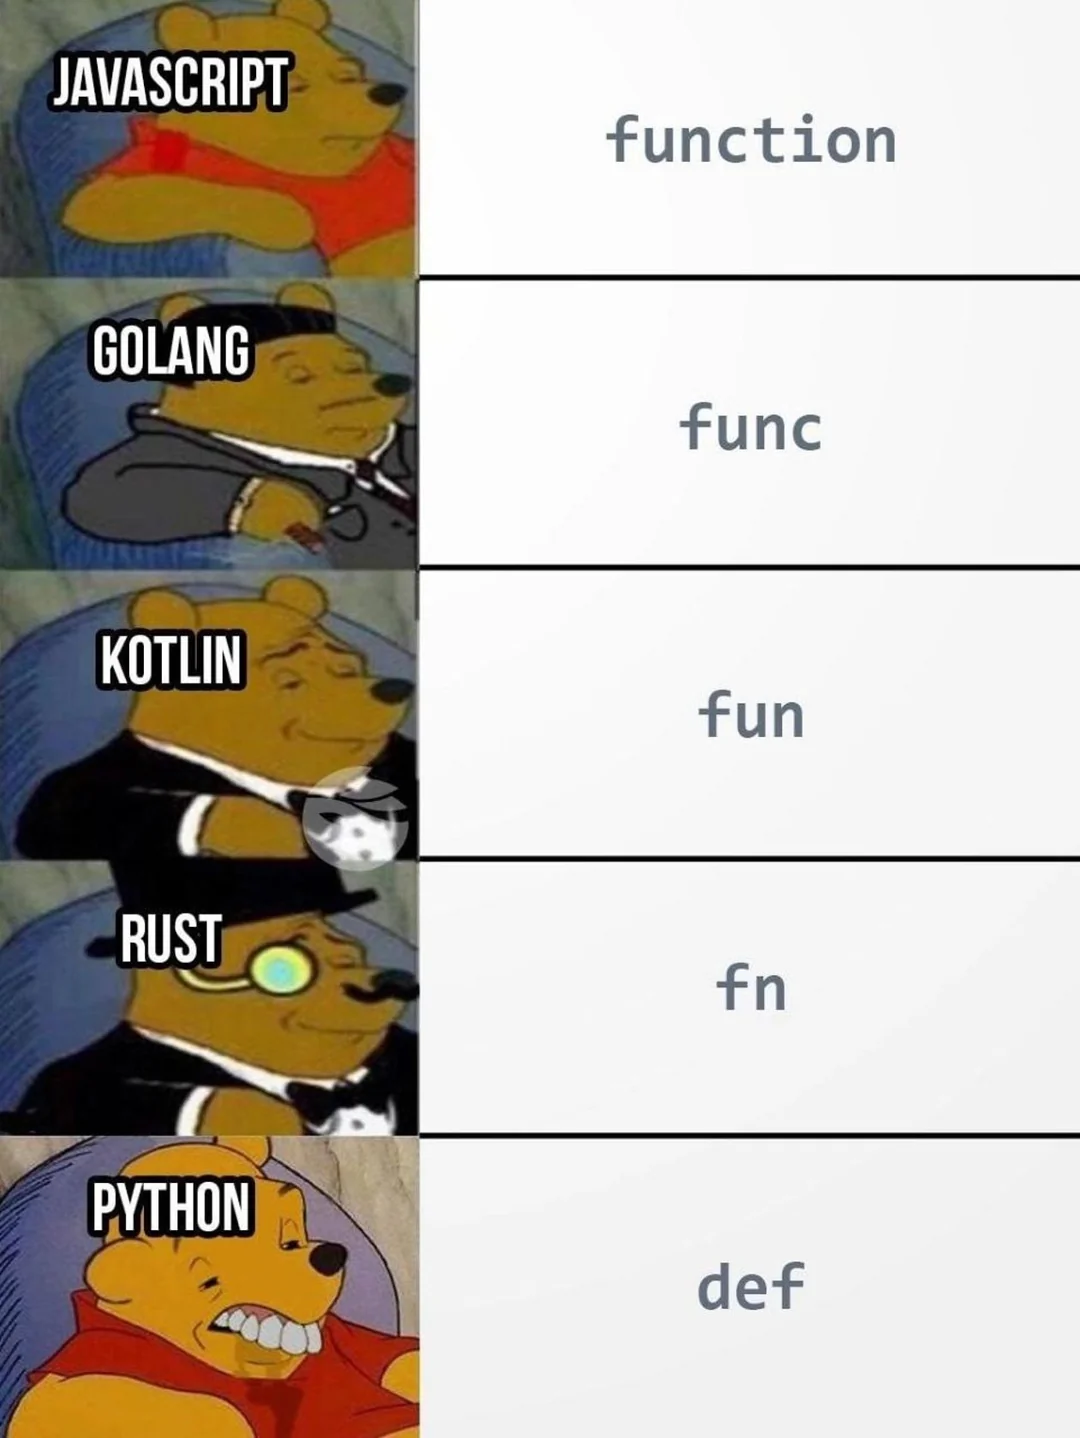

## Не повторяйся (DRY)

Представьте: в трёх местах программы нужно посчитать цену товара со скидкой 20 % и вывести её на экран. Новичок напишет так:

In [1]:
# Место 1
price_1 = 1500
discounted_price_1 = price_1 * 0.8
print(f"Цена со скидкой: {discounted_price_1} руб.")

# ... сто строк другого кода ...

# Место 2
price_2 = 2300
discounted_price_2 = price_2 * 0.8
print(f"Цена со скидкой: {discounted_price_2} руб.")

# ... ещё двести строк ...

# Место 3
price_3 = 990
discounted_price_3 = price_3 * 0.8
print(f"Цена со скидкой: {discounted_price_3} руб.")

Цена со скидкой: 1200.0 руб.
Цена со скидкой: 1840.0 руб.
Цена со скидкой: 792.0 руб.


Работает. А теперь маркетинг говорит: скидка теперь 15 %. Вам нужно найти все места, где написано `0.8`, и заменить на `0.85`. В трёх местах вы найдёте. В тридцати — найдёте двадцать девять. И полгода один раздел сайта будет продавать со скидкой 20 %, пока бухгалтерия не придёт к вам с очень конкретными вопросами.

Против этого есть принцип **DRY — Don't Repeat Yourself**, «не повторяйся». Логика, которая нужна больше одного раза, записывается **один раз** — в функцию.

## Анатомия функции

In [2]:
def calculate_discounted_price(price):
    """Возвращает цену со скидкой 20 %."""
    discounted_price = price * 0.8
    return discounted_price

Ячейка ничего не вывела — и не должна была. Мы записали рецепт в кулинарную книгу, а не сварили кофе. Разберём по частям:

- `def` — от *define*, «определить». Говорит Python: «сейчас будет новая функция».
- `calculate_discounted_price` — имя. Правила те же, что для переменных из прошлой лекции: маленькие буквы, слова через `_`. И имя должно говорить, **что** функция делает: `calculate_discounted_price`, а не `func1` и не `vasya`.
- `(price)` — **параметры** в скобках: что функции нужно получить на вход. Если ничего не нужно — скобки пустые: `def say_hello():`.
- `:` и отступ в четыре пробела — как у `if` и `for`. Всё, что с отступом, — **тело функции**, сам рецепт.
- Строка в тройных кавычках — описание функции, о нём через пару минут.
- `return` — «вернуть». Отдаёт результат туда, откуда функцию позвали, и **сразу** завершает её. Строки после `return` не выполнятся никогда.

Теперь вызываем — пишем имя и в скобках то, что отдаём на вход:

In [3]:
final_price_1 = calculate_discounted_price(1500)
final_price_2 = calculate_discounted_price(2300)
final_price_3 = calculate_discounted_price(990)
print(f"Цены со скидкой: {final_price_1}, {final_price_2}, {final_price_3} руб.")

Цены со скидкой: 1200.0, 1840.0, 792.0 руб.


Те же 1200, 1840 и 792, что и в простыне выше. Но теперь, если скидка изменится, вы поправите **одну** строку внутри функции — и все вызовы сразу начнут считать по-новому.

*🎤 Спросите аудиторию: почему `1200.0`, а не `1200`? (Умножили на float — получили float: если в выражении есть хоть одна дробь, результат тоже дробный.)*

## `return` против `print`: крикнул или передал бумажку

Это самая частая путаница у новичков, и я обещаю, что каждый из вас на неё наступит хотя бы раз.

`print()` **показывает** значение человеку на экране. Программе он ничего не отдаёт.
`return` **возвращает** значение в программу, чтобы с ним можно было работать дальше: сохранить в переменную, передать в другую функцию, сложить, сравнить.

> Вы попросили друга посчитать «2 + 2».
>
> - Если друг **крикнул вам ответ «4»** — это `print()`. Вы услышали. Но в руках у вас ничего нет: умножить это «4» на что-нибудь вы не можете, оно растворилось в воздухе.
> - Если друг **молча написал «4» на бумажке и передал вам** — это `return`. Теперь бумажка у вас: можно положить в карман (в переменную), отдать другому другу, умножить на десять.

Две функции. Одна кричит, другая передаёт бумажку:

In [4]:
def print_sum(a, b):
    result = a + b
    print(f"Сумма {a} и {b} равна {result}")


def return_sum(a, b):
    result = a + b
    return result

Вызовем ту, что кричит, и попробуем сохранить её результат в переменную:

In [5]:
printed_result = print_sum(5, 3)
print(f"В переменной printed_result лежит: {printed_result}")
print(f"Её тип: {type(printed_result)}")

Сумма 5 и 3 равна 8
В переменной printed_result лежит: None
Её тип: <class 'NoneType'>


Видите? Функция честно напечатала «Сумма 5 и 3 равна 8» — это крик. А в переменной оказалось `None` — «ничего». Если в функции нет `return`, Python сам дописывает в конце невидимый `return None`. Бумажки не было — в руках пусто.

Теперь та, что передаёт бумажку:

In [6]:
returned_result = return_sum(5, 3)
print(f"В переменной returned_result лежит: {returned_result}")
print(f"С этим можно работать: {returned_result} + 10 = {returned_result + 10}")

В переменной returned_result лежит: 8
С этим можно работать: 8 + 10 = 18


Сама `return_sum` ничего не печатает — она тихо вернула 8, и дальше мы делаем с ним что хотим.

А теперь классическая ошибка. Человек написал функцию с `print`, увидел на экране правильное число и решил, что всё работает. Пробует прибавить десять:

In [7]:
print_sum(5, 3) + 10   # ⚠️ упадёт специально

Сумма 5 и 3 равна 8


TypeError: unsupported operand type(s) for +: 'NoneType' and 'int'

Сначала функция успела крикнуть «8», а потом Python попытался сложить `None` и `10`: `unsupported operand type(s) for +: 'NoneType' and 'int'`. Увидите в трейсбеке `NoneType` — первым делом проверьте, не забыли ли вы `return`.

И подвох, который маскирует эту ошибку именно в Jupyter. Смотрите:

In [8]:
return_sum(5, 3)

8

Под ячейкой появилось `8`, хотя никакого `print` нет. Это Jupyter вежливо показывает значение **последней строки ячейки**. В обычном скрипте, который вы запустите через `uv run`, эта строка не выведет ничего. Поэтому правило простое: функция, которая **считает**, — возвращает через `return`. Печатает тот, кто её вызвал, когда ему это нужно.

## Параметры и аргументы: анкета

Два слова, которые постоянно путают. Формально разница такая:

- **Параметры** — имена в скобках при **определении** функции. Это пустые места для будущих данных.
- **Аргументы** — конкретные значения, которые вы передаёте при **вызове**. Они эти места занимают.

> Функция — это анкета. Поля «Имя: ____» и «Возраст: ____» — это **параметры**. То, что вы в них вписали, «Иван» и «25», — **аргументы**.

In [9]:
def print_user_profile(name, age):   # name и age — параметры (поля анкеты)
    """Печатает анкету пользователя."""
    print(f"Пользователь: {name}, возраст: {age} лет")


print_user_profile("Алиса", 30)      # "Алиса" и 30 — аргументы (то, что вписали)
print_user_profile("Даниил", 35)
print_user_profile("Линк", 1.5)

Пользователь: Алиса, возраст: 30 лет
Пользователь: Даниил, возраст: 35 лет
Пользователь: Линк, возраст: 1.5 лет


Аргументы раскладываются по параметрам **по порядку**: первый — в `name`, второй — в `age`. Кстати, обратите внимание на Линка: «возраст: 1.5 лет». Функция проглотила дробный возраст и не поморщилась. Запомните этот момент, мы к нему вернёмся, когда дойдём до подсказок типов.

А если поле анкеты не заполнить?

In [10]:
print_user_profile("Алиса")   # ⚠️ упадёт специально

TypeError: print_user_profile() missing 1 required positional argument: 'age'

`missing 1 required positional argument: 'age'` — не хватает одного обязательного аргумента, и Python даже говорит, какого именно. Анкету с пустым обязательным полем не принимают.

## Сбегай за пивом

Функция может внутри принимать решения — всё, что вы знаете про `if`, работает и здесь. Вот функция, которая проверяет, можно ли отправить собеседника в магазин:

In [11]:
def greet_someone(greeting, name, age):
    if age >= 18:
        print(f"{greeting}, {name}! Ты уже можешь сбегать в магазин за пивом. Захвати мне хугарден")
    else:
        print(f"{greeting}, {name}! Ну ты и малявка! Позови кого постарше, я хочу пива")


greet_someone("Здорово", "Жычуань Су", 18)
greet_someone("Приветули", "Константин Браварский", 16)
greet_someone(age=1337, greeting="Hello there", name="Друбрадр Данатович Хырдыбырдов")

Здорово, Жычуань Су! Ты уже можешь сбегать в магазин за пивом. Захвати мне хугарден
Приветули, Константин Браварский! Ну ты и малявка! Позови кого постарше, я хочу пива
Hello there, Друбрадр Данатович Хырдыбырдов! Ты уже можешь сбегать в магазин за пивом. Захвати мне хугарден


В третьем вызове мы нарочно перепутали порядок и поэтому **подписали** каждый аргумент: `age=1337`. Python разложил их по именам, а не по порядку. Это называется именованные аргументы, подробно — в следующем разделе. (А 1337 — это «leet», хакерский сленг. Друбрадру Данатовичу пиво продадут.)

Теперь самое жизненное. Возраст мы обычно получаем от пользователя через `input()`. А `input()` **всегда** возвращает строку:

In [12]:
age_from_input = "27"   # так возраст приходит из input()
greet_someone("Приветули", "Константин Браварский", age_from_input)   # ⚠️ упадёт специально

TypeError: '>=' not supported between instances of 'str' and 'int'

`'>=' not supported between instances of 'str' and 'int'` — строку с числом сравнивать нельзя. Можно было бы засунуть внутрь функции проверку «а не строка ли это, и если строка — превратить в число». Но это плохая идея: функция начинает гадать, что ей прислали, и скоро у вас в каждой функции по три таких проверки.

Правильно — **приводить тип на границе**: там, где данные входят в программу. Пришла строка из `input()` — сразу `int()`. А функция внутри просто работает с числом и ни о чём не гадает:

In [13]:
greet_someone("Приветули", "Константин Браварский", int(age_from_input))

Приветули, Константин Браварский! Ты уже можешь сбегать в магазин за пивом. Захвати мне хугарден


## Docstring: инструкция к функции

Вы написали функцию и прекрасно знаете, что она делает. Сегодня. Через месяц вы откроете этот файл и будете смотреть на него как на чужой код. Потому что это и будет чужой код — его писал вы-месячной-давности, а этот человек ничего не объяснял.

Поэтому первой строкой тела функции пишут **docstring** — строку документации в тройных кавычках. Это не комментарий: комментарий Python выбрасывает, а docstring — обычная строка, которую Python сохраняет вместе с функцией. Её показывает `help()`, её показывает VS Code, когда вы наводите мышку на имя функции. Она может быть однострочной, как у нас выше, а может быть подробной — что функция делает, что принимает и что возвращает.

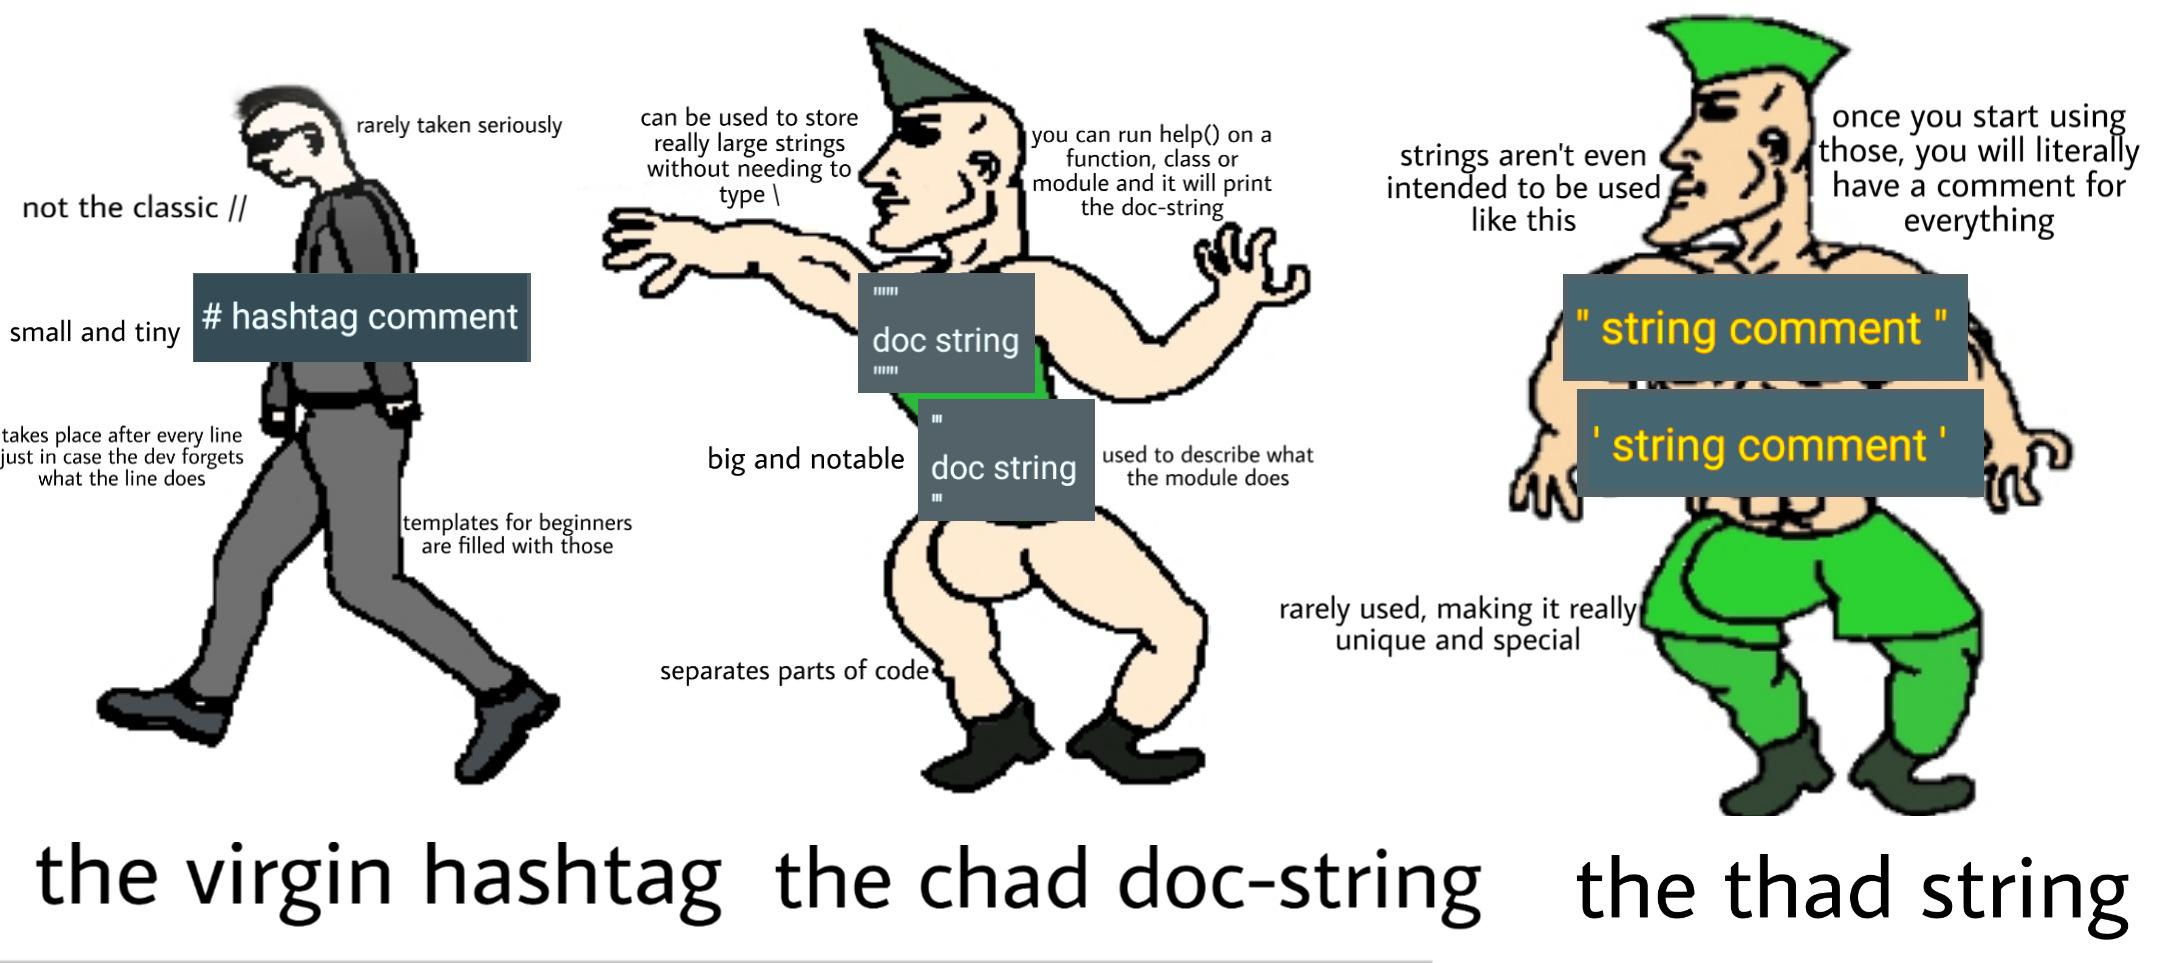

*Комментарий через `#` Python выбрасывает, а docstring остаётся с функцией и показывается в `help()`. А справа — строка в кавычках вместо комментария посреди кода: это уже не стиль, а диагноз. Так не делайте, для комментариев есть `#`.*

Классический формат — так называемый Google-стиль: описание, потом разделы `Args:` (аргументы) и `Returns:` (что возвращает).

In [14]:
def get_final_price(initial_price, discount_percent=20):
    """Считает итоговую цену товара со скидкой.

    Args:
        initial_price: начальная цена товара в рублях.
        discount_percent: скидка в процентах, от 0 до 100. По умолчанию 20.

    Returns:
        Цена после скидки.
    """
    return initial_price * (1 - discount_percent / 100)


print(get_final_price(100))
print(get_final_price(100, 15))

80.0
85.0


`discount_percent=20` — это значение по умолчанию: не передали скидку — будет 20 %. Подробно — в следующем разделе.

А что будет, если передать скидку 150 %? Магазин заплатит вам за то, что вы забрали товар. Как заставить функцию возмутиться — в разделе 10 «Исключения»: там мы к этой скидке вернёмся и дыру закроем. Пока просто держим её в голове.

Теперь прочитаем документацию так, как её прочитает ваш коллега:

In [15]:
help(get_final_price)

Help on function get_final_price in module __main__:

get_final_price(initial_price, discount_percent=20)
    Считает итоговую цену товара со скидкой.

    Args:
        initial_price: начальная цена товара в рублях.
        discount_percent: скидка в процентах, от 0 до 100. По умолчанию 20.

    Returns:
        Цена после скидки.



`help()` показал заголовок функции и наш текст. Ровно так же работает `help()` для любой встроенной функции — попробуйте дома `help(print)` или `help(len)`. А сама строка лежит в атрибуте `__doc__` (два подчёркивания с каждой стороны) — обычная строка, с которой можно работать. `.splitlines()` режет её на строки, `[0]` — первая:

In [16]:
print(get_final_price.__doc__.splitlines()[0])

Считает итоговую цену товара со скидкой.


## Подсказки типов

Помните Линка с возрастом 1.5 и Константина с возрастом-строкой? Функция не знает, что ей должны передавать. И ваш коллега тоже не знает — пока не прочитает тело функции целиком.

В прошлой лекции мы видели аннотацию у переменной: `age: int`. Обещанное «понадобятся с функциями» — вот оно. Аннотации пишут у параметров (через двоеточие) и у результата (через стрелку `->`):

In [17]:
def get_final_price(initial_price: float, discount_percent: float = 20) -> float:
    """Считает итоговую цену товара со скидкой (в процентах)."""
    return initial_price * (1 - discount_percent / 100)


def greet_someone(greeting: str, name: str, age: int) -> None:
    """Здоровается и, если возраст позволяет, отправляет за пивом."""
    if age >= 18:
        print(f"{greeting}, {name}! Ты уже можешь сбегать в магазин за пивом. Захвати мне хугарден")
    else:
        print(f"{greeting}, {name}! Ну ты и малявка! Позови кого постарше, я хочу пива")


print(get_final_price(3990, 15))
greet_someone("Салют", "Линк", 17)

3391.5
Салют, Линк! Ну ты и малявка! Позови кого постарше, я хочу пива


Читаем заголовок, как предложение: «`get_final_price` принимает цену-дробь и скидку-дробь, по умолчанию 20, и возвращает дробь». `-> None` у `greet_someone` прямо говорит: «я ничего не возвращаю, я только кричу». Тело функции читать уже не обязательно.

`float` у цены не значит, что целое число передать нельзя: `3990` — целое, и это нормально. По соглашению там, где написано `float`, можно и `int`.

Главное, что нужно понять: **аннотации — подсказка, а не закон.** Python их при запуске игнорирует:

In [18]:
greet_someone("Привет", "Линк", 1.5)   # аннотация говорит int, передали float — Python молчит

Привет, Линк! Ну ты и малявка! Позови кого постарше, я хочу пива


Никакой ошибки. Ругаться будет редактор: в VS Code включите **Type Checking Mode: standard** (как — рассказывал в прошлой лекции), и вызовы вроде `greet_someone("Привет", "Линк", "27")` подчеркнутся красным ещё **до** запуска. Вот в этом вся польза: ошибку находит редактор за секунду, а не пользователь в пятницу вечером.

Пара записей, которые вы будете постоянно встречать:

- `list[str]` — список строк, `dict[str, int]` — словарь «строка → число».
- `str | None` — «строка или ничего». Вертикальная черта значит «или».

> 🤖 **Где ошибается ваш ИИ.** Ассистенты обожают писать `from typing import List, Dict, Optional` и `def f(names: List[str]) -> Optional[Dict[str, int]]`. Это стиль Python 3.8 и раньше. С Python 3.9 пишут просто `list[str]` и `dict[str, int]`, с 3.10 — `str | None` вместо `Optional[str]`. Старый вариант работает, но выдаёт код, написанный по учебникам пятилетней давности.

*🎤 Код в плашке вслух не читаем — проговариваем: «`List` с большой буквы и `Optional`».*

С этого момента функции, которые мы пишем **для дела**, — с аннотациями. В домашках это пожелание, а не требование: баллы за отсутствие аннотаций я не снимаю, но с ними редактор ловит ошибки раньше меня. А в коротких демонстрациях на лекции я их иногда опускаю, чтобы на экране было меньше шума. В своём коде пишите — редактор скажет спасибо.

# 2. Гибкие аргументы

Пока наши функции жёсткие: сколько параметров объявили — столько аргументов и передавай, строго по порядку. В жизни так неудобно. Половина параметров почти всегда одинаковая, порядок пяти аргументов никто не помнит, а иногда заранее неизвестно, сколько их вообще будет. На всё это у Python есть ответ.

## Значения по умолчанию: кофейня

Вы приходите в кофейню и говорите: «Капучино, пожалуйста». Бариста по умолчанию делает его на обычном молоке, среднего размера, с одним шотом эспрессо. Вам не нужно это уточнять. Но если хочется другого — вы говорите: «Капучино, но на миндальном». Вы **переопределили значение по умолчанию**.

В функции это выглядит так: параметру прямо в `def` присваивается значение. Не передали аргумент — берётся оно.

In [19]:
def greet(name: str, greeting: str = "Привет") -> None:
    print(f"{greeting}, {name}!")


greet("Анна")                         # greeting не передали — будет "Привет"
greet("Иван")
greet("Мария Петровна", "Здравствуйте")   # передали — значение по умолчанию заменено

Привет, Анна!
Привет, Иван!
Здравствуйте, Мария Петровна!


Девять раз из десяти мы говорим «Привет» и не пишем его. Десятый — пишем.

### Правило: параметры по умолчанию — в конце

У Python одно строгое правило: все параметры со значениями по умолчанию идут **после** обычных. Почему? Python раскладывает аргументы по порядку: первый — в первый параметр, второй — во второй. Если бы необязательный стоял первым, при вызове с одним аргументом было бы непонятно, кому он достался. Python даже не будет разбираться:

In [20]:
def incorrect_function(greeting="Привет", name):   # ⚠️ упадёт специально
    print(f"{greeting}, {name}!")

SyntaxError: parameter without a default follows parameter with a default (3232633314.py, line 1)

`SyntaxError: parameter without a default follows parameter with a default` — «параметр без значения по умолчанию идёт после параметра со значением». Это `SyntaxError`: Python отказался даже читать такую функцию, не то что запускать.

Правильно — сначала обязательные, потом необязательные:

In [21]:
def correct_function(name: str, greeting: str = "Привет", punctuation: str = "!") -> None:
    print(f"{greeting}, {name}{punctuation}")


correct_function("Пётр")
correct_function("Ольга", "Добрый вечер", "...")
correct_function("Ольга", "Добрый вечер")

Привет, Пётр!
Добрый вечер, Ольга...
Добрый вечер, Ольга!


Всё как ожидалось. А теперь — я хочу оставить «Привет», но поменять восклицательный знак на многоточие:

*🎤 Спросите, что выведет ячейка, до запуска.*

In [22]:
correct_function("Ольга", "...")

..., Ольга!


«..., Ольга!» Python разложил аргументы по порядку: `"..."` — второй, значит, это `greeting`. Он не знает, что вы имели в виду пунктуацию. Чтобы перепрыгнуть через параметр, его нужно **назвать по имени**. И это следующая тема.

## Именованные аргументы: бронирование

Представьте функцию с пятью параметрами:

`def create_user(login, password, email, is_admin, send_welcome_email): ...`

И её вызов: `create_user("test", "psw123", "a@b.c", False, True)`. Что значит `False`? Что значит `True`? Не помнит никто, включая автора. Перепутаете местами — и выдадите права администратора человеку, которому хотели просто отправить приветственное письмо.

> Вы бронируете билет на сайте. Поля: «Откуда», «Куда», «Дата». Можно сначала заполнить дату, потом «Куда», потом «Откуда» — система всё равно знает, какое значение к какому полю, потому что у полей есть **названия**.

**Именованные аргументы** (keyword arguments) работают так же: при вызове пишете `параметр=значение`, и порядок перестаёт иметь значение. Сначала посмотрим, как бывает без них:

In [23]:
def describe_pet(animal_type: str, pet_name: str) -> None:
    print(f"У меня есть {animal_type}. Его зовут {pet_name}.")


describe_pet("хомяк", "Хома")
describe_pet("Хома", "хомяк")   # перепутали порядок

У меня есть хомяк. Его зовут Хома.
У меня есть Хома. Его зовут хомяк.


«У меня есть Хома. Его зовут хомяк». Python не упал: строка есть строка. Он просто молча сделал глупость. Это хуже, чем ошибка, — ошибку хотя бы видно.

А теперь с именами:

In [24]:
describe_pet(animal_type="кот", pet_name="Барсик")
describe_pet(pet_name="Рекс", animal_type="собака")   # порядок другой — результат правильный
correct_function("Ольга", punctuation="...")          # и вот как перепрыгнуть через greeting

У меня есть кот. Его зовут Барсик.
У меня есть собака. Его зовут Рекс.
Привет, Ольга...


Именованные аргументы делают вызов **самодокументируемым**: `create_user(..., is_admin=False, send_welcome_email=True)` читается без заглядывания в определение.

## Всё вместе: письмо начальнику

На практике значения по умолчанию и именованные аргументы ходят парой. Правило вызова одно: **сначала позиционные аргументы, потом именованные**. Наоборот нельзя.

Вот функция, которая имитирует отправку письма: три обязательных параметра и два необязательных.

In [25]:
def send_email(
    to_address: str,
    subject: str,
    body: str,
    cc: str | None = None,
    priority: str = "normal",
) -> None:
    """Имитирует отправку письма: печатает его на экран.

    Args:
        to_address: адрес получателя.
        subject: тема письма.
        body: текст письма.
        cc: адрес, на который отправить копию. По умолчанию копии нет.
        priority: приоритет письма. По умолчанию "normal".
    """
    print(f"Отправка письма на: {to_address}")
    if cc:
        print(f"Копия: {cc}")
    print(f"Приоритет: {priority}")
    print(f"Тема: {subject}")
    print("---")
    print(body)
    print("=" * 30)

Минимальный вызов — только обязательное:

In [26]:
send_email("student@mail.com", "Лекция 3", "Вот материалы к лекции.")

Отправка письма на: student@mail.com
Приоритет: normal
Тема: Лекция 3
---
Вот материалы к лекции.


Меняем одно необязательное, остальное по умолчанию. Именованным аргументом — чтобы через месяц было понятно, что такое `"high"`:

In [27]:
send_email(
    "boss@company.com",
    "Ежедневный отчёт",
    "Отчёт во вложении.",
    priority="high",  # переопределяем значение по умолчанию
)

Отправка письма на: boss@company.com
Приоритет: high
Тема: Ежедневный отчёт
---
Отчёт во вложении.


И вызов, где всё подписано, в произвольном порядке. Значение последнего аргумента взято из реальной жизни:

In [28]:
send_email(
    body="Не забудь купить молоко!",
    subject="Напоминание",
    to_address="dad@family.net",
    cc="me@self.com",
    priority="писец как срочно"
)

Отправка письма на: dad@family.net
Копия: me@self.com
Приоритет: писец как срочно
Тема: Напоминание
---
Не забудь купить молоко!


Python не возражает: приоритет — это просто строка. Хоть бы проверил, что такого приоритета не бывает. Как заставить функцию возмутиться, когда ей передали негодное значение, — в разделе 10 «Исключения»: покажу на скидке из первого раздела, а приоритет вы потом почините так же.

## Ловушка: изменяемое значение по умолчанию

А теперь — ошибка, на которой спотыкаются не только студенты, но и люди с десятилетним стажем. Пишем функцию, которая добавляет задачу в список дел. Если список не передали — начинаем новый, пустой. Логично?

In [29]:
def add_task(task: str, tasks: list[str] = []) -> list[str]:   # ← здесь бомба
    tasks.append(task)
    return tasks


print(add_task("Купить молоко"))
print(add_task("Позвонить маме"))
print(add_task("Сдать ДЗ3"))

['Купить молоко']
['Купить молоко', 'Позвонить маме']
['Купить молоко', 'Позвонить маме', 'Сдать ДЗ3']


Мы трижды вызвали функцию **без** списка и каждый раз ждали список из одной задачи. А получили растущий список: молоко из первого вызова переехало во второй, мама — в третий.

Почему? Значение по умолчанию вычисляется **один раз** — в момент, когда Python читает `def`. Не при каждом вызове, а один раз на всю жизнь функции. Пустой список создаётся в тот момент и дальше лежит внутри функции. Каждый вызов без аргумента получает **тот же самый** список — то самое «переменная — метка, а не коробка» из прошлой лекции. Все вызовы клеят метку `tasks` на один объект, а `append` его меняет. Можно даже заглянуть, что там сейчас лежит:

In [30]:
print(add_task.__defaults__)

(['Купить молоко', 'Позвонить маме', 'Сдать ДЗ3'],)


Вот она, бомба: внутри функции хранится уже не пустой список, а все три задачи. И четвёртый вызов допишет к ним четвёртую.

Правильный способ: по умолчанию — `None`, а новый список создаём **внутри** функции, при каждом вызове:

In [31]:
def add_task(task: str, tasks: list[str] | None = None) -> list[str]:
    if tasks is None:
        tasks = []   # новый пустой список — при КАЖДОМ вызове
    tasks.append(task)
    return tasks


print(add_task("Купить молоко"))
print(add_task("Позвонить маме"))

['Купить молоко']
['Позвонить маме']


Теперь каждый вызов начинает с чистого листа. И обратите внимание на `is None` — это тот самый единственный законный случай для `is`, о котором мы говорили в прошлый раз.

Правило запомните наизусть: **значение по умолчанию — только неизменяемое**: число, строка, `None`, `True`/`False`, кортеж. Список, словарь, множество — никогда.

> 🤖 **Где ошибается ваш ИИ.** Спросите ассистента про `def f(x=[])` — он прочтёт вам прекрасную лекцию об этой ловушке. А потом в сгенерированном коде сам напишет `def load(cache={})` или `def log(msg, when=datetime.now())` — и во втором случае время «застынет» на моменте запуска программы. Ruff ловит такое правилами `B006` (изменяемое значение по умолчанию) и `B008` (вызов функции в значении по умолчанию), но в стандартном наборе они выключены. Проверьте сами: `uvx ruff check --extend-select B main.py`, как в экстре прошлой лекции. Насовсем — строкой `extend-select = ["B"]` в разделе `[tool.ruff.lint]` файла `pyproject.toml`.

## `*args`: сколько угодно позиционных аргументов

Новая проблема. Функция складывает два числа:

In [32]:
def add_two_numbers(a, b):
    return a + b


print(add_two_numbers(5, 10))
print(add_two_numbers(5, 10, 15))   # ⚠️ упадёт специально

15


TypeError: add_two_numbers() takes 2 positional arguments but 3 were given

`takes 2 positional arguments but 3 were given` — ждали два, дали три. Можно написать `add_three_numbers`, `add_four_numbers` и так до пенсии. А можно сказать функции: «бери сколько дадут».

Для этого перед именем параметра ставят **звёздочку**: `*args`. Python соберёт все лишние позиционные аргументы в **кортеж**. Имя `args` — просто соглашение (от *arguments*); можно назвать `*numbers` или `*items`, звёздочка — вот что важно.

In [33]:
def universal_printer(*args):
    print(f"Тип: {type(args)}, содержимое: {args}")
    for i, arg in enumerate(args, start=1):
        print(f"  Аргумент {i}: {arg}")


universal_printer(1, "hello", True, 3.14)
universal_printer("только одна строка")
universal_printer()

Тип: <class 'tuple'>, содержимое: (1, 'hello', True, 3.14)
  Аргумент 1: 1
  Аргумент 2: hello
  Аргумент 3: True
  Аргумент 4: 3.14
Тип: <class 'tuple'>, содержимое: ('только одна строка',)
  Аргумент 1: только одна строка
Тип: <class 'tuple'>, содержимое: ()


Четыре аргумента — кортеж из четырёх. Один — кортеж из одного, с запятой в конце: `('только одна строка',)`. Ноль — пустой кортеж, и никакой ошибки.

Теперь сумма любого количества чисел:

In [34]:
def flexible_sum(*numbers: float) -> float:
    total = 0
    for number in numbers:
        total += number
    return total


print(flexible_sum(1, 2, 3))
print(flexible_sum(10, 20, 30, 40, 50))
print(flexible_sum(5))

6
150
5


В жизни, конечно, вы напишете встроенную `sum()` — она так и устроена. Нам важен механизм.

Звёздочка работает и в обратную сторону — при **вызове**. Если числа уже лежат в списке, `*` распакует его в отдельные аргументы. Вспомните `first, *rest = ...` из прошлой лекции — это та же звёздочка:

In [35]:
prices = [990, 1500, 2300]
print(flexible_sum(*prices))   # то же, что flexible_sum(990, 1500, 2300)
print(*prices)                 # print тоже принимает *args — значений сколько угодно, а пробел между ними ставит sep

4790
990 1500 2300


Кстати, теперь понятно, почему `print` принимает сколько угодно аргументов: внутри у него тот же `*args`.

## `**kwargs`: сколько угодно именованных

Две звёздочки собирают все лишние **именованные** аргументы в **словарь**: имя аргумента становится ключом-строкой, значение — значением. `kwargs` — тоже соглашение, от *keyword arguments*.

In [36]:
def build_profile(**kwargs):
    print(f"Тип: {type(kwargs)}")
    for key, value in kwargs.items():
        print(f"  {key}: {value}")


build_profile(name="Иван", age=30, city="Москва", status="программист")

Тип: <class 'dict'>
  name: Иван
  age: 30
  city: Москва
  status: программист


Получили обычный словарь, и порядок ключей — ровно тот, в котором мы их передали. Словарь помнит порядок добавления, мы это обсуждали.

Где это в жизни? Везде, где набор настроек заранее неизвестен: параметры графика, поля записи в базе, заголовки HTTP-запроса. Во втором семестре половина функций pandas принимает `**kwargs`.

## Всё вместе

`*args` и `**kwargs` можно использовать в одной функции — тогда она проглотит что угодно. Порядок параметров в определении такой:

1. обычные параметры;
2. `*args`;
3. параметры со значениями по умолчанию — после `*args` их передают только по имени;
4. `**kwargs`.

Ровно так устроен `print`: `print(*args, sep=" ", end="\n")`, поэтому `sep=` всегда пишут с именем. Значения по умолчанию можно поставить и до `*args`, но тогда первый же лишний позиционный аргумент молча займёт их место.

In [37]:
def mega_function(*args, **kwargs):
    print("Позиционные:", args if args else "нет")
    print("Именованные:", kwargs if kwargs else "нет")


mega_function(1, 2, 3, name="Анна", job="Аналитик")
mega_function()

Позиционные: (1, 2, 3)
Именованные: {'name': 'Анна', 'job': 'Аналитик'}
Позиционные: нет
Именованные: нет


Позиционные уехали в кортеж, именованные — в словарь.

Не злоупотребляйте. Функция `def do(*args, **kwargs)` принимает всё и ничего о себе не рассказывает — ни вам, ни редактору, ни ИИ-ассистенту. Если параметры известны заранее — перечислите их явно.

А как значками `*` и `/` прямо в списке параметров **запретить** передавать аргументы по позиции или по имени — читайте дома в разделе 📚 ниже.

## 📚 Самостоятельно: только по имени `*` и только по позиции `/`

Помните `create_user(..., False, True)`, где никто не помнит, что значит `True`? Можно **запретить** вызывать функцию так. Одиночная звёздочка `*` в списке параметров значит: «всё, что после меня, — только по имени».

In [38]:
def create_user(login: str, password: str, *, is_admin: bool = False, send_welcome_email: bool = True) -> None:
    print(f"Создан {login}: админ={is_admin}, письмо={send_welcome_email}")


create_user("test", "psw123", is_admin=False, send_welcome_email=True)   # так можно
create_user("test", "psw123", False, True)   # ⚠️ упадёт специально: так нельзя

Создан test: админ=False, письмо=True


TypeError: create_user() takes 2 positional arguments but 4 were given

`takes 2 positional arguments but 4 were given` — после `*` позиционно передать нельзя, только `is_admin=...`. Кстати, всё, что стоит после `*args`, тоже автоматически становится «только по имени».

Обратное — косая черта `/`: всё, что **до** неё, передаётся только по позиции, по имени нельзя. Сами вы это будете писать редко, но постоянно увидите в `help()` встроенных функций. Вот `sorted`: в одной строке и `/`, и `*`.

In [39]:
print(sorted([3, 1, 2], reverse=True))
help(sorted)

[3, 2, 1]
Help on built-in function sorted in module builtins:

sorted(iterable, /, *, key=None, reverse=False)
    Return a new list containing all items from the iterable in ascending order.

    A custom key function can be supplied to customize the sort order, and the
    reverse flag can be set to request the result in descending order.



`sorted(iterable, /, *, key=None, reverse=False)` читается так: «что сортировать» — только позицией (`sorted(iterable=[...])` не сработает), а `key` и `reverse` — только по имени (`sorted([3, 1, 2], None, True)` не сработает). Параметр `key` нам понадобится уже в разделе 4. Подробности — в документации: [docs.python.org/3.13 → Special parameters](https://docs.python.org/3.13/tutorial/controlflow.html#special-parameters).

# 3. Область видимости: правило Лас-Вегаса

Мы научились передавать данные в функцию и получать результат. Остался вопрос: а что функция видит **вокруг себя**? Может ли она пользоваться переменными, которые созданы снаружи? И куда деваются переменные, которые она создала внутри?

Это называется **область видимости** (scope) — где в коде имя «видно». И у Python тут простое правило, которое удобно запомнить как **правило Лас-Вегаса**:

> **What happens in the function, stays in the function.**
> Что происходит в функции — остаётся в функции.

## Локальные и глобальные

Переменные, созданные **внутри** функции, называются **локальными**. Они рождаются, когда функцию вызвали, и умирают, когда она закончила работу. Снаружи о них никто не знает:

In [40]:
def make_coffee():
    cup = "капучино"
    print(f"Внутри функции: {cup}")


make_coffee()
print(cup)   # ⚠️ упадёт специально

Внутри функции: капучино


NameError: name 'cup' is not defined

Функция отработала и напечатала свой капучино. А снаружи — `NameError: name 'cup' is not defined`. Чашка родилась внутри функции и умерла вместе с её завершением. Снаружи её никогда и не было.

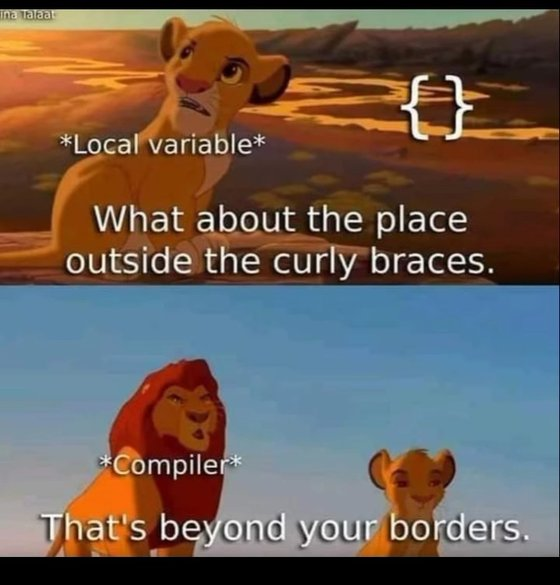

*Фигурных скобок в Python нет — границу королевства у нас рисует отступ под `def`. Но Муфаса прав: за эту границу `cup` не выйдет, `NameError` выше — тому подтверждение.*

Переменные, созданные **снаружи**, на верхнем уровне тетрадки или скрипта, называются **глобальными**. Их функция **видит** и может читать:

In [41]:
discount = 20   # глобальная


def show_discount():
    print(f"Сегодня скидка {discount} %")   # читаем глобальную — можно


show_discount()

Сегодня скидка 20 %


Python не нашёл `discount` внутри функции и посмотрел снаружи. Читать — пожалуйста. А вот с записью начинается самое интересное.

## Переприсваивание: «Джон из Лас-Вегаса»

In [42]:
num = 10
print(f"1. Глобальная num до вызова: {num}")


def func_reassign():
    num = 5   # это НОВАЯ локальная num, к глобальной отношения не имеет
    print(f"2. Внутри функции локальная num: {num}")


func_reassign()
print(f"3. Глобальная num после вызова: {num}")

1. Глобальная num до вызова: 10
2. Внутри функции локальная num: 5
3. Глобальная num после вызова: 10


Внутри функции 5, снаружи как было 10. Когда внутри функции стоит `num = 5`, Python решает: это **новая локальная** переменная, которая просто называется так же. Это Джон из Лас-Вегаса, а не Джон из нашего города. Тёзки, не родственники. Что Джон натворил в Вегасе — осталось в Вегасе.

В терминах прошлой лекции: внутри функции появилась **своя метка** `num`, и её приклеили на пятёрку. Глобальная метка `num` как висела на десятке, так и висит. Никакой «копии» тут нет — просто два разных имени в двух разных местах.

## Мутация: друг покрасил дверь

А теперь то же самое со словарём. Внимание на результат:

In [43]:
values = {"num": 3, "status": "initial"}
print(f"1. Глобальный словарь до вызова: {values}")


def func_mutate():
    values["num"] = 5                       # не создаём новый словарь — меняем СОДЕРЖИМОЕ старого
    values["status"] = "mutated_in_function"


func_mutate()
print(f"2. Глобальный словарь после вызова: {values}")

1. Глобальный словарь до вызова: {'num': 3, 'status': 'initial'}
2. Глобальный словарь после вызова: {'num': 5, 'status': 'mutated_in_function'}


Изменился! Правило Лас-Вегаса нарушено? Нет. Посмотрите внимательно на разницу:

- `num = 5` — это **переприсваивание**: знак `=` перед голым именем. Python создаёт новую локальную метку.
- `values["num"] = 5` — это **мутация**: мы не трогаем метку `values`, мы идём **по ней** к объекту и меняем то, что у него внутри. Никакой новой переменной не создаётся. Python ищет `values`, внутри функции не находит, находит снаружи — и меняет этот самый объект.

> У вас есть бумажка с адресом: «ул. Питонская, д. 10». Вы дали другу её копию.
>
> 1. **Переприсваивание.** Друг зачеркнул адрес на **своей** бумажке и написал «ул. Джавы, д. 5». Ваша бумажка не изменилась, ваш дом тоже.
> 2. **Мутация.** Друг **пошёл по адресу** и покрасил вашу входную дверь в ядовито-зелёный. Адрес на бумажке прежний. Но когда вы вернётесь домой, дверь будет зелёной. Хорошо ещё, если только дверь.

С аргументами — то же самое. Передали в функцию список — функция получила адрес **того же** списка, и `append` внутри изменит ваш список снаружи. Помните `add_task` с бомбой в значении по умолчанию? Это та же история: все вызовы ходили по одному адресу и красили одну и ту же дверь.

## `UnboundLocalError`: ошибка, которая сводит с ума

А теперь хотим посчитать, сколько раз вызвали функцию. Кажется, всё просто:

In [44]:
count = 0


def increment():
    count += 1   # ⚠️ упадёт специально


increment()

UnboundLocalError: cannot access local variable 'count' where it is not associated with a value

`UnboundLocalError: cannot access local variable 'count' where it is not associated with a value` — «нельзя обратиться к локальной переменной `count`, у неё ещё нет значения». Какая локальная? Мы же создали `count` снаружи!

Вот в чём дело. `count += 1` — это `count = count + 1`, то есть **переприсваивание**. Python видит его, ещё когда читает `def`, и решает раз и навсегда: `count` в этой функции — **локальная**. Во всей функции, с первой строки до последней. А потом при вызове пытается вычислить `count + 1` — и обнаруживает, что локальной `count` ещё ничего не присвоено. Глобальную он даже не рассматривает: имя уже записано в локальные.

Это частая ловушка: функция, которая только **читает** `count`, работает. Стоит где-нибудь ниже, хоть в последней строке, дописать `count = ...` — и падает уже первая строка, которая раньше работала.

## `global`: можно, но не нужно

Если уж очень нужно изнутри функции переприсвоить глобальную переменную, есть слово `global`. Оно говорит: «`count` в этой функции — не локальная, а та самая, снаружи».

In [45]:
count = 0


def increment():
    global count   # count здесь — глобальная
    count += 1


increment()
increment()
increment()
print(f"Глобальный count после трёх вызовов: {count}")

Глобальный count после трёх вызовов: 3

Работает. Три вызова — три.

### НО ЭТО ОЧЕНЬ ПЛОХО ТАК ДЕЛАТЬ

Почему? Функция с `global` нарушает правило Лас-Вегаса: она тайком меняет что-то снаружи. Глядя на вызов `increment()`, вы не узнаете, что он что-то поменял. В программе на тысячу строк `count` вдруг оказался 17 вместо 3 — и вы идёте искать по всему коду, какая из двадцати функций с `global count` сделала это лишний раз. Такие функции невозможно нормально проверить, переиспользовать и понять.

Правильный путь — тот же, что весь этот раздел: **данные входят в функцию через аргументы, выходят через `return`**.

In [46]:
def increment(counter: int) -> int:
    return counter + 1


count = 0
count = increment(count)
count = increment(count)
count = increment(count)
print(count)

3


Результат тот же. Но теперь в каждой строке **видно**, что `count` меняется и откуда берётся новое значение. Никакой магии на расстоянии.

Как Python ищет имя по слоям и что делать с функцией внутри функции, — в разделе 📚 ниже, дома.

## 📚 Самостоятельно: LEGB и `nonlocal`

Когда Python встречает имя, он ищет его по четырём слоям, от ближнего к дальнему, и останавливается на первом найденном. Первые буквы слоёв дают **LEGB**:

1. **L — Local**: внутри текущей функции.
2. **E — Enclosing**: в функции, внутри которой объявлена текущая (да, функции можно объявлять внутри функций).
3. **G — Global**: на верхнем уровне файла или тетрадки.
4. **B — Built-in**: встроенные имена Python — `print`, `len`, `sum`.

Последний слой объясняет страшилку из прошлой лекции: назвали переменную `sum = 0` — и встроенная `sum()` пропала. Python нашёл `sum` в слое G раньше, чем в B.

In [47]:
x = "глобальная"


def outer():
    x = "из внешней функции"

    def inner():
        print(f"inner видит: {x}")   # в inner нет x → ищем в outer → нашли

    inner()


outer()
print(f"А снаружи: {x}")

inner видит: из внешней функции
А снаружи: глобальная


Внутренняя функция нашла `x` во внешней (слой E) и до глобального не дошла.

А если внутренней функции нужно **переприсвоить** переменную внешней, получится та же `UnboundLocalError`, что и с `count`. Тут поможет не `global`, а `nonlocal` — «это переменная из функции, внутри которой я живу»:

In [48]:
def make_counter():
    count = 0

    def increment() -> int:
        nonlocal count   # count — из make_counter, а не локальная
        count += 1
        return count

    return increment   # возвращаем саму функцию, без скобок!


counter = make_counter()
print(counter(), counter(), counter())

1 2 3


`make_counter` вернула не число, а **функцию** `increment`, и эта функция помнит свой `count` между вызовами: 1, 2, 3. Глобальных переменных при этом — ноль. Функция, которая помнит переменные из места, где её создали, называется **замыканием** (closure). На замыканиях построены декораторы — о них в одной из следующих лекций. Подробнее про области видимости: [docs.python.org/3.13 → Python Scopes and Namespaces](https://docs.python.org/3.13/tutorial/classes.html#python-scopes-and-namespaces).

# 4. Comprehensions и lambda: питонячий код

До сих пор мы писали код, который понятен человеку из любого языка: цикл, условие, `append`. Работает — и ладно. Но у Python есть свои идиомы, по которым питониста узнают с первой строчки. Если вы их не знаете, вы будете писать на Python с акцентом. Если знаете, но злоупотребляете, — с другим акцентом, ещё хуже.

Сегодня три идиомы: **comprehensions** (сборка коллекции в одну строку), **lambda** (функция без имени) и **`key=`** у `sorted`, `max` и `min`. Последнее вам прямо понадобится в ДЗ2 и ДЗ3.

## Задача: оставить только нечётные

Начнём с простенькой задачи. Есть список чисел, хотим получить **новый** список, в котором останутся только **нечётные** числа.

Небольшое признание. В прошлогодней версии курса в тексте было написано «оставим только чётные», а код честно фильтровал нечётные. И никто этого не заметил. Вот вам и первый урок: код делает то, что в нём написано, а не то, что написано рядом с ним.

In [49]:
initial = [2, 4, 7335, 753, 2, -17, -22]

### Способ 1: как на C

Так бы мы написали на каком-нибудь простом языке без примочек: заводим счётчик, гуляем по индексам, не забываем счётчик увеличить.

In [50]:
odds1 = []  # пустой список
i = 0
while i < len(initial):
    current = initial[i]
    current_is_odd = ((current % 2) == 1)
    if current_is_odd:
        odds1.append(current)

    i = i + 1

### Способ 2: через `for`

Чуть более питонячий способ. Избавились от `i = 0` и `i = i + 1` — значит, меньше шансов ошибиться и улететь в бесконечный цикл.

In [51]:
odds2 = []

for current in initial:
    current_is_odd = ((current % 2) == 1)
    if current_is_odd:
        odds2.append(current)

### Способ 3: list comprehension

Самый питонячий, однострочный и молодёжный:

In [52]:
odds3 = [current for current in initial if (current % 2 == 1)]

In [53]:
print("Способ 1:", odds1)
print("Способ 2:", odds2)
print("Способ 3:", odds3)

Способ 1: [7335, 753, -17]
Способ 2: [7335, 753, -17]
Способ 3: [7335, 753, -17]


Три способа — один результат. Обратите внимание на `-17`: оно попало в нечётные. В прошлой лекции мы выяснили, что в Python `-17 % 2` равно `1`, а не `-1`, как в C. Вот здесь это и сработало. Перепишите этот код на C один в один — и `-17` молча потеряется.

Посмотрите ещё раз на третий способ. Четыре строки цикла сжались в одну, и при этом она **читается словами**: «положи `current` для каждого `current` из `initial`, если `current` нечётное». Это и есть **list comprehension** — по-русски иногда говорят «списковое включение», но так никто не говорит вслух, все говорят «компрехеншн».

## Анатомия comprehension

Классический паттерн, который вы уже писали десятки раз: завести пустой список, пройти циклом, в каждом шаге что-то положить. Например, квадраты чисел от 0 до 9:
```python
squares = []
for i in range(10):
    squares.append(i * i)
```
Три строки ради одного списка. Comprehension делает то же самое так:

In [54]:
squares_comp = [i * i for i in range(10)]
print(squares_comp)

[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]


Структура всегда одна:

`[<что положить> for <элемент> in <откуда брать>]`

Читается почти как предложение: «создай список, положив в него `i * i` для каждого `i` из `range(10)`». Слева — **что** кладём, справа — **откуда** берём. Квадратные скобки снаружи говорят: результат — список.

«Что положить» — это любое выражение. Например, вызов метода у строки:

In [55]:
words = ['hello', 'world', 'python', 'is', 'awesome']
upper_words = [word.upper() for word in words]
print(upper_words)

['HELLO', 'WORLD', 'PYTHON', 'IS', 'AWESOME']


## Добавляем фильтр: `if` в конце

А если элементы нужно не только преобразовать, но и отфильтровать? Например, взять только чётные числа и возвести их в квадрат. Классически:

In [56]:
even_squares = []
for i in range(10):
    if i % 2 == 0:
        even_squares.append(i * i)

print(even_squares)

[0, 4, 16, 36, 64]


Четыре строки. В comprehension условие просто дописывается в конец:

In [57]:
even_squares_comp = [i * i for i in range(10) if i % 2 == 0]
print(even_squares_comp)

[0, 4, 16, 36, 64]


Полная форма:

`[<что положить> for <элемент> in <откуда брать> if <условие>]`

«Положи `i * i` для каждого `i` из `range(10)`, но только **если** `i` делится на 2 без остатка». Условие отсеивает элементы **до** того, как с ними что-то сделают.

А теперь пример из настоящей жизни. Помните журнал трат из ДЗ2, где один и тот же Вася записан тремя способами? В настоящем журнале между строками наверняка затесались бы ещё и пустые. Первое, что вы сделаете с такими данными, — почистите их:

In [58]:
raw_names = ["  Вася ", "ПЕТЯ", "", "маша", "   ", "вася"]
clean_names = [name.strip().capitalize() for name in raw_names if name.strip()]
print(clean_names)

['Вася', 'Петя', 'Маша', 'Вася']


Пустые и пробельные строки отсеялись условием `if name.strip()`: по правилам истинности из прошлой лекции пустая строка — это `False`. А всё, что осталось, приведено к одному виду. Два Васи остались двумя Васями — с дублями разберёмся множеством через пару минут.

## Когда comprehension — зло

Comprehension — это не «цикл, но круче». Это инструмент для одной задачи: **собрать новую коллекцию**. Два правила:

1. **Если не помещается в строку — пишите обычный цикл.** Три `for` и два `if` в одной строке — это не элегантность, это шифровка для коллег. Через месяц коллегой, который не может её прочитать, будете вы.
2. **Не используйте comprehension ради побочных эффектов.** Если вам нужно просто что-то напечатать или записать — это работа для `for`.

*🎤 Спросите аудиторию, что выведет ячейка, до запуска.*

In [59]:
result = [print(name) for name in ["Вася", "Петя", "Маша"]]
print(result)

Вася
Петя
Маша
[None, None, None]


Имена напечатались — `print` сработал внутри. А в `result` лежит список из трёх `None`. Почему? Потому что `print` ничего не возвращает (помните «крикнул, а не передал бумажку» из раздела про функции?). Comprehension послушно собрал всё, что вернули три вызова `print`, — три пустоты. Вы построили список, чтобы тут же его выкинуть. Не делайте так: это как заказать доставку, чтобы курьер у двери прочитал вам меню вслух и уехал.

## Dict comprehension

Та же идея работает для словарей. Только в фигурных скобках и с двоеточием: `{<ключ>: <значение> for <элемент> in <откуда>}`.

In [60]:
# {0: 0, 1: 1, 2: 4, 3: 9, 4: 16}
square_dict = {x: x**2 for x in range(5)}
print(square_dict)

{0: 0, 1: 1, 2: 4, 3: 9, 4: 16}


Где это нужно на практике? Например, у вас прайс-лист, а завтра «Чёрная пятница» и на всё скидка 20 %. Или вы хотите оставить в словаре только дорогие позиции. Тут пригодится `.items()` — пары ключ-значение, которые сразу распаковываются в две переменные:

In [61]:
prices = {"кофе": 250, "круассан": 180, "вода": 90, "сэндвич": 390}

black_friday = {item: round(price * 0.8) for item, price in prices.items()}
print(black_friday)

expensive = {item: price for item, price in prices.items() if price > 200}
print(expensive)

{'кофе': 200, 'круассан': 144, 'вода': 72, 'сэндвич': 312}
{'кофе': 250, 'сэндвич': 390}


Одна строка — новый словарь. Исходный `prices` при этом не тронут: comprehension всегда создаёт **новую** коллекцию.

## Set comprehension

Фигурные скобки, но без двоеточия — получится множество. А множество хранит только уникальные элементы, значит, set comprehension заодно выкинет дубли.

Задача: в списке имена повторяются, да ещё и в разном регистре. Хотим множество уникальных имён в нормальном виде, с большой буквы.

In [62]:
names = ['anna', 'ivan', 'PETER', 'anna', 'peter', 'IVAN']
unique_names_capitalized = {name.capitalize() for name in names}
print(unique_names_capitalized)

{'Anna', 'Peter', 'Ivan'}


Шесть имён на входе — три на выходе. Дубли схлопнулись **после** приведения к одному виду: `'PETER'` и `'peter'` стали одним `'Peter'`, `'ivan'` и `'IVAN'` — одним `'Ivan'`, а две `'anna'` — одной `'Anna'`. Порядок у вас может оказаться другим — это множество, порядка у него нет, и при каждом перезапуске ядра он может меняться.

Тот же приём добивает наших Вась:

In [63]:
print({name.strip().capitalize() for name in raw_names if name.strip()})

{'Петя', 'Вася', 'Маша'}


Разница с прошлым разом — одни скобки: квадратные дали список, фигурные — множество, и второй Вася исчез.

А кортежного comprehension нет. Если написать то же самое в круглых скобках, получится не кортеж, а **генератор** — ленивая штука, которая выдаёт элементы по одному. Про генераторы — в одной из следующих лекций. Пока запомните одно полезное применение: генератор можно сразу отдать в `sum`, `max`, `min` без лишних скобок.

In [64]:
words = ["кот", "гиппопотам", "ёж"]
print(sum(len(w) for w in words))   # сколько букв всего

15


## lambda: функция без имени

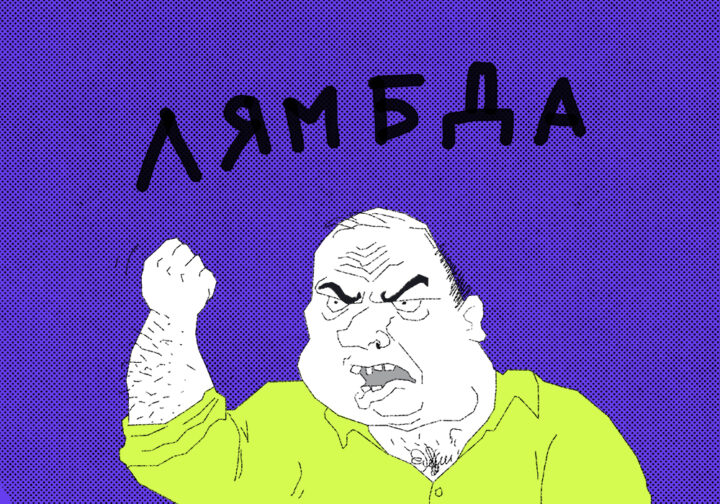

*Примерно так выглядит человек, который впервые увидел `lambda` в чужом коде. Через десять минут вы будете выглядеть так же, только от гордости.*

Иногда нужна крошечная функция ровно на один раз. Писать для неё `def`, придумывать имя, docstring и type hints — как заказывать банкет ради одного бутерброда. Для этого есть **lambda** — анонимная функция в одну строку:

`lambda <аргументы>: <выражение>`

Никакого `return`: результат выражения возвращается сам. Никаких нескольких строк, никаких `if`-блоков (тернарный оператор — можно). Сравним с обычной функцией:

In [65]:
def add(x, y):
    return x + y

add_lambda = lambda x, y: x + y

print(add(2, 3))
print(add_lambda(2, 3))

5
5


Результат один и тот же. Но строчку `add_lambda = lambda x, y: x + y` я показал только для сравнения — **так не пишут**. PEP 8 прямо запрещает присваивать lambda имени: если функции нужно имя, у неё должен быть нормальный `def`. Ruff из прошлой лекции подчеркнёт эту строку правилом `E731`. Lambda живёт там, где имя не нужно: её создали, сразу отдали другой функции и забыли.

А кому её отдают? Чаще всего — `sorted`, `max` и `min`.

## `sorted(…, key=…)`: сортировка по своему правилу

Вот список студентов, каждый — словарь. Хотим отсортировать по среднему баллу. Просто `sorted(students)` не сработает: Python не знает, как сравнить два словаря, — кто из них «больше»?

Для этого у `sorted` есть параметр `key`. Вы даёте ему **функцию**, Python вызывает её для каждого элемента и сортирует по тому, что она вернула. Сами элементы при этом не меняются, они просто встают в нужном порядке. Сначала — способ с обычным `def`:

In [66]:
students = [
    {"name": "Ivan", "gpa": 4.5},
    {"name": "Anna", "gpa": 5.0},
    {"name": "Peter", "gpa": 3.8},
    {"name": "Maria", "gpa": 4.8},
]


def get_gpa(student: dict) -> float:
    return student["gpa"]


ranking = sorted(students, key=get_gpa, reverse=True)
print([s["name"] for s in ranking])

['Anna', 'Maria', 'Ivan', 'Peter']


Заметьте: `key=get_gpa` — **без скобок**. Мы не вызываем функцию, мы отдаём её саму, а вызывать её будет `sorted`, по разу на каждого студента. Напишете `key=get_gpa()` — получите ошибку: функция вызовется сразу, без студента.

Работает, но мы завели целую функцию с именем ради одной строчки. С lambda то же самое:

In [67]:
ranking = sorted(students, key=lambda student: student["gpa"], reverse=True)
print([s["name"] for s in ranking])

['Anna', 'Maria', 'Ivan', 'Peter']


`lambda student: student["gpa"]` — «возьми студента, верни его балл». Ровно то, что делала `get_gpa`, только без имени и прямо на месте.

### Возвращаем долг: «ё»

В прошлой лекции мы видели, что `sorted` ставит «ёлку» после «яблока», потому что сравнивает номера символов, а у «ё» номер больше, чем у «я». Я обещал, что ключ сортировки это починит. Чиним: сортируем не сами слова, а их «нормализованную» версию — в нижнем регистре и с «е» вместо «ё».

In [68]:
words = ["яблоко", "ёлка", "еда", "Ёж", "Арбуз", "арбуз"]
print(sorted(words))
print(sorted(words, key=lambda w: w.lower().replace("ё", "е")))

['Ёж', 'Арбуз', 'арбуз', 'еда', 'яблоко', 'ёлка']
['Арбуз', 'арбуз', 'еда', 'Ёж', 'ёлка', 'яблоко']


Первая строка — по номерам символов: заглавные вперёд, «ёлка» в самом конце. Вторая — по-человечески. При этом в результате слова остались **прежними**, с «Ё» и заглавными буквами: ключ влияет только на то, **как сравнивать**, а не на то, **что выводить**.

### Сортировка по нескольким признакам

А если у двух студентов одинаковый балл? Ключ может вернуть **кортеж**, и тогда Python сравнит сначала первые элементы, при равенстве — вторые, и так далее. Хотим: по баллу по убыванию, а при равенстве — по имени по алфавиту. Трюк с минусом: чтобы одно поле шло по убыванию, а другое по возрастанию, у числа просто меняем знак.

In [69]:
group = [("Петров", 4.5), ("Иванова", 5.0), ("Сидоров", 4.5), ("Абрамова", 4.5)]
print(sorted(group, key=lambda s: (-s[1], s[0])))

[('Иванова', 5.0), ('Абрамова', 4.5), ('Петров', 4.5), ('Сидоров', 4.5)]


Иванова с пятёркой — первая. Дальше трое с 4,5 — по алфавиту.

### Сортировка словаря по значениям

И главное для ДЗ2. У вас будет словарь балансов: кто сколько должен. Хотим вывести его, начиная с самого большого должника. `sorted(словарь)` отсортирует только **ключи** — имена по алфавиту. А нам нужны значения. Берём пары через `.items()` и сортируем по второму элементу пары:

In [70]:
balances = {"Вася": -350.0, "Петя": 1200.5, "Маша": -850.5, "Даша": 0.0}

print(sorted(balances))   # только ключи, по алфавиту — не то
for name, balance in sorted(balances.items(), key=lambda pair: pair[1]):
    print(f"{name:>5}: {balance:>8.2f}")

['Вася', 'Даша', 'Маша', 'Петя']
 Маша:  -850.50
 Вася:  -350.00
 Даша:     0.00
 Петя:  1200.50


Маша должна больше всех — она первая, Петя всех спонсировал — он последний. А в ДЗ3 вам понадобится «топ-5 шаблонов ошибок», и там при равном количестве — по алфавиту. Значит, сортируете по кортежу `(-количество, шаблон)`, как студентов выше, и берёте срез `[:5]`. Считать удобно через `Counter` из прошлой лекции, но его `.most_common()` при равенстве оставляет порядок первого появления, а не алфавит. Для ДЗ3 он не годится: там ничьи — обычное дело.

## `max` и `min` с ключом

У `max` и `min` есть тот же параметр `key`. И в него можно отдавать не только lambda, а **любую** функцию — например, встроенную `len`:

In [71]:
words = ["кот", "гиппопотам", "ёж", "крокодил"]
print(max(words))            # «наибольшая» строка — по номерам символов
print(max(words, key=len))   # самая длинная
print(min(words, key=len))   # самая короткая

best = max(students, key=lambda s: s["gpa"])
print(best["name"], best["gpa"])

richest = max(balances.items(), key=lambda pair: pair[1])
print(richest)

ёж
гиппопотам
ёж
Anna 5.0
('Петя', 1200.5)


Без ключа `max(words)` вернул «ёж» — потому что «ё» с большим номером, а не потому что ёж большой. С `key=len` — гиппопотам, честно. Обратите внимание: `max` с ключом возвращает **сам элемент** (целого студента, целую пару), а не значение ключа. Поэтому из `best` можно достать и имя, и балл.

Итак, правило раздела. Comprehension — когда собираете **новую коллекцию** из старой. Lambda — когда **отдаёте** маленькую функцию в `sorted`, `max`, `min`. Если строка не помещается на экран или вы сами не можете прочитать её вслух — пишите обычный цикл и обычный `def`. Питонячий код — это не самый короткий код, а самый понятный.

# 5. Файлы: память, которая переживёт перезапуск

Что происходит с вашими данными, когда программа завершается? Они исчезают. Перезапустили ядро — и все переменные, которые вы старательно насчитали за полтора часа, ушли туда же, куда хомяк из прошлой лекции.

> **Переменные** — это **мысли у вас в голове**. Они существуют прямо сейчас, с ними можно работать, но стоит отвлечься или уснуть — и их нет. Это оперативная память.
>
> **Файлы** — это **дневник**. Вы записали туда мысль, и она осталась, даже когда вы о ней забыли. Можно перечитать завтра, через неделю, через год. Или его прочитает ваша мама, но это уже вопрос безопасности, а не Python. Это долговременная память.

Сегодня учимся вести дневник.

## Где будут жить наши файлы

Прежде чем что-то записывать, наведём порядок. Сегодня мы создадим кучу файлов: списки покупок, дневники, JSON, модули. Если складывать их рядом с тетрадкой, через час папка лекции превратится в рабочий стол бухгалтера. Поэтому **все файлы этой лекции живут в отдельной папке `L3_files`**, рядом с тетрадкой. Создаём её:

In [72]:
from pathlib import Path

Path("L3_files").mkdir(exist_ok=True)
print("Папка L3_files есть:", Path("L3_files").exists())

Папка L3_files есть: True


`from pathlib import Path` — как `from decimal import Decimal` в прошлой лекции: взять из модуля одну нужную вещь. Что такое модули и как устроен `import`, разберём в разделе 8, а до тех пор просто пользуемся.

`Path` — это путь к файлу или папке в виде объекта. Подробно разберём его в разделе 6, а пока хватит двух вещей: `.mkdir()` создаёт папку, а `exist_ok=True` говорит «если папка уже есть — не паникуй». Без этого второй запуск ячейки упал бы с ошибкой «папка уже существует». Запускайте сколько угодно раз.

Тетрадка работает из своей собственной папки, поэтому путь `"L3_files/shopping.txt"` означает «файл `shopping.txt` в подпапке `L3_files` рядом с тетрадкой». Почему это «рядом с тетрадкой» — не такой очевидный вопрос, как кажется. Он нам ещё аукнется в разделе 6.

## Открыть, сделать, закрыть

Работа с файлом — всегда три шага:
1. **Открыть** файл и сказать, что вы собираетесь с ним делать: читать или писать.
2. **Сделать** дело: прочитать или записать.
3. **Закрыть** файл.

Третий шаг — самый важный и самый забываемый.

Открывает файл встроенная функция `open()`. И сразу важная деталь: она **не** возвращает содержимое файла. Она возвращает **файловый объект** — что-то вроде пульта от файла. Иногда его называют дескриптором или «файл-хендлером». Через этот пульт вы командуете: «прочитай», «запиши», «закрой». А содержимое достаёте отдельной командой.

## Режимы: `r`, `w`, `a`, `x`

Второй аргумент `open()` — **режим**, строка из одной-двух букв:

| Режим | Что делает | Если файла нет | Если файл есть |
|---|---|---|---|
| `"r"` (read) | читать — режим **по умолчанию** | ошибка `FileNotFoundError` | читаем с начала |
| `"w"` (write) | писать с нуля | создаст | **сотрёт всё содержимое** |
| `"a"` (append) | дописывать в конец | создаст | допишет после старого |
| `"x"` (exclusive) | создать новый | создаст | ошибка `FileExistsError` |

*🎤 Таблицу не зачитываем: показываем и проговариваем `"w"` и `"x"` — они ниже.*

Про `"w"` — самое важное. Если файл уже существует, режим `"w"` его **полностью стирает** перед записью. Это как взять лист из дневника, скомкать, выкинуть и положить на его место чистый. Без предупреждения, без корзины, без «Вы уверены?». Сколько дипломов погибло от одного `"w"` вместо `"a"` — история умалчивает, потому что авторы до сих пор не готовы об этом говорить.

Если вы хотите создать файл и при этом **точно** не затереть существующий, есть режим `"x"`: файл уже есть — получите ошибку, а не пустоту.

Ещё бывает буква `"b"` — двоичный режим, `"rb"` или `"wb"`, для картинок, музыки и прочего, что не является текстом. Сегодня мы работаем только с текстом.

## Открыть и закрыть руками

Сначала — старый способ, руками, чтобы вы поняли, почему так больше не делают. Открываем дневник на запись, пишем строку и… пока **не закрываем**. Затем открываем тот же файл второй раз, на чтение, и смотрим, что в нём лежит:

In [73]:
diary = open("L3_files/diary.txt", "w", encoding="utf-8")
diary.write("Дорогой дневник, сегодня я узнал про файлы.\n")

reader = open("L3_files/diary.txt", encoding="utf-8")
print("До close:", repr(reader.read()))
reader.close()

diary.close()

reader = open("L3_files/diary.txt", encoding="utf-8")
print("После close:", repr(reader.read()))
reader.close()

До close: ''
После close: 'Дорогой дневник, сегодня я узнал про файлы.\n'


Видите? До `close()` в файле **пусто** — `''`. Мы же написали строку! Куда она делась?

Она лежала в **буфере** — в оперативной памяти. Python не бегает к диску за каждой буквой, это медленно. Он копит данные и сбрасывает их на диск пачкой: когда буфер заполнится или когда вы закроете файл. Закрыли — строка появилась.

Теперь представьте: между `open` и `close` ваша программа упала. До `close()` дело не дошло. Данные из буфера могут так и не доехать до диска. А на Windows незакрытый файл ещё и **заблокирован**: другая программа не сможет его удалить, переименовать или пересохранить — получите «Файл открыт в другой программе», хотя вы его давно не трогаете. Плюс у операционной системы ограничено число одновременно открытых файлов: забывайте закрывать их в цикле — и однажды упрётесь в лимит.

Закрывать файлы надо. Всегда. Даже если всё сломалось. Люди с этим не справляются, поэтому придумали конструкцию, которая закрывает файл сама.

## `with`: золотой стандарт

```python
with open("имя_файла.txt", "режим", encoding="utf-8") as f:
    # вся работа с файлом — здесь, с отступом
    ...
# блок закончился — файл уже закрыт. Сам. Даже если внутри случилась ошибка.
```

- `with` запускает так называемый **менеджер контекста** — штуку, которая что-то открывает на входе в блок и гарантированно закрывает на выходе.
- `open(...)` — та же функция, что и раньше.
- `as f` — куда положить файловый объект. Называть можно как угодно, но по традиции — `f`, от file.

Вот схема соответствия старого и нового способа: одни и те же куски, только `close()` больше писать не нужно.

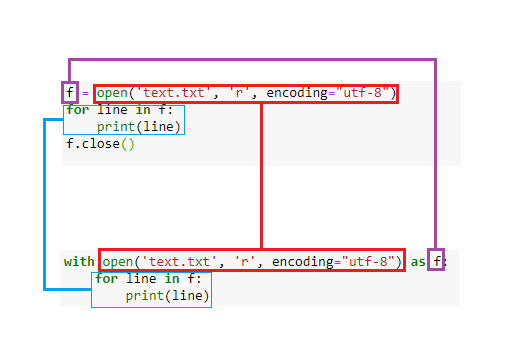

Красное — тот же `open(...)`, фиолетовое — та же переменная `f`, синее — тот же код внутри. А строчки `f.close()` в нижнем варианте нет: её делает `with`.

Как он это гарантирует? На самом деле `with` — это сокращение для конструкции `try`/`finally`:
```python
f = open("text.txt", encoding="utf-8")
try:
    ...            # ваш код
finally:
    f.close()      # выполнится в любом случае — даже если код выше упал
```
`try`/`finally` мы разберём в разделе 10 «Исключения» и там ещё вернёмся к этой эквивалентности. А пока проверим обещание на деле: уроним программу прямо внутри `with`.

In [74]:
with open("L3_files/last_words.txt", "w", encoding="utf-8") as f:
    f.write("Последние слова программы перед смертью\n")
    print(1 / 0)   # ⚠️ упадёт специально

ZeroDivisionError: division by zero

Упало, как и обещали. А теперь вопрос: файл закрылся? Записались ли последние слова?

In [75]:
print("Файл закрыт?", f.closed)

with open("L3_files/last_words.txt", encoding="utf-8") as f:
    print(f.read())

Файл закрыт? True
Последние слова программы перед смертью



Файл закрыт, последние слова на месте. Программа умерла, но завещание успела оформить. Отныне файлы открываем **только** через `with`.

## Пишем список покупок

Запишем список покупок. Режим `"w"`: файла нет — создастся, есть — перезапишется.

In [76]:
shopping_list = ["Молоко", "Хлеб", "Яйца"]

with open("L3_files/shopping.txt", "w", encoding="utf-8") as f:
    f.write("--- Список покупок ---\n")
    for item in shopping_list:
        f.write(item + "\n")   # перенос строки добавляем сами — write его не ставит

print("Файл shopping.txt записан")

Файл shopping.txt записан


Обратите внимание на `"\n"`: `f.write()` — это не `print()`. Он пишет **ровно** то, что вы дали, и никаких переносов строк сам не добавляет. Забудете `"\n"` — получите в файле `МолокоХлебЯйца` одной строкой.

А теперь вспомнили, что нужен ещё кофе. Если открыть файл в `"w"`, весь список сотрётся. Нам нужен `"a"` — дописать в конец:

In [77]:
# запустите один раз: повторный запуск допишет ещё один «Кофе» — в этом и суть "a"
with open("L3_files/shopping.txt", "a", encoding="utf-8") as f:
    f.write("Кофе\n")

## Читаем: три способа

Теперь прочитаем. Способов три, и у каждого свой характер.

1. **`f.read()`** — прочитать **весь** файл в одну большую строку. Просто и удобно для маленьких файлов. Для больших — катастрофа: файл на 10 ГБ Python честно попытается целиком засунуть в оперативную память, и ваш ноутбук ляжет вместе с вами.
2. **`f.readlines()`** — прочитать все строки в **список**. Удобно, если нужен доступ к строкам по номеру. Проблема та же: весь файл в памяти.

   Есть и младший брат второго способа — **`f.readline()`**, без `s` на конце: прочитать **одну** следующую строку, вместе с `\n`. Если нужна только первая строка файла — вам к нему. Не перепутайте: одна буква разницы, а вместо строки получите список.
3. **`for line in f:`** — перебирать файл в цикле, **по одной строке**. В памяти в каждый момент лежит только текущая строка, поэтому так можно прочитать файл любого размера, хоть 100 ГБ. Это способ по умолчанию: в 99 % случаев вам нужен именно он.

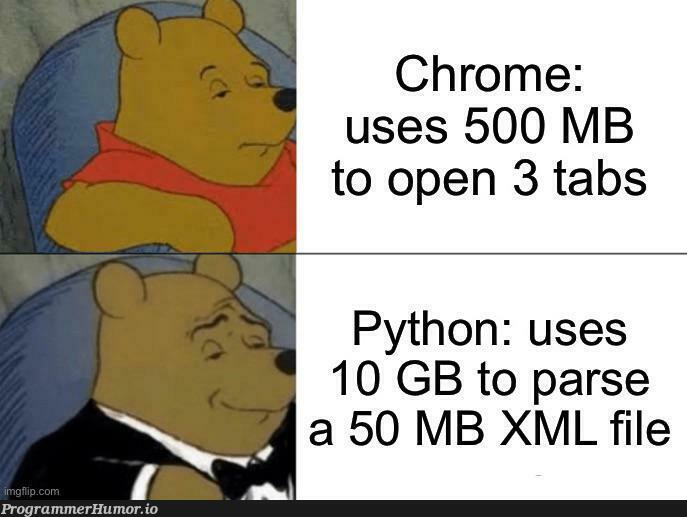

Python, конечно, не всегда такой прожорливый, как на картинке, — но если вы читаете гигабайтный лог через `.read()`, то вы и есть тот самый Python в смокинге.

Режим `"r"` — по умолчанию, поэтому дальше его не пишем. А вот `encoding` — пишем всегда, почему — узнаете через пару минут.

In [78]:
with open("L3_files/shopping.txt", encoding="utf-8") as f:
    content = f.read()
print("Способ 1, read():", type(content))
print(content)

with open("L3_files/shopping.txt", encoding="utf-8") as f:
    lines = f.readlines()
print("Способ 2, readlines():", type(lines))
print(lines)

print("Способ 3, for line in f:")
with open("L3_files/shopping.txt", encoding="utf-8") as f:
    for line in f:
        print(line)

Способ 1, read(): <class 'str'>
--- Список покупок ---
Молоко
Хлеб
Яйца
Кофе

Способ 2, readlines(): <class 'list'>
['--- Список покупок ---\n', 'Молоко\n', 'Хлеб\n', 'Яйца\n', 'Кофе\n']
Способ 3, for line in f:
--- Список покупок ---

Молоко

Хлеб

Яйца

Кофе



Первый способ дал строку, второй — список строк. Кофе на месте, в конце — значит, `"a"` сработал.

А в третьем способе — странные пустые строки между покупками. Откуда?

## Лишний `"\n"` и `.rstrip()`

Посмотрите на список из второго способа: `'Молоко\n'`, `'Хлеб\n'`. Каждая прочитанная строка заканчивается символом переноса — он же был в файле, мы сами его туда записали. Python его не отрезает. Поэтому `print(line)` печатает `Молоко\n` и добавляет **свой** перенос — получается пустая строка.

Это не «зависит от версии Python», как иногда пишут, — так было и будет всегда. От системы зависит другое: на Windows строки в файле заканчиваются не `\n`, а парой символов `\r\n`. Но в текстовом режиме Python при чтении сам превращает `\r\n` в `\n`, а при записи на Windows — обратно. Так что вы везде видите просто `\n`.

Лечим знакомым по прошлой лекции методом. Только не `.strip()`, а `.rstrip("\n")`: `.strip()` срежет ещё и пробелы в начале и конце строки, а иногда они значимы. `.rstrip("\n")` срезает только перенос справа.

In [79]:
clean_list = []
with open("L3_files/shopping.txt", encoding="utf-8") as f:
    for line in f:
        clean_line = line.rstrip("\n")
        print(f"было: {line!r:<16} стало: {clean_line!r}")
        clean_list.append(clean_line)

print(clean_list)

было: '--- Список покупок ---\n' стало: '--- Список покупок ---'
было: 'Молоко\n'       стало: 'Молоко'
было: 'Хлеб\n'         стало: 'Хлеб'
было: 'Яйца\n'         стало: 'Яйца'
было: 'Кофе\n'         стало: 'Кофе'
['--- Список покупок ---', 'Молоко', 'Хлеб', 'Яйца', 'Кофе']


`!r` внутри f-строки — это `repr()`: строка печатается с кавычками и с видимыми спецсимволами. Лучший способ увидеть, что на самом деле лежит в строке, — запомните его для отладки.

## Практика: функции для работы с файлами

Соберём всё вместе и заодно потренируем функции из начала лекции. Две функции:
1. `save_list_to_file(filepath, items)` — записывает каждый элемент списка в файл отдельной строкой. Не забывает про `"\n"`.
2. `read_file_to_list(filepath)` — читает файл построчно и возвращает список строк без переносов.

In [80]:
def save_list_to_file(filepath: str, items: list) -> None:
    """Сохраняет каждый элемент списка в файл отдельной строкой."""
    with open(filepath, "w", encoding="utf-8") as f:
        for item in items:
            f.write(str(item) + "\n")   # str() — в файл можно писать только строки


def read_file_to_list(filepath: str) -> list[str]:
    """Читает файл и возвращает список строк без переносов."""
    with open(filepath, encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]

Видите, `read_file_to_list` уместилась в две строки: comprehension из раздела 4 отлично работает и с файлами, ведь файл тоже можно перебирать в `for`. И ещё одно: `return` прямо внутри `with` — файл при этом всё равно закроется.

Проверяем на моих хобби:

In [81]:
my_hobbies = ["Преподавание", "Чтение дрянной фэнтези", "Столярка", 42, "Дизайн интерьеров"]
save_list_to_file("L3_files/hobbies.txt", my_hobbies)

loaded = read_file_to_list("L3_files/hobbies.txt")
print(loaded)
print(my_hobbies == loaded)

['Преподавание', 'Чтение дрянной фэнтези', 'Столярка', '42', 'Дизайн интерьеров']
False


Всё сохранилось и прочиталось — кроме одного. Найдите отличие. `42` уехало в файл числом, а вернулось строкой `'42'`. Поэтому списки и не равны. Текстовый файл не знает, что такое «число»: в нём есть только символы. Как сохранять данные так, чтобы числа возвращались числами, — в разделе 7 про JSON.

## Кодировки: почему на Windows ломается кириллица

А теперь — главная мина этого раздела. Вы, наверное, заметили, что я в каждом `open()` пишу `encoding="utf-8"`. Это не занудство. Это то, из-за чего ваше ДЗ будет работать у вас и падать у меня.

Компьютер не хранит буквы. Он хранит **байты** — числа от 0 до 255. **Кодировка** — это таблица, по которой буквы превращаются в байты и обратно. Таблиц много. Посмотрите, как одно и то же слово выглядит в двух самых популярных у нас кодировках:

In [82]:
word = "Привет"
print(word.encode("utf-8"))    # .encode() — превратить строку в байты по таблице
print(word.encode("cp1251"))
print(len(word.encode("utf-8")), "байт против", len(word.encode("cp1251")))

b'\xd0\x9f\xd1\x80\xd0\xb8\xd0\xb2\xd0\xb5\xd1\x82'
b'\xcf\xf0\xe8\xe2\xe5\xf2'
12 байт против 6


`b'...'` — это байты. В **UTF-8** на каждую русскую букву уходит два байта, в **cp1251** (она же Windows-1251, старая русская кодировка Windows) — один. Байты совершенно разные. Файл, записанный по одной таблице и прочитанный по другой, превращается в мусор.

Какую таблицу берёт `open()`, если вы **не** указали `encoding`? Вот тут и начинается веселье. Python до версии 3.15 берёт **кодировку системы**:
- на macOS и Linux — UTF-8;
- на Windows с русской локалью — **cp1251**.

А VS Code, GitHub, Telegram и весь современный мир сохраняют текст в UTF-8. Посмотрим, что у вас:

In [83]:
import locale
import sys

print("Кодировка системы:", locale.getencoding())
print("UTF-8 mode:", sys.flags.utf8_mode)

Кодировка системы: UTF-8
UTF-8 mode: 0


Если у вас Mac или Linux — увидите `UTF-8`, и вам повезло. Если Windows — скорее всего `cp1251`, и вот что вас ждёт.

Вторая строка — **UTF-8 mode**, режим, в котором Python работает в UTF-8, что бы ни думала о кодировках система. На 3.13 он по умолчанию выключен, поэтому почти у всех там `0`. Запомните этот флаг: через пару минут он станет главной новостью Python 3.15.

Теперь две классические аварии. Покажу обе живьём: кодировку Windows я буду указывать явно, чтобы на любом компьютере получилось одинаково.

### Авария 1: файл из старой программы, а читаем как UTF-8

Файл записан в cp1251 — так его сохранит старый Блокнот, Excel или ваш собственный код на Windows без `encoding`. А читаем его как UTF-8 — как это сделает одногруппник на Mac, Linux-сервер или любой Python 3.15:

In [84]:
with open("L3_files/windows_note.txt", "w", encoding="cp1251") as f:
    f.write("Привет из Windows!")

with open("L3_files/windows_note.txt", encoding="utf-8") as f:   # ⚠️ упадёт специально
    print(f.read())

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xcf in position 0: invalid continuation byte

`UnicodeDecodeError: 'utf-8' codec can't decode byte 0xcf in position 0`. Байт `0xcf` — это «П» в cp1251. А в UTF-8 такой байт обязан идти в паре с особым продолжением, и Python прямо говорит: «Это не UTF-8, я такое не читаю». Это хорошая авария: вы сразу видите, что что-то не так.

### Авария 2: файл из VS Code, а читаем как cp1251

Обратная ситуация, и она хуже. Вы создали файл в VS Code — он в UTF-8. А ваш код на Windows открывает его без `encoding` — значит, в cp1251:

In [85]:
with open("L3_files/vscode_note.txt", "w", encoding="utf-8") as f:
    f.write("Привет, мир!")

with open("L3_files/vscode_note.txt", encoding="cp1251") as f:
    broken = f.read()
print(broken)

РџСЂРёРІРµС‚, РјРёСЂ!


**Никакой ошибки.** Python спокойно прочитал файл и выдал «РџСЂРёРІРµС‚, РјРёСЂ!». Каждая русская буква в UTF-8 — два байта, и cp1251 прочитал их как две свои буквы. Это и есть **кракозябры** (по-научному mojibake, от японского «превращение букв»). Самое опасное здесь — тишина: программа работает, отчёт строится, а в отчёте вместо имён — «РђРЅРЅР°». И обнаружите вы это на защите.

Иногда, впрочем, cp1251 всё-таки падает. Попробуйте прочитать так файл со словом «Иван»:

In [86]:
with open("L3_files/vscode_name.txt", "w", encoding="utf-8") as f:
    f.write("Иван Петров")

with open("L3_files/vscode_name.txt", encoding="cp1251") as f:   # ⚠️ упадёт специально
    print(f.read())

UnicodeDecodeError: 'charmap' codec can't decode byte 0x98 in position 1: character maps to <undefined>

`'charmap' codec can't decode byte 0x98` — это, пожалуй, самая гуглимая ошибка русскоязычного питониста на Windows. Буква «И» в UTF-8 — это байты `0xd0 0x98`, а байту `0x98` в таблице cp1251 вообще ничего не соответствует. Увидите эту ошибку — сразу знаете диагноз: файл в UTF-8, а открыли его без `encoding`.

### Кракозябры можно починить

Хорошая новость: если байты не потерялись, кракозябры обратимы. Делаем то же преобразование задом наперёд: превращаем испорченный текст обратно в байты той кодировкой, которой его неправильно прочитали, и читаем эти байты правильной.

In [87]:
print(broken)
print(broken.encode("cp1251").decode("utf-8"))   # .decode() — байты обратно в строку

РџСЂРёРІРµС‚, РјРёСЂ!
Привет, мир!


Починили. Теперь — практическое задание повышенной жизненности. Знакомьтесь: это реальный сертификат об окончании курса.

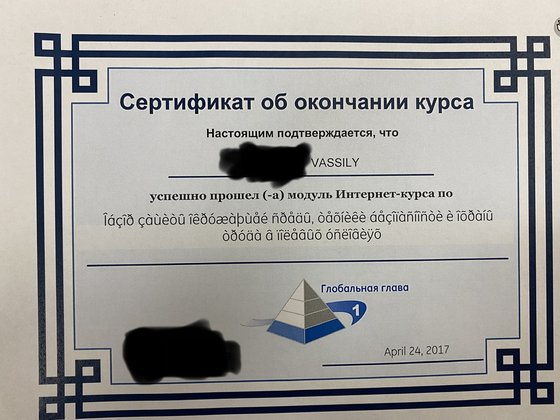

*Человек честно прошёл курс, а название курса ему напечатали байтами cp1251, прочитанными как западноевропейская кодировка. Спорим, вы его сейчас расшифруете одной строкой? Следующая ячейка.*

In [88]:
certificate = "Îáçîð çàùèòû îêðóæàþùåé ñðåäû, òåõíèêè áåçîïàñíîñòè è îõðàíû òðóäà â ïîëåâûõ óñëîâèÿõ"
print(certificate.encode("cp1252").decode("cp1251"))

Обзор защиты окружающей среды, техники безопасности и охраны труда в полевых условиях


Обзор защиты окружающей среды, техники безопасности и охраны труда в полевых условиях. Тот, кто печатал сертификат, взял байты в cp1251 и показал их по западноевропейской таблице cp1252 — там на тех же номерах стоят буквы с крышечками. Мы сделали обратное: вернули байты через cp1252 и прочитали их как cp1251.

Последний вид порчи — ромбики. Когда байты не складываются в буквы, а программе велено не падать, она ставит на их место специальный символ `�` — «тут что-то было, но я не понял что». Так делают браузеры, мессенджеры и Python, если попросить его `errors="replace"`:

In [89]:
cp1251_bytes = "Привет из Windows!".encode("cp1251")
print(cp1251_bytes.decode("utf-8", errors="replace"))

������ �� Windows!


Вместо букв — ромбики с вопросом. И вот это уже **не починить**: байты выброшены и заменены одинаковыми ромбиками, информация потеряна навсегда.

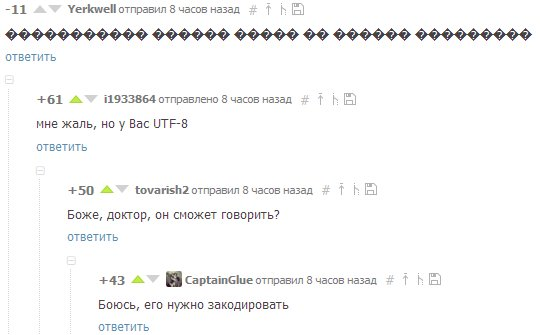

*Диагноз, скорее всего, поставлен ровно наоборот: у пациента как раз не UTF-8 — его байты в другой кодировке прочитали как UTF-8, и всё, что не сошлось, стало ромбиками. Спасти можно, пока жив исходный файл: открыть его с правильным `encoding=`. Если ромбики уже сохранили — медицина бессильна. Кодировать никого не нужно.*

### Что меняет Python 3.15

Девятого октября 2026 года вышел Python 3.15, и в нём наконец исправили эту двадцатилетнюю боль: **UTF-8 стал кодировкой по умолчанию везде, включая Windows** ([PEP 686](https://peps.python.org/pep-0686/)). Технически — включили по умолчанию тот самый UTF-8 mode: на 3.15 ячейка с `sys.flags.utf8_mode` выше покажет `1`. Теперь `open()` без `encoding` на любой системе читает и пишет UTF-8.

Значит, `encoding` можно больше не писать? Нет, по трём причинам:
1. **У вас Python 3.13.** И у проверяющего может оказаться что угодно. Пока весь мир не переехал на 3.15, код без `encoding` ведёт себя на разных машинах по-разному.
2. **Чужие файлы не перекодируются сами.** Старые выгрузки из 1С, Excel, Блокнота как были в cp1251, так и остались. Чтобы их прочитать, вам всё равно придётся явно сказать `encoding="cp1251"`.
3. **Явное лучше неявного.** Это не моя выдумка, это `import this`. Человек, читающий ваш код, сразу видит, в какой кодировке файл.

Правило на всю жизнь: **в каждом `open()` для текста — явный `encoding=`**. По умолчанию — `"utf-8"`, другая — только если вы точно знаете, что файл в ней (как старая выгрузка в cp1251, которая ждёт вас в ДЗ3). Чтобы найти места, где вы забыли, запустите свой скрипт так: `uv run python -X warn_default_encoding main.py` — Python выдаст `EncodingWarning` на каждый `open()` без `encoding`.

### BOM: невидимый символ в начале файла

И последняя ловушка, она точно встретится вам в ДЗ3. Некоторые программы — Excel, старый Блокнот Windows — пишут в начало UTF-8 файла три служебных байта, **BOM** (byte order mark, «метка порядка байтов»). Глазами её не видно. А Python, читающий файл как обычный `"utf-8"`, оставляет её в тексте:

In [90]:
with open("L3_files/from_excel.txt", "w", encoding="utf-8-sig") as f:   # так пишет Excel
    f.write("INFO;Сервер запущен")

with open("L3_files/from_excel.txt", encoding="utf-8") as f:
    first_line = f.readline()
print(repr(first_line))
print(first_line.startswith("INFO"))

with open("L3_files/from_excel.txt", encoding="utf-8-sig") as f:
    print(repr(f.readline()))

'\ufeffINFO;Сервер запущен'
False
'INFO;Сервер запущен'


`'\ufeffINFO...'` — вот он, невидимый пассажир. Из-за него `startswith("INFO")` вернул `False`, хотя глазами строка начинается с `INFO`. Ваш парсер скажет «неизвестный уровень лога» и будет абсолютно прав. Лечится кодировкой `"utf-8-sig"` при чтении: она съедает BOM, если он есть, и ничего не делает, если его нет.

> 🤖 **Где ошибается ваш ИИ.** Попросите ассистента «прочитай файл» — и почти всегда получите `open(path)` без `encoding`. Модели учились в основном на коде, который писали и запускали на Linux и macOS, где это работает. На Windows с Python до 3.14 включительно этот код выдаст кракозябры или `'charmap' codec can't decode`. Увидели `open()` без `encoding` в сгенерированном коде — допишите сами, не дожидаясь аварии.

Работу с таблицами в формате CSV — с модулем `csv` и Excel — разберите сами, в блоке «📚 Самостоятельно» ниже.

## 📚 Самостоятельно: CSV

CSV (comma-separated values) — таблица в текстовом файле: одна строка — одна запись, значения через разделитель. Так выгружают данные Excel, банки, 1С, любые админки. Резать такие строки руками через `.split(",")` — плохая идея: внутри значения может оказаться запятая, кавычки или перенос строки. Для этого в стандартной библиотеке есть модуль `csv`.

Три правила, если файл потом будут открывать в Excel:
- **`newline=""`** при открытии файла, который вы отдаёте модулю `csv`, — обязательно (так требует [документация модуля csv](https://docs.python.org/3.13/library/csv.html)). Модуль сам управляет переносами строк, и без этого на Windows между строками таблицы появятся пустые.
- **`encoding="utf-8-sig"`** — тот самый BOM. По нему Excel понимает, что файл в UTF-8. Без него русский Excel откроет файл как cp1251 и покажет кракозябры.
- **`delimiter=";"`** — в русском Excel разделитель списков — точка с запятой, потому что запятая занята под дробную часть числа. С запятыми вся таблица уедет в одну колонку.

In [91]:
import csv

rows = [
    {"name": "Вася", "spent": 1200.5, "item": "такси, ночью"},
    {"name": "Маша", "spent": 900, "item": "кино"},
]

with open("L3_files/expenses.csv", "w", encoding="utf-8-sig", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["name", "spent", "item"], delimiter=";")
    writer.writeheader()
    writer.writerows(rows)

with open("L3_files/expenses.csv", encoding="utf-8-sig") as f:   # просто посмотреть глазами — без csv
    print(f.read())

with open("L3_files/expenses.csv", encoding="utf-8-sig", newline="") as f:
    for row in csv.DictReader(f, delimiter=";"):
        print(row["name"], "потратил(а)", float(row["spent"]), "на", row["item"])

name;spent;item
Вася;1200.5;такси, ночью
Маша;900;кино

Вася потратил(а) 1200.5 на такси, ночью
Маша потратил(а) 900.0 на кино


`DictWriter` пишет словари, `DictReader` читает каждую строку обратно словарём с ключами из заголовка. Запятая в «такси, ночью» модулю не помешала. Но заметьте: всё, что прочитано из CSV, — **строки**, `float()` пришлось писать самим. Как и в обычном текстовом файле, типов в CSV нет. Если нужно сохранять числа как числа и вложенные структуры — это JSON, раздел 7. А серьёзная работа с таблицами — это pandas, во втором семестре.

# 6. Пути: `pathlib`

До сих пор мы писали пути к файлам строками: `"L3_files/shopping.txt"`. Для одного файла это работает. Но как только вам нужно склеить путь из кусков, достать из него имя или расширение, проверить, существует ли файл, перебрать все `.log` в папке, — строки превращаются в мучение. А на Windows ещё и с обратными слэшами, с которыми мы натерпелись в прошлой лекции: `"C:\data\new"` и внезапный перенос строки посреди пути.

В прошлой лекции я обещал рассказать, как с путями работают по-взрослому. Выполняю. Модуль **`pathlib`** из стандартной библиотеки превращает путь из строки в **объект** — со своими методами, как у строки или списка.

## `Path`: путь как объект

Начнём с вопроса «а где я вообще?». `Path.cwd()` — **c**urrent **w**orking **d**irectory, текущая рабочая папка:

In [92]:
from pathlib import Path

print(Path.cwd())

/workspace/kurs_python/MISIS_2026/season_1


Это папка, в которой лежит тетрадка. У каждого свой путь — на Windows что-нибудь вроде `C:\Users\...\season_1`. Этот вывод нам ещё понадобится — через пять минут.

Пути склеиваются оператором `/` — да, тем самым делением. Создатели `pathlib` переопределили его для путей, и это гениально: читается ровно как путь.

In [93]:
folder = Path("L3_files")
file = folder / "notes" / "todo.txt"

print(file)
print(type(file).__name__)
print("Имя:", file.name)
print("Без расширения:", file.stem)
print("Расширение:", file.suffix)
print("Папка:", file.parent)
print("Другое расширение:", file.with_suffix(".md"))

L3_files/notes/todo.txt
PosixPath
Имя: todo.txt
Без расширения: todo
Расширение: .txt
Папка: L3_files/notes
Другое расширение: L3_files/notes/todo.md


Обратите внимание: я ни разу не написал слэш внутри строки. Python сам поставил нужный разделитель: на Mac и Linux — прямой `/`, на Windows вывод будет с обратными `\`. Один и тот же код работает на любой системе, и больше никаких `"C:\\data\\new"`. А `.name`, `.stem`, `.suffix` и `.parent` избавляют вас от ковыряния в строке через `.split(".")` — особенно приятно на файлах вроде `отчёт.v2.final.docx`.

`type` на Mac и Linux покажет `PosixPath`, а на Windows — `WindowsPath`. Вам это неважно: пишете вы всегда просто `Path`, а нужный вариант Python выбирает сам.

## Существует ли файл, создать папку

Объект `Path` — это просто адрес. Он не означает, что по этому адресу что-то лежит. Проверяем:

In [94]:
print(file.exists())                                 # todo.txt мы ещё не создавали — при первом запуске False
print(Path("L3_files").exists(), Path("L3_files").is_dir())
print(Path("L3_files/shopping.txt").is_file())       # этот создали в разделе 5

False
True True
True


Первая строка — `False`: файла `todo.txt` пока нет. Если вы уже запускали тетрадку целиком, будет `True` — файл остался с прошлого раза. Файлы переживают перезапуск ядра, ради этого мы их и завели.

Последняя строка — `True`, если вы запускали раздел 5. Если начали лекцию прямо с этого раздела — будет `False`, и это правильно.

Папку `notes`, в которой должен лежать `todo.txt`, создадим так же, как `L3_files` в начале раздела 5. Добавим `parents=True` — тогда `mkdir` создаст и все недостающие папки по пути, если их несколько.

## `read_text` и `write_text`: файл в одну строку

Для маленьких файлов у `Path` есть два метода, которые сами открывают, читают или пишут и закрывают файл. Внутри у них тот же `open()` и тот же `with` — просто вам не надо писать их руками. И `encoding` — тоже обязательно, по тем же причинам, что и в разделе 5.

In [95]:
file.parent.mkdir(parents=True, exist_ok=True)
file.write_text("1. Сдать ДЗ\n2. Не сдать ДЗ в последнюю ночь\n", encoding="utf-8")

print(file.exists())
print(file.read_text(encoding="utf-8"))

True
1. Сдать ДЗ
2. Не сдать ДЗ в последнюю ночь



`write_text` — это режим `"w"`: файл перезаписывается целиком. Дописывать в конец он не умеет — для этого по-прежнему `with open(..., "a")`. А `read_text` — это `.read()`: весь файл в память. Для конфига или маленькой заметки — идеально, для 10-гигабайтного лога — та же катастрофа, что и раньше.

## `glob`: все файлы по шаблону

В ДЗ3 вам дадут не файл, а **папку** с логами. Как перебрать все `.log` в ней, не зная заранее их имён? Методом `.glob()` — он ищет файлы по шаблону, где `*` означает «что угодно». Сначала создадим тестовую папку с файлами:

In [96]:
logs = Path("L3_files") / "server_logs"
logs.mkdir(exist_ok=True)
for name in ["app_2.log", "app_10.log", "app_1.log", "readme.txt"]:
    (logs / name).write_text(f"содержимое {name}\n", encoding="utf-8")

for path in sorted(logs.glob("*.log")):
    print(path.name, "—", path.read_text(encoding="utf-8").strip())

app_1.log — содержимое app_1.log
app_10.log — содержимое app_10.log
app_2.log — содержимое app_2.log


`readme.txt` отсеялся: шаблон `*.log` пропускает только файлы с этим расширением. А если нужно искать ещё и во вложенных папках, на любую глубину, — есть `.rglob("*.log")` (r — recursive).

Два момента.

Первый: я обернул `glob` в `sorted()`. `glob` не обещает никакого порядка — какой выдаст файловая система, такой и будет, и на Windows он может отличаться от моего. Хотите одинаковый результат на всех машинах — сортируйте.

Второй: посмотрите на порядок. `app_1`, `app_10`, `app_2`. Десятый файл встал между первым и вторым! Потому что строки сравниваются посимвольно: `"1"` меньше `"2"`, а что там дальше — уже неважно. Компьютер не знает, что `10` — это число, для него это два символа.

## Как называть файлы

Отсюда правила, по которым программисты называют файлы:
- **номера — с нулями впереди**: `app_01`, `app_02`, `app_10` — тогда обычная сортировка совпадёт с числовой;
- **даты — в формате год-месяц-день**: `2026-10-25_report.txt` — тогда файлы по алфавиту выстроятся и по времени;
- **без пробелов**, восклицательных знаков и кириллицы — их любит каждый скрипт, но не так, как вам хотелось бы;
- **маленькими буквами**: на Windows `Report.txt` и `report.txt` — один файл, а на Linux, где запустят ваш код на сервере, — два разных.

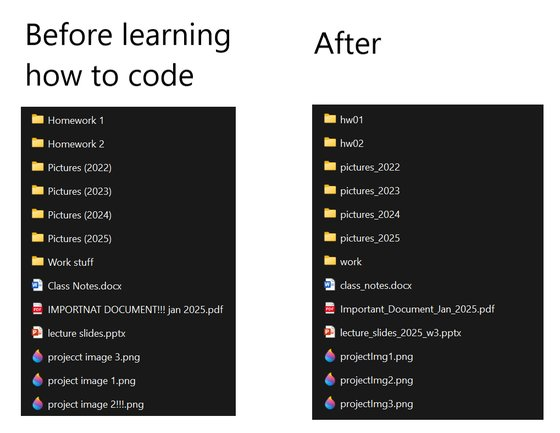

*Слева — папка человека, который ещё не писал `glob` по своим файлам. Справа — после первой попытки: `hw01` с нулём впереди, ни пробелов, ни «!!!». Но присмотритесь: в `Important_Document_Jan_2025` — заглавные буквы и месяц словом, а `projectImg10` однажды встанет между первой и второй картинкой.*

## Относительный и абсолютный путь

**Абсолютный путь** — полный адрес от корня диска: `C:\Users\Vasya\Desktop\hw3\logs\app.log`. Однозначно, но не переносимо. На компьютере преподавателя нет пользователя Vasya и его рабочего стола, а на сервере с Linux нет даже диска `C:`. Абсолютные пути в коде ДЗ — гарантированный незачёт по запуску.

**Относительный путь** — адрес «отсюда»: `logs/app.log`. Две специальные записи: `.` — «текущая папка», `..` — «на уровень выше». Посмотрите на дерево папок:

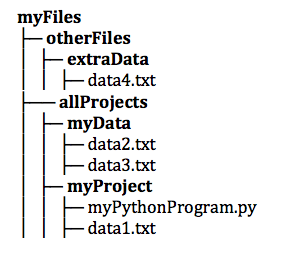

Если вы находитесь в папке `myProject`, то:
- `data1.txt` — лежит прямо здесь;
- `../myData/data2.txt` — подняться в `allProjects`, зайти в `myData`;
- `../../otherFiles/extraData/data4.txt` — подняться на два уровня, в `myFiles`, и спуститься с другой стороны.

`.resolve()` превращает относительный путь в абсолютный — по нему видно, куда на самом деле смотрит Python:

In [97]:
print(Path("L3_files").resolve())
print(Path("..").resolve())

/workspace/kurs_python/MISIS_2026/season_1/L3_files
/workspace/kurs_python/MISIS_2026


Видите слово «находитесь»? Вот теперь — самое важное в этом разделе.

## Ловушка: относительно ЧЕГО?

Относительный путь считается **от текущей рабочей папки** — той самой `Path.cwd()`. **Не** от папки, где лежит ваш скрипт. Не от папки тетрадки. От той папки, **из которой программу запустили**.

Во многих учебниках и почти в каждом ответе ИИ написано: «Python будет искать файл в том же каталоге, что и сам скрипт». Это неправда, и это самая частая причина `FileNotFoundError` у первокурсников. Пока скрипт и запуск совпадают по папке — всё работает, и вы уверены, что так и надо. А потом совпадать перестаёт.

Где это стреляет в VS Code:
- **Тетрадка `.ipynb`** — ядро стартует в папке тетрадки. Поэтому все наши `"L3_files/..."` работают: мы и так «находимся» рядом с тетрадкой.
- **Скрипт по кнопке ▷ Run Python File** — запускается в терминале из **папки, открытой в VS Code** (File → Open Folder), а не из папки, где лежит файл.
- **`uv run hw3/main.py`** — из той папки, где сейчас стоит терминал. Помните, как сдаются ДЗ? «Из папки проекта `uv run hw1/main.py`». То есть рабочая папка — корень проекта, а скрипт лежит на уровень глубже.

Значит, в ДЗ3 вы положите логи рядом со скриптом, `hw3/logs/`, напишете `Path("logs")`, отладите в терминале, где сделали `cd hw3`, — всё работает. А я запущу из корня проекта — и получу `FileNotFoundError`. Вы скажете «у меня работало». И будете правы. Только зачёт ставлю я.

Покажу живьём. Создадим мини-проект: скрипт `main.py` и рядом с ним файл с данными. Скрипт читает данные по относительному пути `"data.txt"` и заодно печатает, из какой папки его запустили.

In [98]:
import subprocess
import sys

project = Path("L3_files") / "hw_demo"
project.mkdir(exist_ok=True)
(project / "data.txt").write_text("Секретные данные ДЗ3\n", encoding="utf-8")
(project / "main.py").write_text('''from pathlib import Path

print("Запущен из папки:", Path.cwd().name)
text = Path("data.txt").read_text(encoding="utf-8")
print("Прочитал:", text.strip())
''', encoding="utf-8")

print(sorted(p.name for p in project.iterdir()))

['data.txt', 'main.py']


`.iterdir()` — перебрать всё, что лежит в папке, без шаблона. Скрипт и данные на месте, рядом. (Если тетрадку уже запускали, там окажется ещё и `main_fixed.py` — он из следующих ячеек.)

Запускать скрипт будем через `subprocess.run` — так же, как в прошлой лекции: это запуск отдельной программы, будто вы набрали команду в терминале. `sys.executable` — путь к тому самому Python, на котором работает тетрадка. А параметр `cwd=` — **из какой папки** запускаем. Ровно то, что нам нужно.

Ещё две детали в вызове. `-X utf8` — тот самый UTF-8 mode из раздела 5: без него скрипт на Windows печатает в кодировке системы, и на английской Windows русские буквы уронят его с `UnicodeEncodeError`. А `encoding="utf-8"` — явная кодировка, в которой мы читаем его вывод. Правило «всегда явный `encoding=`» работает и здесь.

Первый запуск — из папки скрипта. Как будто вы сделали в терминале `cd hw_demo` и `uv run main.py`:

In [99]:
result = subprocess.run([sys.executable, "-X", "utf8", "main.py"], cwd=project,
                        capture_output=True, encoding="utf-8")
print(result.stdout)

Запущен из папки: hw_demo
Прочитал: Секретные данные ДЗ3



Работает. Запущен из `hw_demo`, данные нашлись. Второй запуск — тот же самый скрипт, но из папки тетрадки. Как будто вы открыли в VS Code папку проекта и нажали ▷ или набрали `uv run L3_files/hw_demo/main.py`:

In [100]:
result = subprocess.run([sys.executable, "-X", "utf8", "L3_files/hw_demo/main.py"],
                        capture_output=True, encoding="utf-8")
print(result.stdout)
print("Код возврата:", result.returncode)
print(result.stderr.strip().splitlines()[-1])   # последняя строка трейсбека

Запущен из папки: season_1

Код возврата: 1
FileNotFoundError: [Errno 2] No such file or directory: 'data.txt'


Скрипт тот же, файл с данными на месте, лежит прямо рядом со скриптом. А `FileNotFoundError: ... 'data.txt'`. Потому что «запущен из папки» — теперь папка тетрадки, и `data.txt` Python искал там. Ненулевой код возврата — так программа сообщает системе «я умерла».

## Решение: `Path(__file__).resolve().parent`

Внутри любого `.py`-файла есть специальная переменная `__file__` — путь к **этому самому файлу**. От неё и надо считать: `Path(__file__).resolve().parent` — папка, где лежит скрипт, где бы ни стоял терминал. `.resolve()` здесь — для надёжности: превращает путь в полный абсолютный, что бы ни передали при запуске.

In [101]:
(project / "main_fixed.py").write_text('''from pathlib import Path

HERE = Path(__file__).resolve().parent   # папка, где лежит этот скрипт
text = (HERE / "data.txt").read_text(encoding="utf-8")
print("Скрипт лежит в:", HERE.name, "| запущен из:", Path.cwd().name, "| прочитал:", text.strip())
''', encoding="utf-8")

for cwd in [project, Path.cwd()]:
    result = subprocess.run([sys.executable, "-X", "utf8", str((project / "main_fixed.py").resolve())],
                            cwd=cwd, capture_output=True, encoding="utf-8")
    print(result.stdout.strip() or result.stderr.strip().splitlines()[-1])

Скрипт лежит в: hw_demo | запущен из: hw_demo | прочитал: Секретные данные ДЗ3


Скрипт лежит в: hw_demo | запущен из: season_1 | прочитал: Секретные данные ДЗ3


Два запуска из разных папок — оба успешные. Скрипт больше не зависит от того, где стоит терминал.

Правило для ДЗ и для жизни: **в скрипте все пути к своим файлам — от `Path(__file__).resolve().parent`**. А в тетрадке переменной `__file__` нет — тетрадка не `.py`-файл. Там и не нужно: ядро и так работает из папки тетрадки.

*🎤 Если есть время — покажите вживую в VS Code: откройте папку проекта, создайте `hw_demo/main.py` с чтением `Path("data.txt")` и нажмите ▷. Пусть увидят ошибку в своём собственном терминале.*

Есть ещё настройка VS Code `python.terminal.executeInFileDir` — она заставляет кнопку ▷ запускать скрипт из его папки. Но она чинит **только вашу** кнопку на **вашем** ноутбуке. У проверяющего её нет. `__file__` чинит код.

Раньше пути склеивали модулем `os.path`, и вы его ещё сто раз встретите в старом коде и в ответах ИИ. Как читать такой код — в блоке «📚 Самостоятельно» ниже.

## 📚 Самостоятельно: `os.path`

До `pathlib` (он появился в Python 3.4) пути были просто строками, а работали с ними функции из модуля `os.path`. Код это не сломает, но вы обязаны его читать: им полон StackOverflow, старые туториалы и, увы, ответы ИИ-ассистентов. Словарик:

| `os` / `os.path` | `pathlib` |
|---|---|
| `os.getcwd()` | `Path.cwd()` |
| `os.path.join("a", "b.txt")` | `Path("a") / "b.txt"` |
| `os.path.exists(p)`, `isfile(p)`, `isdir(p)` | `p.exists()`, `p.is_file()`, `p.is_dir()` |
| `os.path.basename(p)` | `p.name` |
| `os.path.splitext(p)` | `p.stem`, `p.suffix` |
| `os.path.dirname(p)` | `p.parent` |
| `os.path.abspath(p)`, `os.path.realpath(p)` | `p.absolute()`, `p.resolve()` |
| `os.makedirs(p, exist_ok=True)` | `p.mkdir(parents=True, exist_ok=True)` |
| `os.listdir(p)`, `glob.glob("*.log")` | `p.iterdir()`, `p.glob("*.log")` |
| `os.path.dirname(os.path.abspath(__file__))` | `Path(__file__).resolve().parent` |

In [102]:
import os

path = os.path.join("L3_files", "server_logs", "app_1.log")
print(path)
print(os.path.exists(path), os.path.isfile(path), os.path.isdir("L3_files"))
print(os.path.basename(path), os.path.splitext(path))
print(os.getcwd() == str(Path.cwd()))

L3_files/server_logs/app_1.log
True True True
app_1.log ('L3_files/server_logs/app_1', '.log')
True


Обратите внимание: `os.path` всегда возвращает **строки**, поэтому из `splitext` приходит кортеж из двух строк, а не удобные атрибуты. И `os.getcwd()` — та же самая текущая папка, что и `Path.cwd()`: ловушка с относительными путями от смены модуля никуда не девается. Тонкость из таблицы: пары там не совсем точные. `abspath` и `absolute()` делают путь абсолютным от текущей папки, а `realpath` и `resolve()` вдобавок раскрывают символические ссылки (это не ярлыки `.lnk` из Windows — ярлыки Python не раскрывает) и выдают настоящий адрес файла — поэтому в правиле про `__file__` у нас `resolve()`. В старом коде вы чаще встретите `abspath`; для ваших задач разницы почти нет.

Новый код пишите на `pathlib`. Если какой-то функции нужна именно строка — `str(path)`.

# 7. JSON: словарь, который пережил перезапуск

Помните мои хобби из раздела 5? Число `42` уехало в текстовый файл, а вернулось строкой `'42'`. Текстовый файл не знает, что такое число, список или словарь, — в нём только символы. Хотите сохранить словарь студента с оценками, вложенным списком и `True`/`False` — и получить его обратно **точно таким же**? Придётся придумать формат: где кавычки, где скобки, как отличить число от строки. Хорошая новость: его уже придумали.

**JSON** (JavaScript Object Notation, читается «джейсон») — текстовый формат для структурированных данных. Родился в JavaScript, но давно стал общим языком всего интернета: на нём разговаривают сайты с серверами, на нём отвечают API, на нём пишут конфиги. В Telegram-ботах через пару лекций вы будете получать JSON каждую секунду. А в ДЗ3 ваша программа должна будет выдать `report.json`.

И главное: JSON выглядит почти как словарь Python. Фигурные скобки, двоеточия, списки в квадратных скобках. Поэтому перевод туда и обратно — одна строка.

## Словарь → файл

Модуль `json` — в стандартной библиотеке, ставить ничего не нужно. Возьмём словарь, в котором есть всё: строки с кириллицей, числа, список, вложенный словарь, `True` и `None`.

In [103]:
import json
from pathlib import Path

student = {
    "name": "Анна Петрова",
    "age": 19,
    "gpa": 4.85,
    "grades": [5, 4, 5, 5],
    "address": {"city": "Москва", "dorm": True},
    "scholarship": None,
}

with open("L3_files/student.json", "w", encoding="utf-8") as f:
    json.dump(student, f, ensure_ascii=False, indent=2)

print(Path("L3_files/student.json").read_text(encoding="utf-8"))

{
  "name": "Анна Петрова",
  "age": 19,
  "gpa": 4.85,
  "grades": [
    5,
    4,
    5,
    5
  ],
  "address": {
    "city": "Москва",
    "dorm": true
  },
  "scholarship": null
}


`json.dump(что, куда)` — записать объект в открытый файл. И два параметра, которые я пишу всегда:
- **`indent=2`** — отступы, чтобы файл читался глазами. Без него весь JSON будет одной бесконечной строкой: компьютеру всё равно, а вам — нет.
- **`ensure_ascii=False`** — писать кириллицу как есть. Про него — через минуту.

Посмотрите на файл: почти Python, но не совсем. `True` стал `true`, `None` стал `null`, а строки — только в двойных кавычках. Это правила JSON, а не Python.

## Файл → словарь

Читаем обратно:

In [104]:
with open("L3_files/student.json", encoding="utf-8") as f:
    loaded = json.load(f)

print(type(loaded).__name__)
print(loaded["address"]["city"], loaded["grades"], type(loaded["age"]).__name__)
print(loaded == student)

dict
Москва [5, 4, 5, 5] int
True


`True` в последней строке — словарь вернулся **точно таким же**. `age` — снова `int`, а не строка `'19'`, оценки — снова список, `null` — снова `None`. Перезапускайте ядро, выключайте ноутбук, отправляйте файл другу — данные переживут всё.

## `ensure_ascii`: зачем этот параметр

По умолчанию `json` перестраховывается и превращает всё, что не ASCII (то есть почти всё, кроме английских букв, цифр и знаков), в коды вида `\u0410`. Посмотрим, что было бы без нашего параметра. Для этого есть `json.dumps` — та же запись, но не в файл, а в строку:

In [105]:
city = {"город": "Москва"}
print(json.dumps(city))
print(json.dumps(city, ensure_ascii=False))

{"\u0433\u043e\u0440\u043e\u0434": "\u041c\u043e\u0441\u043a\u0432\u0430"}
{"город": "Москва"}


Первая строка — формально правильный JSON, любая программа прочитает его без потерь. Но человек — нет. Откройте такой файл, чтобы глянуть, что насчитала ваша программа, — и увидите шифровку. С `ensure_ascii=False` — нормальный текст.

Но тогда в файле появляется кириллица, а значит, как в разделе 5, файл обязательно открываем с `encoding="utf-8"`. Иначе на Windows вы получите ровно те кракозябры, которые мы сегодня уже видели.

## `dump`/`load` против `dumps`/`loads`

Четыре функции, которые все путают. Правило простое: **`s` на конце — это string**, строка.

| | в файл / из файла | в строку / из строки |
|---|---|---|
| Python → JSON | `json.dump(obj, f)` | `json.dumps(obj)` |
| JSON → Python | `json.load(f)` | `json.loads(text)` |

Строковые версии нужны, когда JSON приходит не из файла: из ответа сайта, из сообщения бота, из базы данных. И ещё ими удобно работать вместе с `read_text`/`write_text` из раздела 6: `with` писать не нужно — он у них внутри. А `encoding=` — по-прежнему обязательно. Правило одно: файлы — через `with` или через `read_text`/`write_text`, но **всегда** с `encoding=`:

In [106]:
config = {"bot_name": "МИСИС-бот", "max_users": 100, "admins": ["vorobev"]}

path = Path("L3_files/config.json")
path.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

restored = json.loads(path.read_text(encoding="utf-8"))
print(restored["bot_name"], restored["max_users"] + 1)

МИСИС-бот 101


`max_users + 1` дал `101` — число вернулось числом.

## Что JSON не умеет

JSON знает всего шесть типов: объект (словарь), массив (список), строку, число, `true`/`false` и `null`. Всё. А в Python типов гораздо больше. Что будет с остальными?

Некоторые превращаются молча. Кортеж становится списком (в JSON просто нет кортежей), а ключи-числа — строками (в JSON ключом может быть только строка):

In [107]:
data = {1: "первое место", "coords": (55.75, 37.62)}
back = json.loads(json.dumps(data))
print(back)
print(back == data)

{'1': 'первое место', 'coords': [55.75, 37.62]}
False


Ключ `1` превратился в `'1'`, кортеж — в список, и словарь вернулся **не таким же**. Это пригодится, когда вы, например, посчитаете ошибки по часам `{0: 5, 1: 3, …}`, сохраните в JSON, прочитаете и будете долго выяснять, почему `report[0]` падает с `KeyError`.

А некоторые типы JSON не принимает вообще. Например, множество:

In [108]:
tags = {"python", "json", "files"}
json.dumps({"tags": tags})   # ⚠️ упадёт специально

TypeError: Object of type set is not JSON serializable

`Object of type set is not JSON serializable` — «объект типа set нельзя превратить в JSON». То же самое будет с датой и временем — `datetime`, который мы разберём в разделе 9. И с вашими собственными объектами — до них дойдём на следующей лекции.

Лечится одинаково: **перед записью превратите в то, что JSON понимает.** Множество — в отсортированный список (отсортированный — чтобы файл не менялся от запуска к запуску). Дату — в строку стандартного формата через `.isoformat()`; подробно о нём — в разделе 9, пока просто поверьте.

In [109]:
from datetime import datetime

report = {
    "tags": sorted(tags),
    "created": datetime(2026, 10, 25, 2, 30).isoformat(),
}
print(json.dumps(report, ensure_ascii=False, indent=2))

{
  "tags": [
    "files",
    "json",
    "python"
  ],
  "created": "2026-10-25T02:30:00"
}


Теперь всё сериализуется. «Сериализовать», кстати, — это и есть умное слово для «превратить объект в строку или байты, чтобы сохранить или передать». Обратная операция — десериализация.

Итог раздела в одну строку: **словарь → `json.dump(…, ensure_ascii=False, indent=2)` в файл с `encoding="utf-8"` → `json.load` обратно**. Множества и даты — заранее превратить в списки и строки.

# 8. Модули: ящик с инструментами

Весь день мы пишем `import` — `from pathlib import Path`, `import json`, `import subprocess` — и ни разу толком не спросили, что это такое. Пора. Вы сегодня написали десяток своих функций, а тысячи других уже написали до вас. Их не надо копировать из интернета — их надо **импортировать**.

**Модуль** — это просто файл с кодом на Python, файл `.py`. В нём лежат функции, переменные, константы — всё, что можно взять и использовать в другом месте.

> Представьте, что `print()`, `len()`, `int()` — это инструменты, которые всегда лежат у вас на рабочем столе: молоток, отвёртка. Берите когда угодно.
>
> Но для сантехники или электрики нужны специальные наборы. Они хранятся в ящиках в мастерской. **Модуль — это и есть такой ящик с инструментами.**
>
> `import math` — «принеси мне ящик с математикой». `import datetime` — «принеси ящик для работы со временем».

## `import`: принесли ящик целиком

После `import` инструменты достаются через точку: `ящик.инструмент`. Это сделано, чтобы не было путаницы: в ящике «Сантехника» есть свой ключ, а в ящике «Автомеханика» — свой. Пишете `сантехника.ключ` — и всем понятно, какой именно.

In [110]:
import math

print(math.sqrt(25))          # инструмент sqrt из ящика math
print(math.pi)                # в модуле бывают и константы
radius = 5
print(f"Длина окружности радиуса {radius}: {2 * math.pi * radius:.2f}")

5.0
3.141592653589793
Длина окружности радиуса 5: 31.42


`math.sqrt` — функция `sqrt`, которая живёт в модуле `math`. `math.pi` — переменная оттуда же. Всё как с методами строк, только слева от точки — не строка, а модуль.

## `from … import`: достали один инструмент

Если из ящика нужны одна-две вещи, можно достать только их. Тогда имя модуля перед ними писать не нужно. Но и всё остальное из ящика на стол не попадёт:

In [111]:
from math import sqrt, pi

print(sqrt(144))
print(pi)
print(log10(1000))   # ⚠️ упадёт специально: log10 мы не доставали

12.0
3.141592653589793


NameError: name 'log10' is not defined

`NameError: name 'log10' is not defined`. В ящике `math` функция `log10` есть, но мы взяли только `sqrt` и `pi`. Python так и говорит: такого имени на вашем столе нет.

### Псевдоним: `import … as`

Модулю можно дать короткое имя. Для некоторых библиотек короткие имена — общемировая договорённость. В следующем семестре вы будете писать `import numpy as np`, `import pandas as pd`, `import matplotlib.pyplot as plt` — и **только так**, потому что так пишут все, и любой человек на планете поймёт ваш код с первого взгляда. А пока — стандартная статистика:

In [112]:
import statistics as stats

scores = [72, 85, 90, 64, 85]
print(stats.mean(scores), stats.median(scores), stats.mode(scores))

79.2 85 85


Среднее, медиана и мода, а писать `statistics.` каждый раз не пришлось. Главное — не придумывайте псевдонимы, которые путают читателя. Вот пример, как делать не надо.

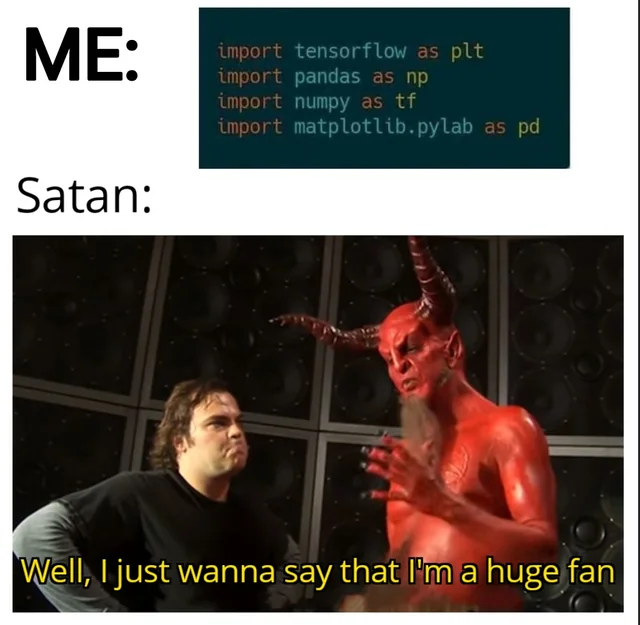

*Договорённости `np`, `pd`, `plt` соблюдает весь мир. Нарушите их — и ваш код будут читать только те, кому это нравится. На картинке — один такой поклонник.*

## `import *`: вывалить весь ящик на стол

Есть третий способ: `from math import *` — «высыпь мне на стол **всё**, что есть в ящике». Выглядит удобно: всё доступно без точек. Давайте посмотрим, чем это кончается.

У вас в программе есть переменная `e` — допустим, электронная почта. А потом вы ленитесь и пишете звёздочку:

In [113]:
e = "ivanov@edu.misis.ru"     # e — e-mail, почему бы и нет
print(e)

from math import *            # высыпали весь math на стол

print(e)                      # а где почта?

ivanov@edu.misis.ru
2.718281828459045


Почта исчезла. На её месте — число Эйлера 2,718…, потому что в модуле `math` тоже есть `e`, и звёздочка молча положила его поверх вашей переменной. Ни ошибки, ни предупреждения. Через двести строк вы отправите письмо на адрес `2.718281828459045` и будете час искать, кто это сделал.

А теперь представьте, что звёздочек две, из двух разных модулей. Какое `e`, какое `log`, какое `open` победит? То, что импортировано последним. Это не шутка: `from os import *` подменяет встроенную функцию `open` на одноимённую функцию из модуля `os`, которая работает совершенно иначе, — и ваш код чтения файлов из пятого раздела внезапно падает с непонятной ошибкой.

Поэтому руководство по стилю PEP 8 прямо говорит: импортов со звёздочкой надо избегать. Правило простое:

- `import math` → `math.sqrt(...)` — всегда понятно, откуда что взялось;
- `from math import sqrt, pi` — если вещей мало и они нужны часто;
- `from math import *` — никогда. Разве что в интерактивной консоли, когда считаете что-то на коленке.

### Где Python ищет модули

Когда вы пишете `import что-то`, Python перебирает список папок из `sys.path` по порядку и берёт **первый** найденный файл с таким именем. Если вы запускаете скрипт — `python main.py` в терминале, — первой в списке стоит папка этого скрипта, потом стандартная библиотека, потом установленные пакеты. А в Jupyter порядок другой. Посмотрим на список прямо из тетрадки:

In [114]:
import sys

for folder in sys.path:
    print(folder or "''   ← пустая строка: текущая папка, то есть папка тетрадки")

/home/sandbox/.local/share/uv/python/cpython-3.13.16-linux-x86_64-gnu/lib/python313.zip
/home/sandbox/.local/share/uv/python/cpython-3.13.16-linux-x86_64-gnu/lib/python3.13
/home/sandbox/.local/share/uv/python/cpython-3.13-linux-x86_64-gnu/lib/python3.13/lib-dynload
''   ← пустая строка: текущая папка, то есть папка тетрадки
/tmp/uvtest/misis_course/.venv/lib/python3.13/site-packages


Пути у вас будут свои, но порядок тот же. Сначала — стандартная библиотека (`python313.zip`, папка самого Python, `lib-dynload`; на Windows там будут `DLLs` и `Lib`), потом — папка тетрадки, и только в самом конце — `site-packages`, куда ставятся сторонние пакеты. IPython, на котором работает Jupyter, нарочно ставит папку тетрадки **после** стандартной библиотеки. Запомните оба порядка — для скрипта и для тетрадки: в экстра-разделе ниже первокурсник на них споткнётся.

## Сторонние библиотеки: `uv add`

Модули, которые идут вместе с Python, — `math`, `random`, `statistics`, `datetime`, `json`, `pathlib` — называются **стандартной библиотекой**. Про Python говорят «батарейки в комплекте»: в стандартной библиотеке есть очень многое.

Всё остальное — сторонние библиотеки. Они лежат на сайте **PyPI** (pypi.org, Python Package Index), и их сотни тысяч. Чтобы поставить библиотеку в свой проект, в нашем курсе есть ровно одна команда. Её пишут **в терминале VS Code**, в папке проекта, а не в ячейке тетрадки:

```
uv add emoji
```

uv скачает пакет, положит его в виртуальное окружение `.venv` вашего проекта и запишет в `pyproject.toml`, что проекту нужен `emoji`. Потом ваш одногруппник склонирует репозиторий, наберёт `uv sync` — и получит ровно те же библиотеки.

(Кто работает в Miniforge без uv — для вас та же команда звучит как `pip install emoji` в Miniforge Prompt с активированным окружением курса.)

> 🤖 **Где ошибается ваш ИИ.** На вопрос «как поставить библиотеку» ассистент почти всегда ответит `pip install emoji` или `!pip install emoji`, а то и предложит поставить Anaconda. Но в uv-окружении `pip` нет. `!pip install` в ячейке в лучшем случае скажет, что pip не найден, а в худшем — поставит пакет в какой-то другой Python на вашем компьютере, и `import` всё равно не сработает. Без `!` Jupyter молча превратит строку в магию `%pip`, и в uv-окружении она ответит `No module named pip`, а в `.py`-файле это просто `SyntaxError`. Переводите на наш язык: **`uv add <пакет>` в терминале.** И проверяйте, что пакет вообще существует, — почему, расскажу в экстра-разделе.

Библиотека `emoji` у вас уже стоит, если вы выполнили команду из начала лекции (вместе с `tzdata` и `pendulum`). Она умеет превращать текстовые коды в смайлики и обратно:

In [115]:
import emoji

print(emoji.emojize("Python is :thumbs_up:"))
print(emoji.demojize("Сдал ДЗ 🎉, лёг спать 😴"))

Python is 👍
Сдал ДЗ :party_popper:, лёг спать :sleeping_face:


Коды `:thumbs_up:` превратились в картинку, а картинки — обратно в коды. Зачем это аналитику? Например, чтобы посчитать, какие эмодзи чаще всего ставят в отзывах: в тексте `:thumbs_down:` искать гораздо проще, чем саму картинку.

## Свой модуль

А теперь главное: **любой ваш `.py`-файл — уже модуль.** Никаких специальных заклинаний не нужно. Напишете функцию в одном файле — сможете импортировать её в другом.

Создадим файл `module_1.py` в нашей папке `L3_files`. Обычно его создают в редакторе, а мы для наглядности запишем его прямо из тетрадки через `pathlib`. В модуле — функция `hell()` и одна строчка, которая выполняется сразу и печатает служебную переменную `__name__`. Что это такое, разберёмся через минуту.

In [116]:
from pathlib import Path

Path("L3_files/module_1.py").write_text('''
def hell():
    print("Hot Hell Hello from module_1")

print("module_1 загружается, моё __name__ =", __name__)
''', encoding="utf-8")

112

Число в выводе — сколько символов записалось, это `write_text` так отчитывается. Теперь импортируем. Модуль лежит в папке `L3_files`, а папка с модулями в Python называется **пакетом**, поэтому путь пишется через точку — как адрес: «из пакета `L3_files` принеси модуль `module_1`».

In [117]:
from L3_files import module_1

module_1.hell()

module_1 загружается, моё __name__ = L3_files.module_1
Hot Hell Hello from module_1


Две вещи. Первая: при импорте Python **выполнил весь файл** сверху донизу — поэтому напечаталась строчка про загрузку. Определение функции тоже выполнилось — так у модуля появилась `hell`. Вторая: `__name__` у модуля — его полное имя, `L3_files.module_1`.

*🎤 Если строчки про загрузку нет — значит, вы уже импортировали модуль в этом сеансе (например, на репетиции). Сделайте Restart ядра; почему так — через минуту.*

Достанем `hell` напрямую, через `from … import`:

In [118]:
from L3_files.module_1 import hell

hell()

Hot Hell Hello from module_1


Строчка про загрузку **не напечаталась**. Python загружает модуль один раз за сеанс и запоминает его. Второй импорт берёт уже загруженный модуль из памяти.

## `if __name__ == "__main__"`

Тот же файл можно не импортировать, а **запустить как программу** — `python module_1.py` или `uv run module_1.py` в терминале. Как в разделе 6, запустим его через `subprocess` из папки `L3_files` (с теми же `-X utf8` и `encoding="utf-8"`):

In [119]:
import subprocess
import sys

result = subprocess.run([sys.executable, "-X", "utf8", "module_1.py"], cwd="L3_files",
                        capture_output=True, encoding="utf-8")
print(result.stdout)

module_1 загружается, моё __name__ = __main__



Теперь `__name__` равно `"__main__"`. Вот и весь фокус: Python сам кладёт в `__name__` либо имя модуля (если файл импортировали), либо строку `"__main__"` (если файл запустили как программу). Файл может узнать, как с ним поступили.

Зачем это нужно? Представьте, что в конце модуля вы написали проверку своих функций: вызвали их на примерах, напечатали результаты. Или обучение модели на три часа. Без защиты всё это будет выполняться **при каждом импорте**: коллега напишет `from your_module import hell` — и получит три часа обучения и простыню принтов в подарок.

Поэтому код, который должен работать только при запуске файла как программы, прячут под условие:

In [120]:
Path("L3_files/module_1.py").write_text('''
def hell():
    print("Hot Hell Hello from module_1")


if __name__ == "__main__":
    # сюда — то, что нужно только при запуске файла как программы
    print("Меня запустили как программу. Проверяю hell():")
    hell()
''', encoding="utf-8")

result = subprocess.run([sys.executable, "-X", "utf8", "module_1.py"], cwd="L3_files",
                        capture_output=True, encoding="utf-8")
print(result.stdout)

Меня запустили как программу. Проверяю hell():
Hot Hell Hello from module_1



Как программа — проверка сработала. А при импорте условие ложно, и тело `if` пропускается. Но у Jupyter тут есть подвох. Модуль, как мы только что видели, загружается один раз за сеанс, поэтому обычный `import` **не перечитает** изменённый файл — тетрадка до сих пор работает со старой версией. Чтобы перечитать, есть `importlib.reload`:

In [121]:
import importlib

importlib.reload(module_1)   # перечитать файл заново
module_1.hell()              # при импорте блок под if молчит

Hot Hell Hello from module_1


Файл перечитан, `hell()` работает. А вот «Меня запустили как программу» не появилось: при импорте `__name__` равно `"L3_files.module_1"`, а не `"__main__"`, и блок под `if` пропущен.

*🎤 Здесь стоит сказать вслух: «поправил модуль, а в тетрадке ничего не изменилось» — типичная жалоба при работе с модулями в Jupyter. Лечится `importlib.reload` или перезапуском ядра (Restart). Продвинутые ставят в начало тетрадки магию `%load_ext autoreload` и `%autoreload 2`, и Jupyter перечитывает изменённые модули сам.*

Запомните шаблон. Вы будете видеть `if __name__ == "__main__":` в конце почти каждого скрипта на Python — теперь вы знаете, что он значит. Пока у нас один `module_1`, пентаграмму чертить не из чего. Но модулей станет больше.

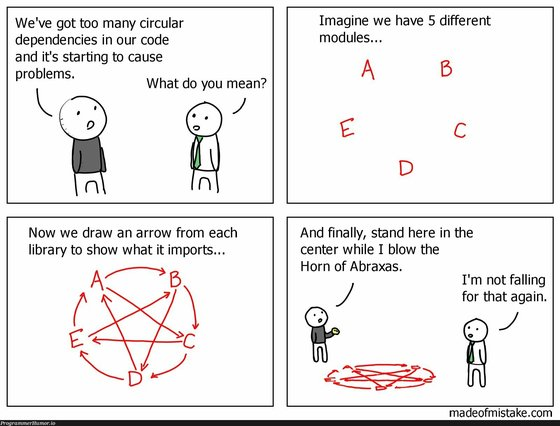

*Пять модулей, и каждый импортирует ещё двоих — стрелки по кругу и звездой, — а коллега уже зовёт вас встать в центр пентаграммы. Не вставайте: Python ответит `ImportError: … partially initialized module … (most likely due to a circular import)` — циклический импорт. Лечится не рогом Абраксаса, а тем, что общее выносят в отдельный модуль, который никого не импортирует.*

### Новинка: `lazy import` в Python 3.15

Последнее. Импорт не бесплатный: большая библиотека может загружаться секунду и больше, даже если в этот раз она вам не понадобится. В Python 3.15, который вышел в октябре 2026 года, появилось новое слово: `lazy import json` — модуль загрузится не в момент импорта, а при первом реальном обращении к нему (PEP 810). У нас Python 3.13, поэтому просто знайте, что такое бывает, и не удивляйтесь, когда увидите.

## 🧨 Экстра: не называйте файл `random.py` и не ставьте пакет, который придумал ChatGPT

> Можно пропустить — тогда читаете дома.

Python ищет модули по списку папок и берёт **первый** найденный, а у запущенного скрипта первая в списке — его собственная папка. Сейчас мы используем это во зло.

Классическая история первокурсника. Вы изучаете модуль `random` и, как порядочный человек, называете свой учебный файл `random.py`. Рядом — игра в кости `dice.py`, которая делает `import random`. Создадим оба файла в `L3_files` и запустим игру:

In [122]:
Path("L3_files/random.py").write_text('print("я твой random.py")\n', encoding="utf-8")
Path("L3_files/dice.py").write_text("import random\nprint(random.randint(1, 6))\n", encoding="utf-8")

result = subprocess.run([sys.executable, "-X", "utf8", "dice.py"], cwd="L3_files",
                        capture_output=True, encoding="utf-8")
print(result.stdout)
print(result.stderr.splitlines()[-1].replace(str(Path.cwd()), "…"))

я твой random.py

AttributeError: module 'random' has no attribute 'randint' (consider renaming '…/L3_files/random.py' since it has the same name as the standard library module named 'random' and prevents importing that standard library module)


Что произошло. `import random` нашёл **ваш** `random.py` раньше настоящего — потому что у скрипта его папка стоит в `sys.path` первой. Ваш файл выполнился («я твой random.py»), а функции `randint` в нём, конечно, нет. `AttributeError: module 'random' has no attribute 'randint'`.

Раньше на этом месте студенты сидели часами: «но в документации же есть randint!». С Python 3.13 сообщение об ошибке подсказывает прямо: *consider renaming … since it has the same name as the standard library module* — «переименуйте файл, он называется как модуль стандартной библиотеки». (Длинный путь к папке я в выводе заменил на «…».) То же самое случится в скрипте с вашими `email.py`, `json.py`, `csv.py`, `pandas.py`.

А в тетрадке? Вспомните список `sys.path` выше: в Jupyter папка тетрадки стоит **после** стандартной библиотеки. Поэтому `random.py` или `json.py` рядом с тетрадкой стандартный модуль не перекроют — IPython вас тут пожалел. А вот `pandas.py` перекроет настоящий pandas: установленные пакеты лежат в `site-packages`, а она в списке после папки тетрадки. Итог: в скрипте опасны имена и стандартной библиотеки, и сторонних пакетов, в тетрадке — сторонних. Проще всего не называть свои файлы как чужие модули вообще: сегодня вы пишете тетрадку, а завтра тот же код окажется в `main.py`.

Уберём мину за собой, пока на неё никто не наступил:

In [123]:
Path("L3_files/random.py").unlink(missing_ok=True)   # missing_ok — не падать, если файла уже нет
Path("L3_files/dice.py").unlink(missing_ok=True)
print(sorted(p.name for p in Path("L3_files").glob("*.py")))

['module_1.py']


**Вторая половина истории — чужие пакеты.** `uv add` скачивает код незнакомых людей из интернета и запускает его на вашем компьютере. Что может пойти не так?

- **Март 2016, left-pad.** Разработчик Азер Кочулу поссорился с компанией Kik и удалил из npm (это PyPI для JavaScript) все свои 273 пакета. Среди них — `left-pad`, 11 строк кода, которые дополняли строку пробелами слева. От этих 11 строк через цепочку зависимостей зависели Babel и тысячи других проектов. Сборки по всему миру лежали около двух с половиной часов.
- **Тайпсквоттинг.** Злоумышленники регистрируют пакеты с опечатками: `reqeusts` вместо `requests`. Внутри — рабочая копия настоящей библиотеки плюс бонус: кража паролей из браузера. 28 марта 2024 года PyPI даже временно закрывал регистрацию новых пользователей и проектов из-за волны таких пакетов.
- **Слопсквоттинг** — новинка эпохи нейросетей, термин Сета Ларсона из Python Software Foundation (2025). Модели **выдумывают** пакеты, которых не существует, — уверенно, с правильным синтаксисом `uv add`. Исследование на конференции USENIX Security 2025: 16 моделей, 576 тысяч сгенерированных примеров кода на Python и JavaScript. В среднем 5,2 % всех предложенных пакетов у коммерческих моделей оказались выдуманными, у открытых — 21,7 %. Больше двухсот тысяч уникальных выдуманных имён. А злоумышленник смотрит, что модели выдумывают чаще всего, и регистрирует эти имена — с сюрпризом внутри.
- Эксперимент 2023–2024 годов: исследователь Бар Ланьядо заметил, что модели советуют несуществующий пакет `huggingface-cli`, и зарегистрировал его — пустым. За три месяца пустышку скачали больше 15 тысяч раз (по данным самого автора — больше 30 тысяч), а инструкцию с ней успели вписать в README репозитория Alibaba.

Мораль для домашек. Перед `uv add` откройте страницу пакета на pypi.org и проверьте три вещи: пакет существует **давно**, у него есть ссылка на живой репозиторий и он скачивается много. Имя совпадает **буква в букву**. Если пакет вам посоветовал ИИ, а гуглится он только в ответах ИИ, — вам советуют не библиотеку, а вирус с хорошими отзывами.

# 9. Даты и время

Теперь, когда мы умеем приносить ящики с инструментами, откроем один из самых нужных — `datetime`.

Дата и время — это не строки и не числа. Попробуйте вычесть строку `"01.01.2026"` из строки `"10.01.2026"` и получить 9 дней. Не выйдет: строки не вычитаются. А если хранить дату числом `20260110`, то разница между 1 марта и 28 февраля окажется 73 дня. Даты — особые объекты со своей арифметикой.

> Модуль `datetime` — как **швейцарские часы** для вашей программы. Вы не собираете их сами из шестерёнок. Вы берёте готовый, точный и надёжный механизм.

Предупреждаю сразу: время — самый опасный тип данных, с которым вы столкнётесь. Опаснее денег. К концу раздела вы поймёте почему.

## Который час: `datetime.now()`

Первая ловушка ждёт ещё до первой строчки. Модуль называется `datetime`, и главный класс в нём **тоже** называется `datetime`. Поэтому в чужом коде вы увидите и `datetime.datetime.now()`, и `datetime.now()` — и одно из них у вас обязательно упадёт:

In [124]:
import datetime

datetime.now()   # ⚠️ упадёт специально: datetime здесь — модуль, а не класс

AttributeError: module 'datetime' has no attribute 'now'

`module 'datetime' has no attribute 'now'`. Мы принесли ящик `datetime`, а `now` лежит не в ящике, а в инструменте `datetime` внутри ящика. Масло масляное. Чтобы не путаться, достанем из ящика сразу всё, что нужно, и больше к имени модуля возвращаться не будем:

In [125]:
from datetime import datetime, date, timedelta, UTC

now = datetime.now()
print(now)
print(type(now))

2026-10-26 17:01:17.677440
<class 'datetime.datetime'>


`datetime.now()` вернул не строку, а объект: год, месяц, день, часы, минуты, секунды и микросекунды. И это время **по часам вашего компьютера**, в его поясе: на ноутбуке в Москве — московское, на сервере во Франкфурте — франкфуртское. Выводы в этой тетрадке сохранены на компьютере в Москве; у вас пояс свой — и цифры свои.

Объект можно создать и руками — например, для начала Олимпиады в Сочи, 7 февраля 2014 года, 20:14 — а потом разобрать на части:

In [126]:
sochi = datetime(2014, 2, 7, 20, 14)
print(sochi)
print(sochi.year, sochi.month, sochi.day, sochi.hour, sochi.minute)
print(sochi.weekday())   # 0 — понедельник, 6 — воскресенье
print(sochi.date())      # только дата, без времени

2014-02-07 20:14:00
2014 2 7 20 14
4
2014-02-07


4 — значит, пятница. Атрибуты читаются, как обычные переменные. А `date` — это дата без времени: `date.today()` даст сегодняшнее число.

## Наивные и осведомлённые

А теперь вопрос залу. Церемония в Сочи началась в 20:14. По какому времени? *🎤 Подождите ответа.* По московскому, конечно. А Python об этом знает? Посмотрите на атрибут `tzinfo` — информацию о часовом поясе:

In [127]:
print(sochi.tzinfo)
print(now.tzinfo)

None
None


`None`. Python понятия не имеет. Такие объекты называются **наивными** (naive): время на настенных часах без указания, где эти часы висят. Коллега из Москвы пишет «созвон в 14:00», а вы в Новосибирске подключаетесь в 14:00 по своим часам — и четыре часа слушаете тишину.

Объект с часовым поясом называется **осведомлённым** (aware). Самый простой способ его получить — попросить время в **UTC**, всемирном координированном времени, точке отсчёта для всех часовых поясов планеты:

In [128]:
now_utc = datetime.now(UTC)
print(now_utc)
print(now_utc.tzinfo)

2026-10-26 14:01:17.708159+00:00
UTC


В конце появилось `+00:00` — смещение от UTC. Теперь это не «какие-то 14:00», а точный момент во времени, одинаковый для всей планеты. Сравните часы с выводом `now` в начале раздела: у меня они расходятся на три часа — `now` показывает московский циферблат, а `now_utc` — UTC. У вас разница равна смещению вашего пояса.

Наивные и осведомлённые объекты — разные звери. Сравнить их Python отказывается:

In [129]:
now < now_utc   # ⚠️ упадёт специально

TypeError: can't compare offset-naive and offset-aware datetimes

`can't compare offset-naive and offset-aware datetimes`. И правильно делает: «14:00 неизвестно где» и «11:00 по UTC» сравнивать бессмысленно.

Значит ли это, что наивные даты — зло? Нет. Если ваша программа работает на одном компьютере и считает, сколько дней до сессии, наивных дат хватит. Проблемы начинаются, когда появляются сервер в другой стране, пользователи в разных городах или логи из нескольких мест. А в работе аналитика они появляются всегда.

## Часовые пояса: `zoneinfo`

Для часовых поясов в стандартной библиотеке есть модуль `zoneinfo` (с Python 3.9). Пояс задаётся названием вида «Часть света/Город». На Windows следующая ячейка упадёт, если вы не поставили `tzdata` командой из начала лекции, — почему, разберём через минуту:

In [130]:
from zoneinfo import ZoneInfo

moscow = ZoneInfo("Europe/Moscow")
now_msk = datetime.now(moscow)
print("Москва:     ", now_msk)
print("Владивосток:", now_msk.astimezone(ZoneInfo("Asia/Vladivostok")))
print("Нью-Йорк:   ", now_msk.astimezone(ZoneInfo("America/New_York")))
print("UTC:        ", now_msk.astimezone(UTC))

Москва:      2026-10-26 17:01:17.750804+03:00
Владивосток: 2026-10-27 00:01:17.750804+10:00
Нью-Йорк:    2026-10-26 10:01:17.750804-04:00
UTC:         2026-10-26 14:01:17.750804+00:00


`datetime.now(moscow)` — сейчас в Москве. `.astimezone(...)` — тот же самый момент, но на часах другого города. Посмотрите на смещения в конце строк: `+03:00`, `+10:00`, а у Нью-Йорка — `-04:00` или `-05:00`, смотря по сезону. Момент один, циферблаты разные.

Почему не написать просто «+3» руками? Потому что смещение — это **закон**, а законы меняются. Москва за последние пятнадцать лет меняла своё время дважды, Европа переводит часы два раза в год, а в какой-нибудь стране завтра примут новый закон. Название пояса — это имя из базы, а не число. Есть мировая база часовых поясов IANA, в ней хранится вся история: когда и где сколько было на часах. `zoneinfo` берёт данные оттуда.

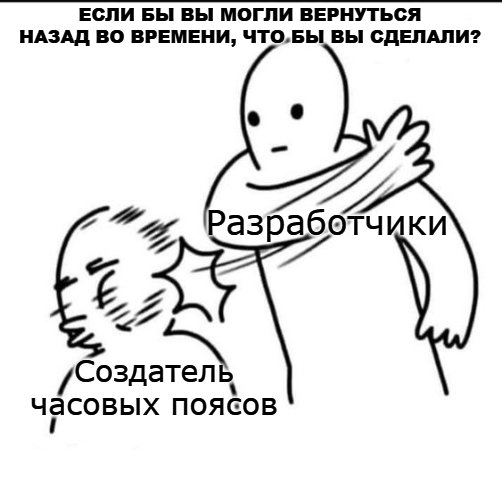

*Единое поясное время придумали железнодорожники в XIX веке, чтобы расписание поездов не сходило с ума. Расплачиваются за это программисты XXI века — и каждый хотя бы раз мечтал о машине времени ровно с этой целью.*

### Windows: `uv add tzdata`

И тут Windows подкладывает свинью. В Linux и macOS база часовых поясов IANA встроена в систему, а в Windows её нет: у Windows своя база, в другом формате, и `zoneinfo` её не понимает. Без неё `ZoneInfo("Europe/Moscow")` на Windows падает так же, как на любой системе падает несуществующий пояс:

In [131]:
ZoneInfo("Europe/Mordor")   # ⚠️ упадёт специально: нет такого пояса

ZoneInfoNotFoundError: 'No time zone found with key Europe/Mordor'

Выше — две ошибки подряд: `zoneinfo` поискал файл пояса, не нашёл (`FileNotFoundError`) и уже из-за этого бросил свою. Читаем, как всегда, последнюю строку: `ZoneInfoNotFoundError: 'No time zone found with key Europe/Mordor'`. На Windows то же самое вы получите для вполне реальной Москвы. Лечение — один раз в терминале проекта:

```
uv add tzdata
```

(В Miniforge — `pip install tzdata` в Miniforge Prompt.) `tzdata` — та самая база IANA в виде пакета Python, `zoneinfo` найдёт её сам. Если вы выполнили команду из начала лекции, она уже стоит — вместе с `emoji` и `pendulum`. Если в ДЗ3 у вас на Windows упадёт `zoneinfo` — вы теперь знаете почему.

## ISO 8601: как хранить время в файлах

Дату нужно записать в файл, в JSON, в лог. JSON вообще не знает, что такое `datetime`: `json.dumps(now)` упадёт с `TypeError`. Значит, превращаем в строку. Но в какую? «25.10.26»? «10/25/2026»? «двадцать пятое»?

Для этого есть международный стандарт **ISO 8601**: год-месяц-день, буква `T`, время, смещение. Такие строки понимают все языки программирования и все базы данных. А ещё, если все они в одном поясе (например, все в UTC), они правильно сортируются как обычные строки. Смешали `Z` и `+03:00` — и строковая сортировка соврёт: `"…T03:00+03:00"` встанет после `"…T01:00Z"`, хотя это на час раньше. Поэтому время сравнивают объектами `datetime`, а не строками. (В ДЗ3 пояса как раз смешаны.) В Python — `isoformat()` туда и `fromisoformat()` обратно:

In [132]:
meeting = datetime(2026, 11, 3, 14, 0, tzinfo=moscow)

text = meeting.isoformat()
print(text, type(text))

back = datetime.fromisoformat(text)
print(back, back == meeting)
print(datetime.fromisoformat("2026-11-03T11:00:00Z") == meeting)   # Z — это UTC

2026-11-03T14:00:00+03:00 <class 'str'>
2026-11-03 14:00:00+03:00 True
True


Строка ушла — объект вернулся, равенство `True`. Обратите внимание на последнюю строку: 11:00 по UTC (буква `Z` в конце — это UTC) и 14:00 по Москве — **один и тот же момент**, и Python это понимает. Буква `Z` в `fromisoformat` работает с Python 3.11.

Правило: **в файлы и JSON время пишем в ISO 8601, с часовым поясом.**

## Строки в даты и обратно: `strptime` и `strftime`

ISO — это когда данные делали хорошие люди. Чаще даты приходят в виде «25/12/2024» из Excel, «2023-03-15 22:05:10» из логов, «15.03.2023» от бухгалтерии. Такую строку разбирает `strptime` — *string parse time*. Ей нужны сама строка и **шаблон** — объяснение, где в строке что стоит. Шаблон собирается из кодов:

| Код | Что | Пример |
| :--- | :--- | :--- |
| `%d` | день месяца | 01 … 31 |
| `%m` | месяц числом | 01 … 12 |
| `%Y` | год, 4 цифры | 2026 |
| `%y` | год, 2 цифры | 26 |
| `%H` | часы, 24-часовой формат | 00 … 23 |
| `%M` | минуты | 00 … 59 |
| `%S` | секунды | 00 … 59 |

Всё, что не код, — разделители (`/`, `.`, `-`, пробел) — должно совпадать со строкой буква в букву.

*🎤 Таблицу вслух не читаем: показываем на экране и говорим «главные коды — `%d`, `%m`, `%Y`, `%H`, `%M`, `%S`, остальное — в документации».*

In [133]:
d1 = datetime.strptime("25/12/2024", "%d/%m/%Y")
d2 = datetime.strptime("2023-03-15 22:05:10", "%Y-%m-%d %H:%M:%S")
print(d1, "| год:", d1.year)
print(d2, "| час:", d2.hour)

2024-12-25 00:00:00 | год: 2024
2023-03-15 22:05:10 | час: 22


Строки превратились в объекты, из которых можно достать год и час, которые можно сравнивать и вычитать. Если строка не совпадает с шаблоном — `ValueError: time data '25.12.2024' does not match format '%d/%m/%Y'`. Это не страшно, это даже хорошо: значит, во входных данных мусор, и вы узнаете об этом сразу.

Обратная операция — `strftime`, *string format time*: объект → строка по тому же шаблону. Есть и коды для названий: `%B` — название месяца, `%A` — день недели.

In [134]:
print(now.strftime("%d.%m.%Y %H:%M"))
print(now.strftime("Сегодня %d %B %Y года, %A"))

26.10.2026 17:01
Сегодня 26 October 2026 года, Monday


Первая строка — то, что нужно. Во второй месяц и день недели — по-английски, вроде `October` и `Monday`: Python по умолчанию говорит по-английски. Переключить язык можно через модуль `locale`, но это глобальный переключатель для всей программы, и названия языков в Linux и Windows разные. Для пары строк проще и надёжнее сделать свой список — заодно и падеж будет правильный:

In [135]:
MONTHS = ["января", "февраля", "марта", "апреля", "мая", "июня",
          "июля", "августа", "сентября", "октября", "ноября", "декабря"]

print(f"Сегодня {now.day} {MONTHS[now.month - 1]} {now.year} года")

Сегодня 26 октября 2026 года


`now.month` — число от 1 до 12, а индексы списка — от 0, поэтому `- 1`. Старый друг из лекции про списки.

## Арифметика: `timedelta`

Разница между двумя моментами — это `timedelta`, «промежуток времени». Его можно прибавлять к датам и вычитать из них:

In [136]:
week = timedelta(days=7)
pair = timedelta(hours=1, minutes=30)
print(week, "|", pair)

print("Через неделю:", (now + week).strftime("%d.%m.%Y"))
print("Вчера было:  ", (now - timedelta(days=1)).strftime("%d.%m.%Y"))
print("Пара закончится в", (now + pair).strftime("%H:%M"))

7 days, 0:00:00 | 1:30:00
Через неделю: 02.11.2026
Вчера было:   25.10.2026
Пара закончится в 18:31


Python сам переходит через границы месяцев и годов: к 31 декабря прибавьте день — получите 1 января.

А теперь классика: сколько дней до Нового года. В прошлогодней версии этой лекции было написано `datetime(2026, 1, 1) - now`, а в подписи к ней стоял вообще другой год. Ошибка в подписи — ерунда. Хуже другое: дата **зашита в код**. С 1 января 2026 года эта ячейка начала показывать отрицательное число дней — и показывает до сих пор. Код, который работает сегодня и тихо врёт через два месяца, — худший вид кода. Считаем от сегодняшнего дня:

In [137]:
today = date.today()
new_year = date(today.year + 1, 1, 1)
left = new_year - today

print(f"Сегодня {today}, до Нового {new_year.year} года — {left.days} дн.")

Сегодня 2026-10-26, до Нового 2027 года — 67 дн.


`today.year + 1` — Новый год всегда следующий, в какой день ни запусти. Число у вас будет своё — и это правильно. Обратите внимание: `date` минус `date` — тоже `timedelta`, а `.days` достаёт из неё целое число дней.

Но есть то, чего `timedelta` не умеет: «плюс месяц». В нём есть недели, дни, часы, минуты и секунды, а месяцев нет. Потому что месяц — это не фиксированное число дней. Сколько будет 31 января плюс месяц? Подумайте, вернёмся к этому в конце.

## Час, который был дважды

А теперь обещанная жуть. В ночь на 25 октября 2026 года Европа перешла на зимнее время. В Берлине в 03:00 по летнему времени часы перевели на 02:00. То есть **час с 02:00 до 03:00 прошёл дважды**. Если ваш лог пишет «02:30 по Берлину» — это какое из двух 02:30?

Python различает их атрибутом `fold` — «складка»: `fold=0` — первый раз, `fold=1` — второй.

In [138]:
berlin = ZoneInfo("Europe/Berlin")

first = datetime(2026, 10, 25, 2, 30, tzinfo=berlin)   # fold=0 по умолчанию
second = first.replace(fold=1)

print(first, "→ UTC", first.astimezone(UTC))
print(second, "→ UTC", second.astimezone(UTC))

2026-10-25 02:30:00+02:00 → UTC 2026-10-25 00:30:00+00:00
2026-10-25 02:30:00+01:00 → UTC 2026-10-25 01:30:00+00:00


На часах одно и то же 02:30, но смещение разное: `+02:00` (ещё летнее время) и `+01:00` (уже зимнее). В UTC это 00:30 и 01:30 — **разные моменты с разницей в час**. А теперь спросим у Python, сколько между ними прошло. *🎤 Спросите зал до запуска.*

In [139]:
print("second - first =", second - first)
print("first == second:", first == second)
print("в UTC:          ", second.astimezone(UTC) - first.astimezone(UTC))

second - first = 0:00:00
first == second: True
в UTC:           1:00:00


Ноль. И «равны». Хотя между ними — целый час. Это не баг, это правило из документации: если оба объекта в **одном и том же** часовом поясе, Python сравнивает и вычитает их по настенным часам, не глядя на смещение. Настоящую разницу показывает только UTC.

Ещё одно следствие. Сколько часов было в сутках 25 октября в Берлине?

In [140]:
day_start = datetime(2026, 10, 25, tzinfo=berlin)
day_end = datetime(2026, 10, 26, tzinfo=berlin)

print("По настенным часам:", day_end - day_start)
print("На самом деле:     ", day_end.astimezone(UTC) - day_start.astimezone(UTC))

По настенным часам: 1 day, 0:00:00
На самом деле:      1 day, 1:00:00


Двадцать пять часов. «В сутках всегда 24 часа» — скажите это тем, кто чинил ночной биллинг или расписание будильников в ночь перевода часов.

Москва не переводит часы с 2014 года: последний раз час «был дважды» здесь 26 октября 2014-го. (В регионах бывало и позже: в Волгограде, например, час с 01:00 до 02:00 прошёл дважды 27 декабря 2020-го.) Так что дома такого почти не бывает. Но ваш сервер может стоять во Франкфурте, а пользователи — жить в Берлине. И эта ночь ждёт вас в ДЗ3.

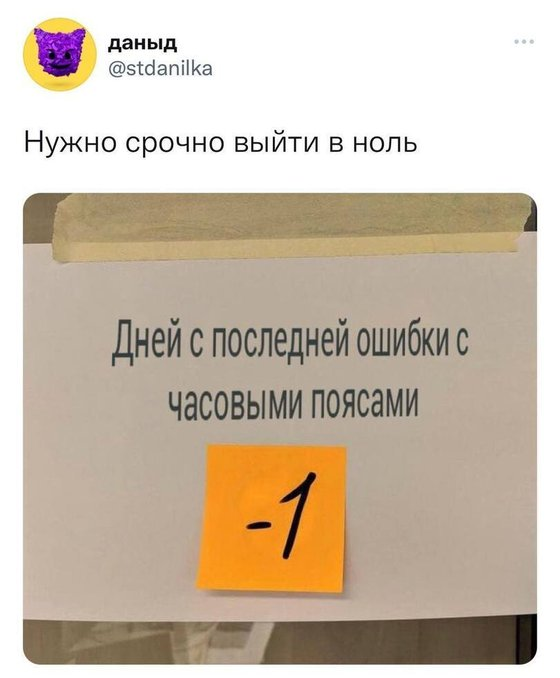

*Счётчик ушёл в минус на единицу — как часы в Берлине в ночь на 25 октября. Выйти в ноль можно одним способом: считать в UTC.*

### Главное правило

Отсюда главное правило всей темы:

- **храните и считайте время в UTC** (aware, `datetime.now(UTC)`);
- **часовой пояс — названием** через `zoneinfo`, а не «+3» руками;
- **переводите в местное время только для показа** человеку.

> 🤖 **Где ошибается ваш ИИ.** Попросите «текущее время в UTC» — и почти наверняка получите `datetime.utcnow()`: он возвращает **наивный** объект, который код дальше примет за местное время, и к тому же устарел с Python 3.12. Правильно — `datetime.now(UTC)`. Вторая классика — библиотека `pytz` и её `.localize(datetime.utcnow())`: момент молча уезжает на час-два. С Python 3.9 `pytz` не нужен (на Windows — только пакет `tzdata`): `datetime.now(ZoneInfo("Europe/Paris"))`.

## Pendulum: есть и такое

Последнее. Если стандартный `datetime` кажется вам неудобным, вы не одиноки. **Если бы `requests` и `datetime` решили создать библиотеку, это был бы Pendulum.** Он берёт на себя всю грязную работу с часовыми поясами, парсингом строк и арифметикой, и по умолчанию все его даты — осведомлённые. Помните вопрос про 31 января плюс месяц?

In [141]:
import pendulum

print(pendulum.now("Europe/Moscow"))
print(pendulum.datetime(2024, 1, 31).add(months=1))

2026-10-26 17:01:17.920466+03:00
2024-02-29 00:00:00+00:00


Первая строка — сейчас в Москве, сразу со смещением. Вторая — 29 февраля: Pendulum понял, что 31 февраля не бывает, и взял последний день месяца, а 2024 год високосный. В стандартной библиотеке «плюс месяц» нет вообще. Pendulum — сторонний пакет (`uv add pendulum`; если вы выполнили команду из начала лекции, он уже стоит), подробности — в разделе 📚 ниже, читаете дома.

## 🧨 Экстра: время — самый опасный тип данных

> Можно пропустить — тогда читаете дома.

Вы уже видели час, который был дважды. Вот ещё три истории.

**29 февраля 2012 года лёг Microsoft Azure.** Облачный сервис выдавал своим виртуальным машинам сертификаты сроком на год. Срок считался просто: «сегодняшняя дата, год плюс один». 29 февраля 2012 года плюс один год — это 29 февраля 2013-го, которого не существует. Сбой начался вечером 28 февраля по тихоокеанскому времени (в UTC уже наступило 29-е). В некоторых регионах сервисы лежали больше суток, Microsoft вернул клиентам 33 % месячной платы. Повторим на Python:

In [142]:
cert_start = datetime(2012, 2, 29)
cert_end = cert_start.replace(year=cert_start.year + 1)   # ⚠️ упадёт специально: «год плюс один»

ValueError: day is out of range for month

`day is out of range for month`. Python хотя бы честно падает. Код Azure был не на Python.

**19 января 2038 года, 03:14:07 UTC.** Многие системы хранят время как число секунд, прошедших с полуночи 1 января 1970 года по UTC, — это называется *Unix time*. Если для этого числа отведено 32 бита со знаком, максимум — 2³¹ − 1 = 2 147 483 647. Через 2 147 483 647 секунд после полуночи 1 января 1970 года наступит вот что:

In [143]:
print(datetime.fromtimestamp(2**31 - 1, UTC))           # последняя секунда 32-битного времени
print(datetime(1970, 1, 1, tzinfo=UTC) + timedelta(seconds=-2**31))   # куда «перескочит» счётчик

2038-01-19 03:14:07+00:00
1901-12-13 20:45:52+00:00


Следующая секунда в 32-битном счётчике станет отрицательным числом, и для таких систем наступит 13 декабря 1901 года. Python от этого не страдает — у него целые числа без ограничения, но встроенные устройства, старые базы данных и файловые системы — страдают. Проблема 2038 года — младшая сестра проблемы 2000 года.

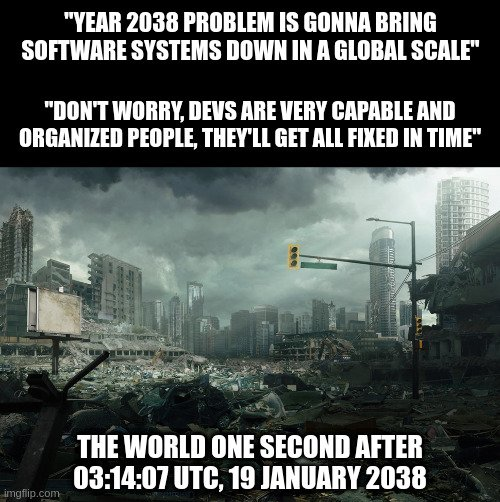

*«Разработчики — очень организованные люди, всё починят вовремя». Проблему 2000 года тоже чинили в последний момент. Посмотрите на две ячейки выше: до 03:14:07 UTC осталось меньше двенадцати лет.*

**Часовые пояса — это политика.** В марте 2011 года Россия перевела часы на летнее время — и больше назад не переводила: Москва жила по UTC+4 зиму и лето. В октябре 2014 года вернулась на UTC+3. Ни одна строчка кода не сломалась, но время сдвинулось. Проверим по базе `zoneinfo` — середина января разных лет:

In [144]:
for year in (2011, 2013, 2015):
    print(year, datetime(year, 1, 15, 12, 0, tzinfo=moscow).utcoffset())

2011 3:00:00
2013 4:00:00
2015 3:00:00


Три года — три ответа: +3, +4, +3. Если бы в 2013 году вы прибавляли к UTC «+3 вручную», вы бы весь год ошибались на час. А Самоа в декабре 2011 года перешло на другую сторону линии перемены дат и просто **пропустило** пятницу, 30 декабря. Там не было этой даты вообще.

И напоследок — весенний перевод часов. В ночь на 29 марта 2026 года в Берлине после 01:59 сразу наступило 03:00. Прибавим час к 01:30 «по-наивному»:

In [145]:
night = datetime(2026, 3, 29, 1, 30, tzinfo=berlin)

print(night + timedelta(hours=1))                                     # по настенным часам
print((night.astimezone(UTC) + timedelta(hours=1)).astimezone(berlin))   # через UTC

2026-03-29 02:30:00+01:00
2026-03-29 03:30:00+02:00


Первая строка — 02:30. Такого времени в Берлине в ту ночь **не было**: часы перепрыгнули с 02:00 сразу на 03:00. Вторая, через UTC, — правильные 03:30. Опять: считаем в UTC, показываем в местном.

Если захочется ещё — найдите статью Ноа Суссмана «Falsehoods programmers believe about time» (2012), «Заблуждения программистов о времени». Это список из нескольких десятков утверждений вроде «в минуте всегда 60 секунд» и «в сутках всегда 24 часа» — и каждое ложно. Прочитайте и проверьте, во сколько из них вы верили до этой лекции.

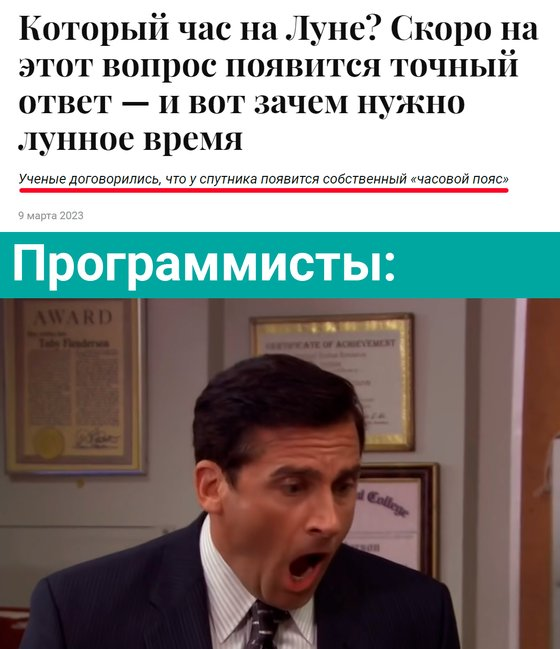

*Только вы выучили `Europe/Moscow`, как учёные договорились о собственном времени для Луны. Где-то в мире заорал, как Майкл Скотт, мейнтейнер базы часовых поясов.*

## 📚 Самостоятельно: Pendulum

Pendulum — сторонняя библиотека для дат (`uv add pendulum`; если выполнили команду из начала лекции — уже стоит). Его объекты — наследники обычного `datetime`, поэтому их можно передавать везде, где ждут `datetime`. Отличия от стандартной библиотеки: все даты по умолчанию осведомлённые, есть «плюс месяц», разбор строк без шаблонов и человеческие фразы вроде «3 дня назад».

Текущий момент — сразу с часовым поясом вашего компьютера:

In [146]:
import pendulum

now_p = pendulum.now()
print(now_p, "| пояс:", now_p.timezone_name)

2026-10-26 17:01:17.967748+03:00 | пояс: Europe/Moscow


Разбор строк. `parse` понимает ISO 8601 сам, а с `strict=False` пытается угадать и другие форматы. Но угадывает он по-американски, «месяц.день»: «05.01.2025» для него — 1 мая. «20.01.2025» он прочтёт верно только потому, что двадцатого месяца не бывает. Поэтому для дат вида «день.месяц» — только `from_format` с шаблоном, и коды в нём свои, не как в `strptime`: `DD.MM.YYYY HH:mm`. Без указания пояса Pendulum считает время по UTC.

In [147]:
print(pendulum.parse("2025-01-20T15:30:00"))
print(pendulum.parse("20.01.2025 15:30", strict=False))   # 20 января: повезло
print(pendulum.parse("05.01.2025 15:30", strict=False))   # а это уже 1 мая!
print(pendulum.from_format("05.01.2025 15:30", "DD.MM.YYYY HH:mm", tz="Europe/Moscow"))
print(pendulum.parse("January 20, 2025", strict=False).to_date_string())

2025-01-20 15:30:00+00:00
2025-01-20 15:30:00+00:00
2025-05-01 15:30:00+00:00
2025-01-05 15:30:00+03:00
2025-01-20


Третья и четвёртая строки разбирают одну и ту же «05.01.2025», а даты разные: 1 мая и 5 января. Ни ошибки, ни предупреждения — тихо и неправильно. `strptime` на чужой формат хотя бы честно падает, а `parse` угадывает.

Часовые пояса — названиями, перевод — методом `in_timezone`:

In [148]:
paris_now = pendulum.now("Europe/Paris")
print("Сейчас в Париже:", paris_now)

ny = pendulum.datetime(2025, 1, 1, 10, 0, 0, tz="America/New_York")
print("10 утра 1 января в Нью-Йорке — это в Токио:", ny.in_timezone("Asia/Tokyo"))

Сейчас в Париже: 2026-10-26 15:01:17.988844+01:00
10 утра 1 января в Нью-Йорке — это в Токио: 2025-01-02 00:00:00+09:00


Арифметика — методами `add` и `subtract`, с месяцами и годами. Цепочки читаются почти как текст:

In [149]:
print("Через неделю и два дня:", now_p.add(weeks=1, days=2).to_date_string())
print("Три месяца назад:      ", now_p.subtract(months=3).to_date_string())

print(pendulum.datetime(2024, 1, 31).add(months=1).to_date_string())   # 2024 — високосный
print(pendulum.datetime(2025, 1, 31).add(months=1).to_date_string())   # 2025 — нет

Через неделю и два дня: 2026-11-04
Три месяца назад:       2026-07-26
2024-02-29
2025-02-28


31 января плюс месяц — последний день февраля: 29-е в високосном году и 28-е в обычном. Стандартная библиотека так не умеет. Попытка сделать «тот же день, следующий месяц» через `replace` падает:

In [150]:
date(2024, 1, 31).replace(month=2)   # ⚠️ упадёт специально: 31 февраля нет

ValueError: day is out of range for month

«Плюс месяц» умеет ещё `relativedelta` из пакета `python-dateutil` — встретите в чужом коде.

Бонус — человеческий язык, в том числе русский:

In [151]:
pendulum.set_locale("ru")

print(pendulum.now().subtract(days=3).diff_for_humans())
print(pendulum.now().format("D MMMM YYYY, dddd"))

3 дня назад
26 октября 2026, понедельник


И чтобы вы не расслаблялись — вернёмся к берлинскому 02:30, которое было дважды. Стандартный `datetime` по умолчанию берёт **первое** (`fold=0`, `+02:00`). А Pendulum:

In [152]:
print(pendulum.datetime(2026, 10, 25, 2, 30, tz="Europe/Berlin"))

2026-10-25 02:30:00+01:00


`+01:00` — **второе**. Две уважаемые библиотеки по-разному отвечают на один и тот же вопрос. Время — самый опасный тип данных, я предупреждал.

# 10. Исключения: падаем изящно

Ошибок мы сегодня уже насмотрелись: `NameError`, `ValueError`, `ZoneInfoNotFoundError` — и каждая роняла ячейку с красной простынёй.

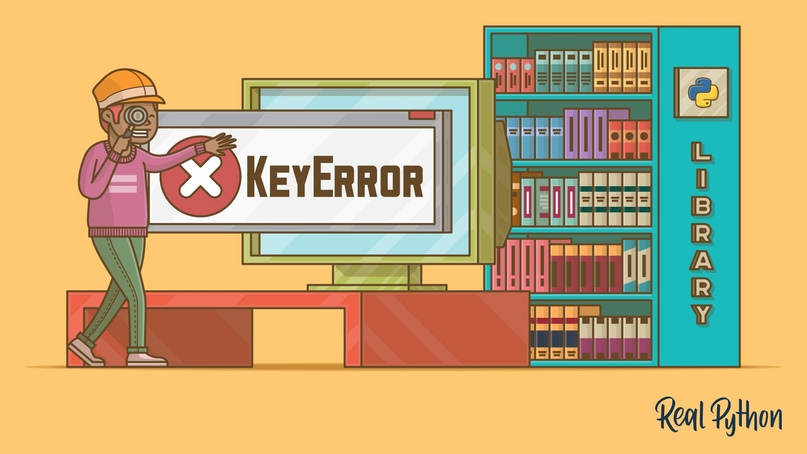

*Вот он, красный крестик. К концу раздела он будет появляться только тогда, когда вы сами этого захотите.*

Начну с фразы, которую стоит повесить над рабочим столом:

> **Хорошая программа — не та, что не падает, а та, что падает предсказуемо и изящно.**

До сих пор мы жили в идеальном мире. Файлы всегда существуют, пользователи всегда вводят числа, когда их просят, а делитель никогда не бывает нулём. В реальном мире всё ломается постоянно. Файл удалил коллега. Пользователь вместо «42» написал «сорок два» — потому что может. Сеть отвалилась ровно в момент сохранения. И что делает наша программа? Падает с красной простынёй и умирает. Посреди работы, не сохранив ничего. Это грубо и непрофессионально.

В прошлый раз, в разделе про пять ошибок, мы роняли Python специально и учились **читать** трейсбек. Сегодня учимся ошибки **ловить**.

Аналогия, которая всё объясняет. Конструкция `try … except` — это ваш **план Б**:
- `try` (попробовать): «я **попробую** поехать по главной дороге»;
- `except` (в случае): «но **если вдруг** там пробка — `except ProбкаError` — поеду по объездной».

Вместо того чтобы бросить машину посреди трассы при первой же пробке, мы заранее продумываем объезд. Кто заметил, что в `ProбкаError` латиница перемешана с кириллицей, — молодцы, внимательные. Так писать нельзя, а шутить можно.

## Сначала — боль

Три классических падения. Все три вы уже видели или скоро увидите в своём коде. Каждая ячейка падает специально.

In [153]:
int("привет")   # ⚠️ упадёт специально: текст в число не превращается

ValueError: invalid literal for int() with base 10: 'привет'

In [154]:
10 / 0   # ⚠️ упадёт специально: на ноль не делим даже в Python

ZeroDivisionError: division by zero

In [155]:
with open("L3_files/no_such_file.txt", encoding="utf-8") as f:   # ⚠️ упадёт специально: файла нет
    content = f.read()

FileNotFoundError: [Errno 2] No such file or directory: 'L3_files/no_such_file.txt'

Три разных типа: `ValueError`, `ZeroDivisionError`, `FileNotFoundError`. Тип ошибки — последняя строка трейсбека, вы это уже умеете читать. Сейчас мы будем ловить их по именам.

## `try … except`: план Б

Схема такая:
```python
try:
    ...   # «опасный» код, который МОЖЕТ упасть
except ТипОшибки:
    ...   # выполнится, ТОЛЬКО если в try упала ошибка именно этого типа
```
Python выполняет `try` строчку за строчкой. Всё прошло гладко — блок `except` пропускается целиком, как будто его нет. Где-то внутри `try` вылетела ошибка нужного типа — Python бросает недоделанный `try` прямо на этой строчке, прыгает в `except` и после него спокойно идёт дальше. Программа не падает.

Вылечим первый пример. В настоящей программе тут был бы `input()`, но чтобы не вводить руками на лекции, подставим ответы двух разных пользователей — нормального и творческого:

In [156]:
for user_input in ["42", "сорок два"]:
    try:
        number = int(user_input)
        print(f"Отлично! Квадрат числа {number} — {number ** 2}.")
    except ValueError:
        print(f"«{user_input}» — это не число. Цифрами, пожалуйста.")

print("Программа дожила до конца.")

Отлично! Квадрат числа 42 — 1764.
«сорок два» — это не число. Цифрами, пожалуйста.
Программа дожила до конца.


Первый пользователь получил квадрат, второй — вежливый отказ, а программа дожила до последней строчки. Обратите внимание: во втором проходе строка с `print("Отлично!…")` **не выполнилась**. `int()` упал, и всё, что было в `try` ниже него, пропущено.

И закроем старый долг. В ДЗ1 я разрешил вашей программе падать, если вместо номера месяца пользователь напишет «две тысячи», — ловить такое, сказал я, научимся в следующей лекции. Вот, научились: теперь вы можете поймать «две тысячи» и в ДЗ1. Переделывать не обязательно, но на защите спрошу, как бы вы это сделали.

> 🤖 **Где ошибается ваш ИИ.** «`try/except` — ресурсоёмкая конструкция, лучше заранее проверить всё через `if`». Это старый миф. С Python 3.11 `try` почти ничего не стоит, пока ошибки нет («zero-cost exceptions»), дорого обходится только само падение. А проверка «файл существует? — тогда открываю» ещё и ненадёжна: между проверкой и открытием файл успеют удалить. В Python принято наоборот: **попробуй и поймай**, если не вышло.

## Врач, а не «таблетка от всего»

Блоков `except` может быть несколько — по одному на каждый тип ошибки. Это гораздо лучше, чем ловить всё подряд одной сетью.

Представьте, что вы врач. К вам приходит пациент. Хороший врач не выдаёт каждому одну и ту же «универсальную таблетку от всего». Он ставит диагноз и назначает лечение:
- диагноз `ValueError` («неверное значение») → лечение: сказать пользователю, что нужно ввести число;
- диагноз `ZeroDivisionError` («деление на ноль») → лечение: сказать, что на ноль делить нельзя.

А «таблетка от всего» — это врач, который всем подряд прописывает активированный уголь. Пациент с переломом тоже получит уголь. Вылечится? Ну, может быть, сам.

И ещё один блок — `else`. Он выполняется, **только если в `try` ничего не упало**. Зачем он, если можно просто дописать код в конец `try`? Затем, что `try` должен быть узким: в нём — только то, что может упасть и что вы собираетесь ловить. Если положить туда ещё и печать результата, то ошибка в печати попадёт в чужой `except` и получит чужой диагноз. Получится врач, который из-за вашей простуды наложит гипс.

In [157]:
def divide(a_text, b_text):
    try:
        result = int(a_text) / int(b_text)
    except ValueError:
        print(f"{a_text} / {b_text}: вводите целые числа, а не вот это.")
    except ZeroDivisionError:
        print(f"{a_text} / {b_text}: на ноль делить нельзя. Даже в МИСИС.")
    else:
        print(f"{a_text} / {b_text} = {result:.2f}")


divide("10", "4")
divide("10", "ноль")
divide("10", "0")

10 / 4 = 2.50
10 / ноль: вводите целые числа, а не вот это.
10 / 0: на ноль делить нельзя. Даже в МИСИС.


Три вызова — три разных исхода: успех ушёл в `else`, кривой ввод — в `except ValueError`, ноль — в `except ZeroDivisionError`. Каждый получил свой диагноз.

Если две ошибки нужно лечить одинаково, их можно перечислить **в скобках**, кортежем: `except (ValueError, ZeroDivisionError):`. Скобки в Python 3.13 обязательны, к скобкам мы ещё вернёмся в самостоятельном блоке.

## Родословная ошибок

Ошибки в Python — не просто разрозненные имена. Они выстроены в родословное дерево: у каждой есть родитель, у родителя — свой родитель, и так до самого верха. И `except` ловит не только указанный тип, но и **всех его потомков**. Посмотрим на родословную нескольких знакомых нам ошибок:

In [158]:
for error_type in [ZeroDivisionError, KeyError, FileNotFoundError, UnicodeDecodeError, KeyboardInterrupt]:
    parents = [cls.__name__ for cls in error_type.__mro__[1:-1]]
    print(f"{error_type.__name__:20} ← {' ← '.join(parents)}")

ZeroDivisionError    ← ArithmeticError ← Exception ← BaseException
KeyError             ← LookupError ← Exception ← BaseException
FileNotFoundError    ← OSError ← Exception ← BaseException
UnicodeDecodeError   ← UnicodeError ← ValueError ← Exception ← BaseException
KeyboardInterrupt    ← BaseException


Что такое `__mro__` — расскажу в следующей лекции, про классы. Сейчас это просто «цепочка родителей», читаем слева направо: ребёнок ← родитель ← дедушка.

Главное, что тут видно:
- На самом верху у всех — `BaseException`. Под ним — `Exception`, родитель почти всех «обычных» ошибок.
- `ZeroDivisionError` — частный случай `ArithmeticError`, `KeyError` — частный случай `LookupError` (там же живёт `IndexError`), `FileNotFoundError` — частный случай `OSError`.
- `UnicodeDecodeError` — ошибка кодировки — внезапно ребёнок `ValueError`. Запомните этот факт: через десять минут, в практике, он испортит нам жизнь.
- А `KeyboardInterrupt` — это **не** `Exception`. Он висит прямо под `BaseException`. Это не случайность, сейчас увидите, зачем так сделано.

Полное дерево — в документации: [docs.python.org/3.13/library/exceptions.html#exception-hierarchy](https://docs.python.org/3.13/library/exceptions.html#exception-hierarchy). Наизусть его не учат. Открывают, когда нужно.

## `except Exception as e`: поймать всё «обычное»

Иногда вы действительно не знаете, что может сломаться, а падать нельзя. Тогда ловят родителя всех обычных ошибок — `Exception`. А `as e` кладёт саму пойманную ошибку в переменную. По традиции её зовут `e`, от *exception*. Из неё можно достать тип и текст:

In [159]:
def risky(value):
    try:
        print(f"  результат: {100 / value}")
    except Exception as e:
        print(f"  поймали {type(e).__name__}: {e}")


for value in [4, 0, "четыре", None]:
    print(f"risky({value!r})")
    risky(value)

risky(4)
  результат: 25.0
risky(0)
  поймали ZeroDivisionError: division by zero
risky('четыре')
  поймали TypeError: unsupported operand type(s) for /: 'int' and 'str'
risky(None)
  поймали TypeError: unsupported operand type(s) for /: 'int' and 'NoneType'


Одна сеть — три разные рыбы: деление на ноль и две ошибки `TypeError` с разным текстом. Сам текст ошибки, `{e}`, — то же самое, что вы видели в последней строке трейсбека.

Пользоваться этим — с осторожностью. Это и есть «таблетка от всего». Оправдана она в одном месте: на самом верху программы, где лучше записать «что-то сломалось, вот что именно» и аккуратно закончить работу, чем упасть молча. Внутри функций ловите конкретные ошибки, которые вы **ожидаете**.

## Почему не голый `except:`

Можно написать вообще без типа — `except:`. Python разрешает. Такой `except` ловит **всё**, вплоть до `BaseException`. А значит, и `KeyboardInterrupt` — ту самую ошибку, которую Python бросает, когда вы жмёте **Ctrl+C** в терминале. В VS Code в тетрадке то же самое делает кнопка **Interrupt** (квадратик ■ на панели). И `SystemExit` — его бросает `sys.exit()`, когда программа хочет штатно завершиться.

Смотрите, что будет. Функция качает 10 гигабайт котиков, вы поняли, что зря, и жмёте Ctrl+C. Нажимать по-настоящему я не буду, сымитирую нажатие строчкой `raise KeyboardInterrupt` — что такое `raise`, разберём через пару минут.

In [160]:
def download_cats():
    for attempt in range(1, 4):
        try:
            print(f"Попытка {attempt}: качаю 10 ГБ котиков...")
            raise KeyboardInterrupt   # имитируем: вы нажали Ctrl+C
        except:                       # так НЕ надо
            print("  Что-то пошло не так. Не сдаюсь, пробую ещё раз!")
    print("Докачал. Ваш Ctrl+C? Не, не слышал.")


download_cats()

Попытка 1: качаю 10 ГБ котиков...
  Что-то пошло не так. Не сдаюсь, пробую ещё раз!
Попытка 2: качаю 10 ГБ котиков...
  Что-то пошло не так. Не сдаюсь, пробую ещё раз!
Попытка 3: качаю 10 ГБ котиков...
  Что-то пошло не так. Не сдаюсь, пробую ещё раз!
Докачал. Ваш Ctrl+C? Не, не слышал.


Вы три раза нажали Ctrl+C, а программа три раза сделала вид, что ничего не было. В жизни там был бы не цикл на три попытки, а `while True`, и остановить такую программу можно только одним способом: закрыть терминал. В тетрадке — перезапустить ядро и потерять все переменные.

Теперь то же самое, но с `except Exception`:

In [161]:
def download_cats_v2():
    for attempt in range(1, 4):
        try:
            print(f"Попытка {attempt}: качаю 10 ГБ котиков...")
            raise KeyboardInterrupt   # имитируем: вы нажали Ctrl+C
        except Exception:
            print("  Что-то пошло не так. Не сдаюсь, пробую ещё раз!")
    print("Докачал.")


try:
    download_cats_v2()
except KeyboardInterrupt:
    print("Ctrl+C пролетел мимо except Exception. Программа остановилась, как вы и просили.")

Попытка 1: качаю 10 ГБ котиков...


Ctrl+C пролетел мимо except Exception. Программа остановилась, как вы и просили.


`KeyboardInterrupt` — не `Exception`, поэтому `except Exception` его не тронул, и программа остановилась на первой же попытке. Внешний `try` тут только для того, чтобы ячейка не покраснела: без него Python просто остановился бы, как и положено после Ctrl+C.

Вот ради этого `KeyboardInterrupt` и вынесли из-под `Exception`: чтобы «поймать всё обычное» не означало «запретить пользователю остановить программу». Правило простое: **голый `except:` не пишем никогда**. Нужно поймать всё — `except Exception as e`.

И самый страшный родственник голого `except` — вот такой:
```python
try:
    process_payment()
except Exception:
    pass   # ¯\_(ツ)_/¯
```
Ошибку поймали и выкинули, никому не сказав. Программа делает вид, что всё в порядке, а данных нет. Платёж не прошёл, а в логах тишина, и через месяц вы ищете, куда делись деньги.

> 🤖 **Где ошибается ваш ИИ.** Попросите нейросеть «сделать код надёжнее» — и она обернёт всё подряд в `try: … except Exception: pass` или в `except Exception as e: print(e)` и продолжит работу как ни в чём не бывало. Это не надёжность, а заметание мусора под ковёр. Ошибку, с которой вы не знаете, что делать, **не ловят** — пусть программа упадёт громко, и вы увидите трейсбек.

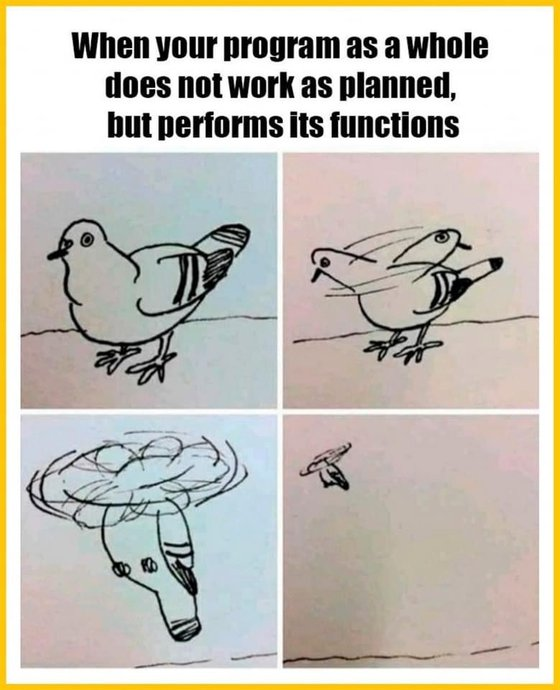

*Вот что получается из `except Exception: pass`. Программа в целом работает не так, как задумано, но свои функции выполняет: голубь превратился в вертолёт и улетел, ошибок в консоли — ноль. Ни одного красного трейсбека, ни одного живого голубя.*

## `finally`: выключить свет, даже уходя через окно

Бывает код, который должен выполниться **в любом случае**: была ошибка или нет, поймали её или нет. Закрыть файл, разорвать соединение с базой, вернуть принтер в очередь. Для этого есть блок `finally`.

Тут обычно возникает резонный вопрос: а чем `finally` отличается от кода, который просто написан после всего блока `try`? Он ведь тоже выполнится в конце. Хорошее наблюдение. Для простых случаев — ничем. Но `finally` становится незаменимым, когда выход из блока **нестандартный**: `return` прямо из `try`, `return` из `except`, `break` или ошибка, которую никто не поймал.

**Золотое правило:** код в `finally` — последнее, что выполнится перед выходом из блока, **как бы вы ни выходили**.

Аналогия. Блок `try … except` — это комната, в которой вы работаете.
- Код **после** блока — дела, которые вы сделаете, если доработаете до конца и спокойно выйдете в коридор.
- Код в **`finally`** — правило «выключить свет перед уходом». Неважно, как вы покидаете комнату: доработали до конца; сорвались посреди дела, потому что позвали (`return`, `break`); или выпрыгнули **в окно**, потому что в коридоре пожар (необработанная ошибка). Квартира горит, вы прыгаете со второго этажа, — но свет выключен. Счёт за электричество сам себя не оплатит.

Проверим. Две версии одной функции: в первой «выключить свет» написано просто после блока, во второй — в `finally`.

In [162]:
# --- Версия 1: Используем "код после" ---
def check_division_v1(a, b):
    """Пытается поделить. Код очистки находится ПОСЛЕ блока."""
    try:
        print("V1: Пытаюсь выполнить деление...")
        result = a / b
        print("V1: Деление успешно.")
        return result
    except ZeroDivisionError:
        print("V1: Ошибка! Деление на ноль.")
        return None
    # Этот код НЕ ВЫПОЛНИТСЯ, если сработал `return` в `try` или `except`
    print("V1: --- Завершение операции ---")

In [163]:
# --- Версия 2: Используем `finally` ---
def check_division_v2(a, b):
    """Пытается поделить. Код очистки находится в `finally`."""
    try:
        print("V2: Пытаюсь выполнить деление...")
        result = a / b
        print("V2: Деление успешно.")
        return result
    except ZeroDivisionError:
        print("V2: Ошибка! Деление на ноль.")
        return None
    finally:
        # Этот код ВЫПОЛНИТСЯ ВСЕГДА перед выходом из функции.
        print("V2: --- Завершение операции (finally) ---")

Сначала — обычное деление. Функция уходит по `return` прямо из `try`: сорвалась посреди дела, до коридора не дошла:

In [164]:
print("V1 вернула:", check_division_v1(10, 2))
print("-" * 30)
print("V2 вернула:", check_division_v2(10, 2))

V1: Пытаюсь выполнить деление...
V1: Деление успешно.
V1 вернула: 5.0
------------------------------
V2: Пытаюсь выполнить деление...
V2: Деление успешно.
V2: --- Завершение операции (finally) ---
V2 вернула: 5.0


Видите? У V1 строчки «Завершение операции» нет вообще. `return result` вышел из функции сразу, и код после блока так и остался ненапечатанным. У V2 `finally` сработал **перед** возвратом: сначала напечаталось «Завершение операции (finally)», а уже потом — «V2 вернула: 5.0», потому что этот `print` снаружи получает значение только после того, как функция полностью закончилась.

Теперь делим на ноль — уходим через `return None` из `except`, тоже не дойдя до коридора:

In [165]:
print("V1 вернула:", check_division_v1(10, 0))
print("-" * 30)
print("V2 вернула:", check_division_v2(10, 0))

V1: Пытаюсь выполнить деление...
V1: Ошибка! Деление на ноль.
V1 вернула: None
------------------------------
V2: Пытаюсь выполнить деление...
V2: Ошибка! Деление на ноль.
V2: --- Завершение операции (finally) ---
V2 вернула: None


Та же картина: V1 опять не выключила свет, V2 — выключила.

А теперь — через окно. Передадим вместо числа строку. Будет `TypeError`, а ловит наша функция только `ZeroDivisionError`. Ошибку не поймает никто.

*🎤 Спросите зал до запуска: напечатается ли «Завершение операции (finally)», если функция падает с непойманной ошибкой?*

In [166]:
check_division_v2(10, "два")   # ⚠️ упадёт специально: TypeError никто не ловит

V2: Пытаюсь выполнить деление...
V2: --- Завершение операции (finally) ---


TypeError: unsupported operand type(s) for /: 'int' and 'str'

Программа упала, трейсбек на месте — но **перед** трейсбеком стоит «V2: --- Завершение операции (finally) ---». Комната горит, мы в окне, свет выключен. Вот это и есть гарантия `finally`. Стрелка `--->` здесь, кстати, показывает на строчку из `finally`. Это причуда Jupyter: ядро рисует стрелку по последней выполненной строке, а последним выполнился `finally`. Запустите то же самое скриптом через `uv run`, и стрелка встанет на `result = a / b`, где ошибка и случилась. Что сломалось на самом деле, как всегда, — в последней строке: `TypeError`, делим число на строку.

Где это нужно в жизни? Везде, где вы что-то **взяли** и обязаны **вернуть**: открытый файл, соединение с базой данных, сетевое подключение, блокировка, которую ждут другие. Если не вернуть — ресурсы утекают, файлы остаются заблокированными (Windows это особенно любит), а база через час говорит «слишком много подключений».

И вот теперь понятно, что на самом деле делает `with open(...)` из раздела про файлы. Это та же конструкция, только красиво упакованная:
```python
f = open("L3_files/notes.txt", "w", encoding="utf-8")
try:
    f.write("hello")
finally:
    f.close()   # закроется, даже если write упадёт
```
Поэтому `with` и пишем: чтобы не писать каждый раз `try/finally` руками.

Последнее про `finally`. **Никогда не пишите `return` внутри `finally`.** Он молча проглатывает любую ошибку:

In [167]:
def everything_is_fine():
    try:
        return 1 / 0
    finally:
        return "всё хорошо"   # так НЕ делать


print(everything_is_fine())

всё хорошо


Деление на ноль было, а функция вернула «всё хорошо». Ошибка исчезла без следа. Ловушка настолько коварная, что в Python 3.14 на такой код уже выдаётся предупреждение `SyntaxWarning: 'return' in a 'finally' block` (PEP 765). У вас 3.13 — он промолчит, так что помнить придётся самим.

## `raise`: бросаем ошибку сами

До сих пор ошибки бросал Python, а мы ловили. Но свои функции тоже должны уметь сказать «так нельзя». Для этого есть `raise`:
```python
raise ValueError("что именно не так")
```
Зачем бросать ошибку, если можно напечатать «ошибка!» и вернуть `None`? Вспомните «крикнул vs бумажка» из первого раздела. `print` — это крик в пустоту: функция что-то прокричала, а вызывающий код получил `None` и поехал дальше с мусором. `raise` — это пожарная сирена: тот, кто вызвал функцию, **обязан** отреагировать — поймать и решить, что делать. А если никто не поймал, программа остановится и скажет, где и почему. Функция не знает, что вы захотите сделать с ошибкой. Её дело — сообщить.

Помните дыру в `get_final_price` из раздела 1? Скидка 150 % — и функция молча вернула бы минус пятьдесят рублей, магазин доплачивает покупателю. Закрываем. Одна проверка в начале функции:

In [168]:
def get_final_price(initial_price: float, discount_percent: float = 20) -> float:
    """Считает итоговую цену товара со скидкой (в процентах, от 0 до 100)."""
    if not 0 <= discount_percent <= 100:
        raise ValueError(f"скидка {discount_percent} % — так не бывает, допустимо от 0 до 100")
    return initial_price * (1 - discount_percent / 100)


print(get_final_price(100, 15))

85.0


Нормальная скидка считается как раньше: 85 рублей. А теперь маркетинг в ударе:

In [169]:
get_final_price(100, 150)   # ⚠️ упадёт специально: такой скидки не бывает

ValueError: скидка 150 % — так не бывает, допустимо от 0 до 100

`ValueError: скидка 150 % — так не бывает, допустимо от 0 до 100`. Минус пятидесяти рублей больше нет: функция отказалась считать чушь и объяснила почему. С приоритетом `"писец как срочно"` из раздела 2 — то же самое, одна строчка в начале `send_email`: `if priority not in {"low", "normal", "high"}: raise ValueError(...)`. Проверить входные данные и громко отказаться — это и есть обещанный способ заставить функцию возмутиться.

Теперь пример, который вам очень пригодится в домашке. Напишем функцию, которая разбирает одну строку лога — журнала, куда сервер записывает, что с ним происходит. Строка выглядит так: `2026-10-25 02:30:00 | ERROR | Нет связи с базой`. Время, уровень важности, сообщение.

In [170]:
from datetime import datetime

LEVELS = {"DEBUG", "INFO", "WARNING", "ERROR", "CRITICAL"}


def parse_log_line(line: str) -> tuple[datetime, str, str]:
    """Разбирает строку вида '2026-10-25 02:30:00 | ERROR | Нет связи с базой'."""
    parts = line.strip().split(" | ", maxsplit=2)
    if len(parts) != 3:
        raise ValueError(f"ожидал 3 части через ' | ', а нашёл {len(parts)}")
    moment_text, level, message = parts
    if level not in LEVELS:
        raise ValueError(f"неизвестный уровень {level!r}")
    moment = datetime.fromisoformat(moment_text)   # кривую дату fromisoformat отвергнет сам — тоже ValueError
    return moment, level, message


print(parse_log_line("2026-10-25 02:30:00 | ERROR | Нет связи с базой"))

(datetime.datetime(2026, 10, 25, 2, 30), 'ERROR', 'Нет связи с базой')


Нормальная строка разобрана в кортеж: настоящий `datetime`, уровень и сообщение. Обратите внимание на `maxsplit=2`: режем не больше двух раз, так что если в самом сообщении встретится « | », оно не развалится на куски.

А теперь — строка, в которой кто-то опечатался в уровне:

In [171]:
parse_log_line("2026-10-25 02:31:00 | EROR | Нет связи с базой")   # ⚠️ упадёт специально

ValueError: неизвестный уровень 'EROR'

Последняя строка трейсбека — `ValueError: неизвестный уровень 'EROR'`. Это **наш** текст. Мы сами решили, что это ошибка, и сами объяснили почему. Сообщение пишите для человека: что ожидали и что получили. «Ошибка!» — это не сообщение. «неизвестный уровень 'EROR'» — сообщение.

А вот как такую функцию используют. Тот, кто читает весь лог, ловит `ValueError` и решает, что с битой строкой делать. Например, откладывает её в сторонку вместе с причиной:

In [172]:
log_lines = [
    "2026-10-25 02:30:00 | ERROR | Нет связи с базой",
    "2026-10-25 02:31:00 | EROR | Нет связи с базой",
    "кот прошёлся по клавиатуре",
    "2026-10-25 02:61:00 | INFO | Связь восстановлена",
    "2026-10-25 02:45:00 | INFO | Связь восстановлена",
]

parsed, bad_lines = [], []
for number, line in enumerate(log_lines, start=1):
    try:
        parsed.append(parse_log_line(line))
    except ValueError as e:
        bad_lines.append((number, str(e)))

print("Разобрано строк:", len(parsed))
for number, reason in bad_lines:
    print(f"  строка {number}: {reason}")

Разобрано строк: 2
  строка 2: неизвестный уровень 'EROR'
  строка 3: ожидал 3 части через ' | ', а нашёл 1
  строка 4: minute must be in 0..59


Две строки разобраны, три отложены — и про каждую понятно, чем она плоха. Опечатка в уровне — наш `raise`. «Кот прошёлся по клавиатуре» — тоже наш: частей одна, а не три. А 02:61 — это уже `fromisoformat` бросил свой `ValueError`, и мы его поймали тем же `except`, потому что тип тот же.

Запомните эту схему: **маленькая функция разбирает одну строку и бросает `ValueError`; большой цикл ловит и складывает битые строки с причиной.** Ровно это вы будете делать в ДЗ3 — только логов будет побольше, а грязи в них — значительно больше.

В самостоятельном блоке ниже — ещё три штуки для тех, кому мало: группы исключений, заметки к ошибкам и `except` без скобок из Python 3.14.

## 📚 Самостоятельно: группы исключений, заметки и `except` без скобок

**Заметки к ошибке — `add_note()`** (с Python 3.11). Бывает, что функция, которая поймала ошибку, знает что-то полезное, чего не знал тот, кто её бросил. Например, `parse_log_line` не знает, из какого файла и с какой строки её позвали, а цикл — знает. Можно приклеить к ошибке заметку и бросить её дальше. Голый `raise` без аргументов внутри `except` означает «бросить ту же ошибку дальше, как была»:

In [173]:
try:
    parse_log_line("2026-10-25 02:31:00 | EROR | Нет связи с базой")
except ValueError as e:
    e.add_note("файл: api.log, строка 17")
    raise   # ⚠️ упадёт специально: бросаем ту же ошибку дальше, уже с заметкой

ValueError: неизвестный уровень 'EROR'

Заметка напечаталась в трейсбеке сразу под текстом ошибки.

**Группы исключений — `ExceptionGroup` и `except*`** (тоже с 3.11). Обычно ошибка одна: упала — дальше не идём. Но иногда надо сначала проверить всё, а потом сообщить обо всех проблемах разом. Например, проверить все строки лога. Для этого ошибки складывают в группу, а ловят через `except*` — со звёздочкой. Такой `except*` забирает из группы все ошибки нужного типа:

In [174]:
errors = []
for number, line in enumerate(log_lines, start=1):
    try:
        parse_log_line(line)
    except ValueError as e:
        e.add_note(f"строка {number}")
        errors.append(e)

try:
    if errors:
        raise ExceptionGroup("в логе есть битые строки", errors)
except* ValueError as group:
    print(f"Битых строк: {len(group.exceptions)}")
    for e in group.exceptions:
        print(f"  {e.__notes__[0]}: {e}")

Битых строк: 3
  строка 2: неизвестный уровень 'EROR'
  строка 3: ожидал 3 части через ' | ', а нашёл 1
  строка 4: minute must be in 0..59


В повседневном коде группы встречаются редко — в основном в асинхронном программировании, где десять задач могут упасть одновременно. Но знать, что они есть, полезно: однажды вы увидите в трейсбеке `ExceptionGroup` и не испугаетесь.

**`except` без скобок — Python 3.14** (PEP 758). Выше я говорил, что несколько типов в `except` надо брать в скобки. В Python 3.14 скобки можно опустить:
```python
try:
    result = int(a_text) / int(b_text)
except ValueError, ZeroDivisionError:          # Python 3.14+: можно так
    print("что-то не так с числами")
except (TypeError, OverflowError) as e:        # а с `as` скобки нужны по-прежнему
    print(e)
```
В Python 3.13 первая строка `except` — это `SyntaxError: multiple exception types must be parenthesized`. Поэтому в нашем курсе пишем со скобками: так работает везде.

У этой истории есть ирония. В Python 2 строка `except ValueError, e:` означала совсем другое: «поймай `ValueError` и положи его в переменную `e`». В Python 3 это запретили как раз из-за путаницы. А через 17 лет запятая вернулась — уже с новым смыслом. Если ИИ-ассистент выдаст вам `except ValueError, e:`, это он вспомнил Python 2, а не выучил 3.14.

# 11. Практика: функция, которая не падает

Соберём вместе функции, файлы и исключения. Задание:

Напишите **надёжную** функцию `read_number_from_file(filepath)`. Она должна:
1. Принимать путь к файлу.
2. Открыть файл и прочитать первую строку — `f.readline()` из раздела 5.
3. Превратить эту строку в целое число и вернуть его.
4. Если файла нет — не падать, а напечатать «файл не найден» и вернуть `None`.
5. Если в файле не число, а текст — тоже не падать, а напечатать «в файле не целое число» и вернуть `None`.
6. На любую другую неожиданность — напечатать, что случилось, и вернуть `None`.

И с подписью типов, как в разделе 1: принимает строку или `Path`, возвращает число или ничего — `str | Path` и `int | None`.

*🎤 Дайте залу пару минут набросать решение самим, потом показывайте.*

Вот решение. Обратите внимание на порядок `except`: сначала конкретные ошибки, которые мы ждём, и только последним — `Exception` как страховка.

In [175]:
from pathlib import Path


def read_number_from_file(filepath: str | Path) -> int | None:
    """Читает целое число из первой строки файла. Возвращает int или None, если что-то пошло не так."""
    try:
        with open(filepath, encoding="utf-8") as f:
            line = f.readline()
        return int(line.strip())
    except FileNotFoundError:
        print(f"  файл {filepath!r} не найден")
        return None
    except ValueError:
        print(f"  в файле {filepath!r} не целое число")
        return None
    except Exception as e:
        print(f"  другая ошибка — {type(e).__name__}: {e}")
        return None

Теперь тестовые файлы. Создадим их прямо тут, в папке `L3_files`: один с числом, другой с текстом. Третьего файла не будет вовсе — это тоже тест.

In [176]:
Path("L3_files/good_number.txt").write_text("123\n", encoding="utf-8")
Path("L3_files/bad_number.txt").write_text("привет\n", encoding="utf-8")

for path in ["L3_files/good_number.txt", "L3_files/bad_number.txt", "L3_files/no_such_file.txt"]:
    print(f"{path}:")
    print("  результат:", read_number_from_file(path))

L3_files/good_number.txt:
  результат: 123
L3_files/bad_number.txt:
  в файле 'L3_files/bad_number.txt' не целое число
  результат: None
L3_files/no_such_file.txt:
  файл 'L3_files/no_such_file.txt' не найден
  результат: None


Три файла — три исхода, и ни одного красного трейсбека. Хороший файл вернул `123`, текстовый — `None` с объяснением, несуществующий — `None` с объяснением.

А теперь проверим третью ветку, `except Exception`. Что будет, если вместо файла передать **папку**?

In [177]:
print("результат:", read_number_from_file("L3_files"))

  другая ошибка — IsADirectoryError: [Errno 21] Is a directory: 'L3_files'
результат: None


Ни `FileNotFoundError`, ни `ValueError` — папка существует, она просто не файл. Сработала страховка. Что именно она напечатает, зависит от системы: на Windows — `PermissionError: … Permission denied`, на Linux и macOS — `IsADirectoryError: … Is a directory`. Windows папку как файл открыть не даёт и объясняет это по-своему, Linux — по-своему, но страховке всё равно: она ловит обе. Для таких случаев, которые вы не предусмотрели, **на верхнем уровне** и ставят последний `except Exception` — и обязательно печатают, что именно поймали.

Стоп. Вы должны были возмутиться. Десять минут назад, в разделе 10, я ругал «напечатать и вернуть `None`» — крик в пустоту — и говорил, что внутри функций `except Exception` не место. А здесь и то и другое в одной функции. Это осознанное исключение из правила: `read_number_from_file` — функция **самого верхнего уровня**. Её ответ читает человек, а не другой код, и падать ей нельзя по условию задачи. Таких функций в программе одна-две, на самом верху. В ДЗ3 устройте иначе, как в разделе 10: функция разбора одной строки делает `raise ValueError`, а печатает и складывает битые строки в отчёт цикл, который её вызывает.

## Сюрприз: файл в чужой кодировке

Последний тест. Коллега прислал файл из старой бухгалтерской программы. Первая строка — честное число 42, а ниже — комментарий по-русски. Файл сохранён в кодировке **cp1251** — той самой из раздела про файлы. Так до сих пор сохраняют файлы многие старые программы под Windows.

Создадим такой файл. Только не через `write_text`, а байтами: `.encode("cp1251")` превращает текст в байты cp1251, а `write_bytes` кладёт их на диск как есть. Так перенос строки останется одним байтом `\n` на любой системе — `write_text` на Windows превратил бы его в два, `\r\n`, и номера байтов ниже у нас с вами разъехались бы.

*🎤 Спросите зал: что вернёт функция? В первой строке ведь честное число.*

In [178]:
Path("L3_files/old_accounting.txt").write_bytes("42\nпроверено бухгалтерией\n".encode("cp1251"))

print("результат:", read_number_from_file("L3_files/old_accounting.txt"))

  в файле 'L3_files/old_accounting.txt' не целое число
результат: None


Функция не упала. Функция **соврала**. Она говорит, что в файле не целое число, а там 42. Починили одну ошибку — получили новую: функция не падает, но ставит неверный диагноз.

Что случилось? Мы открыли файл как UTF-8, а он в cp1251. Python читает файл не по строчке, а сразу большим куском. Поэтому споткнулся он ещё на `readline()` — о русские буквы во второй строке, до которой мы даже не дошли — и бросил `UnicodeDecodeError`. А теперь вспомните родословную из прошлого раздела: `UnicodeDecodeError` — **ребёнок `ValueError`**. Наш `except ValueError` добросовестно поймал его как своего и выдал диагноз для ValueError: «не целое число».

Это тот самый врач, который ставит диагноз по первому подходящему симптому. Python проверяет блоки `except` **сверху вниз** и берёт **первый подходящий**. Поэтому правило: **от частного к общему**. Ребёнок — выше родителя:

In [179]:
def read_number_from_file(filepath: str | Path) -> int | None:
    """Читает целое число из первой строки файла. Возвращает int или None, если что-то пошло не так."""
    try:
        with open(filepath, encoding="utf-8") as f:
            line = f.readline()
        return int(line.strip())
    except FileNotFoundError:
        print(f"  файл {filepath!r} не найден")
        return None
    except UnicodeDecodeError as e:          # ребёнок ValueError — значит, ВЫШЕ него
        print(f"  файл {filepath!r} не в UTF-8: {e.reason}, байт номер {e.start}")
        return None
    except ValueError:
        print(f"  в файле {filepath!r} не целое число")
        return None
    except Exception as e:
        print(f"  другая ошибка — {type(e).__name__}: {e}")
        return None


for path in ["L3_files/good_number.txt", "L3_files/bad_number.txt", "L3_files/old_accounting.txt"]:
    print(f"{path}:")
    print("  результат:", read_number_from_file(path))

L3_files/good_number.txt:
  результат: 123
L3_files/bad_number.txt:
  в файле 'L3_files/bad_number.txt' не целое число
  результат: None
L3_files/old_accounting.txt:
  файл 'L3_files/old_accounting.txt' не в UTF-8: invalid continuation byte, байт номер 3
  результат: None


Теперь диагноз верный: файл не в UTF-8, споткнулись на байте номер 3. Это первый байт буквы «п» во второй строке: «4», «2» и перенос строки — байты 0, 1 и 2. Хорошие файлы работают как раньше.

Как прочитать такой файл правильно — `encoding="cp1251"`. Но как узнать заранее, в какой кодировке файл? Никак — никто не пишет кодировку на обложке. Можно попробовать одну, поймать `UnicodeDecodeError` и попробовать другую. Как именно и в каком порядке — это вы решите сами, в домашке. Потому что в ДЗ3 файлы в разных кодировках будут лежать в одной папке, и такие вот 42, которые прикидываются текстом, там тоже будут.

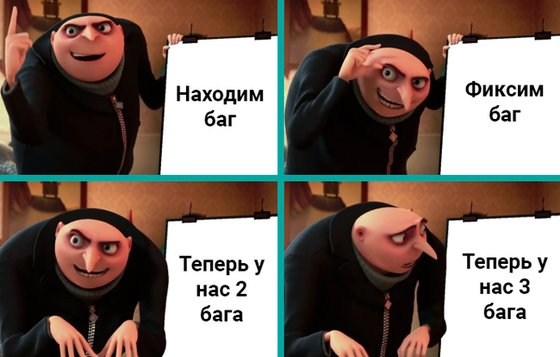

*План Грю, версия для этой практики: находим баг (`int("привет")`), фиксим (`except ValueError`) — и теперь у нас два бага, потому что `except ValueError` заодно ловит кодировки. Третий вы найдёте сами, в ДЗ3.*

# 12. Итоги и ДЗ3

## Что мы сегодня прошли

Подведём итог. Сегодня наш код перестал быть одной длинной простынёй и вышел во внешний мир.

1. **Функции.** `def`, параметры и аргументы, `return` вместо `print` — бумажка с ответом, а не крик в пустоту. Docstring, `help()` и подсказки типов.
2. **Гибкие аргументы.** Значения по умолчанию, именованные аргументы, `*args` и `**kwargs` — и ловушка `def f(x=[])`, в которую рано или поздно попадает каждый.
3. **Область видимости.** Что было в функции — остаётся в функции. Переприсвоить и изменить — не одно и то же, а `global` — это очень плохо.
4. **Comprehensions и lambda.** Списки, словари и множества в одну строку, сортировка по `key=lambda …`.
5. **Файлы.** `with open(...)`, режимы, три способа чтения — и явный `encoding=` в каждом `open()`: по умолчанию `"utf-8"`, другая — только если точно знаете, что файл в ней.
6. **pathlib.** Пути как объекты, `/` между частями — и относительный путь, который считается от текущей папки, а не от папки скрипта.
7. **JSON.** Словарь — в файл, из файла — обратно в словарь, с русскими буквами и отступами.
8. **Модули.** `import`, `uv add`, свой модуль и `if __name__ == "__main__"`.
9. **Даты и время.** Наивные и «осведомлённые» даты, `zoneinfo`, `isoformat`; храним в UTC, показываем в местном — и час, который в Берлине был дважды.
10. **Исключения.** `try/except/else/finally`, `raise ValueError` в своей функции, `except Exception` вместо голого `except:`.
11. **Практика.** Функция, которая не падает, и `except` в порядке «от частного к общему».

Если коротко: раньше программа жила в вакууме, а теперь она читает файлы, знает, который час и в каком часовом поясе, и не умирает от первого же кривого ввода.

И напоследок — про то, как устроен этот «короткий и простой» Python, которым мы всю лекцию пользовались:

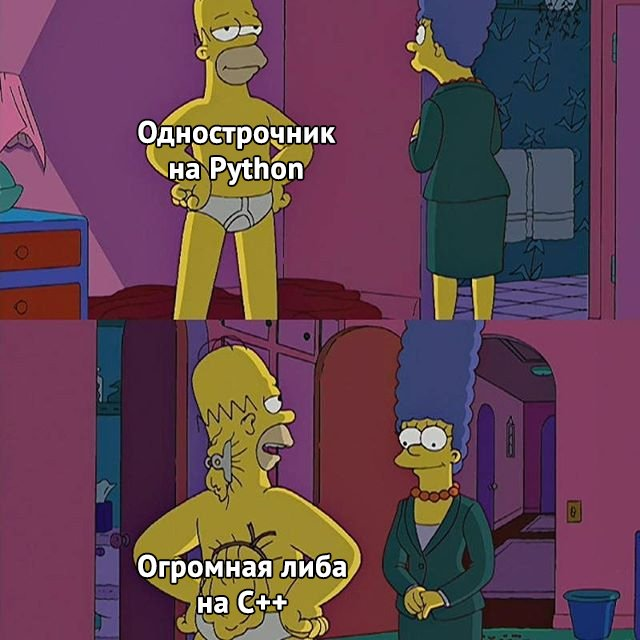

Почти всё, что мы сегодня писали одной строкой, — `json.dump`, `ZoneInfo("Europe/Berlin")`, `Path(...).glob(...)` — спереди однострочник, а сзади огромная библиотека, которую написал кто-то другой. У `json` и `zoneinfo` под капотом, кстати, действительно компилируемый код — только на C, а не на C++, как у Гомера на картинке. Пользуйтесь — но не забывайте, на чём стоите.

## ДЗ №3. «Чёрный ящик»

*Тема: файлы, pathlib, JSON, даты и часовые пояса, исключения, свои функции. Оценка: 10 баллов.*

Начинать можно после раздела 6, а функцию разбора с `raise` писать — после раздела 10. Если на паре мы до конца не дошли — ДЗ всё равно выдано: дочитайте тетрадку дома.

У самолёта есть чёрный ящик — бортовой самописец. После катастрофы его находят и по записям восстанавливают, что случилось. У серверов чёрный ящик — это **логи**: каждый сервер построчно пишет в файл, что он делает и что у него сломалось.

Ваша ситуация. Сервис, который вы сопровождаете, ночью лёг. Утром у вас на столе папка логов с нескольких серверов. Серверы стоят в разных городах, пишут время каждый по-своему, файлы сохранены в разных кодировках, и часть строк побита. Начальство хочет знать: что случилось, когда и сколько времени сервис лежал. Ваша программа должна это выяснить.

### Как получить вариант

Как в ДЗ1 и ДЗ2: у каждого свой вариант, его выдаёт тот же скрипт `hw_variant.py`. Только теперь с аргументом `hw3`. В терминале VS Code, строго из папки проекта:
```bash
uv run hw_variant.py ваш-github-логин hw3
```
Кто шёл через Miniforge — как в прошлый раз, в Miniforge Prompt: `conda activate misis`, `cd` в папку проекта, один раз `pip install tzdata` (зачем — ниже) и потом `python hw_variant.py ваш-github-логин hw3`.

Если ваш `hw_variant.py` скачан давно и про `hw3` ничего не знает, скачайте его заново из репозитория курса, папка `hw/`. Варианты ДЗ1 и ДЗ2 у новой версии те же самые: для одного логина скрипт по-прежнему выдаёт одно и то же.

Скрипт сделает две вещи:
1. Создаст папку **`hw3/logs/`** с файлами логов вашего варианта. Один файл — один сервер, имя сервера — имя файла без `.log`: в `api.log` пишет сервер `api`. У соседа — другие серверы, другие файлы, другой инцидент.
2. Напечатает **блок варианта** — от `# === ВАРИАНТ ===` до `# === КОНЕЦ ВАРИАНТА ===`. В нём словарь «сервер → часовой пояс»: в каком поясе сервер пишет время, если пояс в строке не указан. Выглядит так (серверы и пояса у вас свои):
```python
# === ВАРИАНТ ===
SERVER_TIMEZONES = {"api": "Europe/Berlin", "auth": "Asia/Novosibirsk", "db": "UTC"}
# === КОНЕЦ ВАРИАНТА ===
```
Блок вставляете в самое начало `hw3/main.py` как есть, руками внутри ничего не правите — ровно как в ДЗ1 и ДЗ2.

Скрипт каждый раз выдаёт для одного логина одно и то же. Случайно испортили логи — запустите ещё раз, он создаст их заново, такие же. Сами логи руками **не правьте**, даже одну строчку: программа должна справиться с ними такими, какие есть. В ДЗ1–ДЗ2 я обещал, что читать данные из файлов мы научимся. Вот, научились.

### Формат строки лога

Как в разделе 10: три части через « | » — пробел, вертикальная черта, пробел. Например:
```text
2026-10-25T01:12:40Z | INFO | Health check ok
2026-10-25 04:13:05+03:00 | ERROR | Timeout after 3012 ms for user 1834
2026-10-25 02:30:00 | WARNING | Retry 2 of 5 | queue=orders
```
- **Время** — в формате ISO 8601, который понимает `datetime.fromisoformat`: через `T` или через пробел, с поясом (`Z`, `+03:00`) или без. Время без пояса — местное время сервера, пояс берёте из блока варианта.
- **Уровень** — ровно одно из пяти слов, заглавными буквами: `DEBUG`, `INFO`, `WARNING`, `ERROR`, `CRITICAL` (как `LEVELS` в разделе 10). `error`, `Error`, `EROR`, `FATAL` — битая строка.
- **Сообщение** — всё после второго разделителя. В нём самом может встретиться « | », как в третьей строке примера. Это **нормальная** строка, её сообщение — `Retry 2 of 5 | queue=orders`. Режьте с `maxsplit=2`, как в разделе 10.
- **Пробелы по краям строки** обрезаете — `line.strip()`, как в разделе 10. После этого строка без сообщения (`… | INFO |`) — битая.
- **Пустые строки** (и строки из одних пробелов) молча пропускаете: это не битые строки, в отчёт они не идут.
- Всё остальное, что по этим правилам не разбирается, — **битая строка**.

### Что должна сделать программа

Программа ничего не спрашивает у пользователя. Она читает **все** файлы `*.log` из папки `hw3/logs/` и пишет два отчёта: **`hw3/report.json`** — для машины и **`hw3/report.txt`** — для человека. Всё считается только по разобранным строкам — битые идут только в п. 5. В отчётах:

*🎤 Вслух — первая фраза каждого пункта, детали студенты читают сами.*

1. **Уровни** (`levels`) — сколько строк каждого уровня. Все пять ключей, даже если где-то ноль.
2. **Ошибки по часам по Москве** (`errors_by_hour_msk`) — сколько строк уровня `ERROR` пришлось на каждый час суток по московскому времени (`Europe/Moscow`). Только `ERROR`: `CRITICAL` считается только в `levels`. Ключи — строки от `"00"` до `"23"`, все 24, даже если ошибок в каком-то часу ноль: в разделе 7 вы видели, как JSON превращает ключ-число в строку, так что сразу строки. Если логи захватывают несколько суток, часы разных дней складываются: `"03"` — это все ошибки с 03:00 до 03:59 по Москве, в какой бы день они ни случились.
3. **Топ-5 ошибок** (`top_errors`) — тоже только `ERROR`. Сообщения `Timeout after 3012 ms for user 1834` и `Timeout after 87 ms for user 5` — это одна и та же ошибка, просто с разными числами. Поэтому в каждом сообщении каждую группу идущих подряд цифр заменяете на `<N>` — получится шаблон `Timeout after <N> ms for user <N>`. Ровно так, без вариантов: мой скрипт сверяет и шаблоны, и количества. Дальше — пять самых частых шаблонов, списком пар `[шаблон, количество]`, по убыванию количества; при равном количестве — по алфавиту, обычным сравнением строк (сортировка по кортежу из раздела 4). Разных шаблонов меньше пяти — значит, сколько есть.
4. **Самый длинный простой** (`longest_gap`) — самый длинный промежуток между двумя соседними по времени разобранными строками из **всех** файлов вместе, любого уровня. Иначе говоря, время, когда **ни один** сервер не написал ни строчки. Начало и конец — по Москве, как выдаёт `.isoformat()`, длительность `seconds` — целое число секунд. Если самых длинных промежутков несколько — берите самый ранний. Скорее всего, именно тогда сервис и лежал.
5. **Нераспознанные строки** (`bad_lines`) — каждая битая строка: `file` — только имя файла (`api.log`, без папок), `line_no` — номер строки с единицы, как в редакторе (`enumerate(…, start=1)` из раздела 10), `reason` — причина своими словами: ваш текст из `raise ValueError` или текст ошибки, которую бросил `fromisoformat` (как с 02:61 в разделе 10). Порядок — по имени файла, внутри файла — по номеру строки. Мой скрипт сверяет `file` и `line_no`, а `reason` читаю я.

`report.json` — **ровно такой** структуры: ключи и типы значений те же. Числа выдуманы, `…` — пропущенное для краткости.

*🎤 JSON вслух не зачитывать — пройдитесь по ключам на экране.*
```text
{
  "levels": {"DEBUG": 310, "INFO": 1520, "WARNING": 87, "ERROR": 41, "CRITICAL": 2},
  "errors_by_hour_msk": {"00": 0, "01": 3, "02": 0, … , "23": 1},
  "top_errors": [["Timeout after <N> ms for user <N>", 12], ["Disk <N> is full", 7], …],
  "longest_gap": {"start": "2026-10-25T03:12:40+03:00", "end": "2026-10-25T04:01:05+03:00", "seconds": 2905},
  "bad_lines": [{"file": "api.log", "line_no": 17, "reason": "неизвестный уровень 'EROR'"}, …]
}
```
Имена ключей — ровно такие: по ним мой скрипт будет сверять отчёт. JSON — в UTF-8, с русскими буквами, а не с `\u0441\u0442`. А `report.txt` оформляете как хотите. Критерий один: дежурный инженер, которого разбудили в четыре утра, должен понять из него, что случилось, за тридцать секунд.

**Обязательно** в коде:
- пути — через `pathlib`, и все — от папки скрипта: `Path(__file__).resolve().parent` из раздела 6. И логи, и оба отчёта считайте от неё;
- файлы — через `with open(…)` или через `Path.read_text`/`write_text` (внутри у них тот же `with`, раздел 6), но **всегда** с явным `encoding=…`, и на чтение, и на запись. Перебираете кодировки через `read_bytes()` и `.decode(…)` — тоже можно: кодировка там тоже названа явно;
- **своя функция разбора одной строки**, которая на кривой строке бросает `raise ValueError("понятная причина")`. Эта причина и попадает в отчёт. А ловит ошибку, печатает и складывает в отчёт цикл, который эту функцию вызывает, — как в разделе 10;
- часовые пояса — через `zoneinfo`. Из сторонних пакетов можно только `tzdata`. Pendulum, dateutil, chardet и прочие — нельзя: задача как раз в том, чтобы разобраться самим. Стандартная библиотека — любая, включая `re`. На Windows `tzdata` обязателен, иначе `zoneinfo` не найдёт ни одного пояса: `uv add tzdata`, в Miniforge Prompt — `pip install tzdata`.

**Желательно:** подписи типов у своих функций, как в разделе 1. Баллы за их отсутствие не сниму, но код с ними на защите читается быстрее — и вами, и мной.

Запуск — из папки проекта:
```bash
uv run hw3/main.py
```
(Miniforge — `python hw3/main.py`.) Относительный путь, как мы выяснили в разделе 6, считается от **текущей** папки, а не от папки скрипта. Напишете просто `Path("logs")` — при таком запуске программа будет искать `logs` в корне проекта и ничего не найдёт. Поэтому — от `Path(__file__).resolve().parent`.

### Ловушки (их не избежать, их надо заметить)

- **Кодировки.** Файлы в папке — в разных кодировках: `utf-8`, `utf-8-sig` и `cp1251`, каждый файл целиком в одной из трёх. Какой файл в какой — вам никто не скажет. Что такое `utf-8-sig`, вы уже знаете — вспомните раздел 5 и BOM: прочитаете такой файл как обычный `utf-8` — первая строка откажется разбираться, хотя выглядит идеально. Вспомните 42 из бухгалтерии в практике. И учтите: строка, которая не разобралась только потому, что вы не угадали кодировку, — не битая. Это ваша ошибка, а не ошибка лога.
- **Часовые пояса и форматы времени.** Например, один сервер пишет время в UTC с буквой `Z` на конце, другой — с явным смещением вроде `+03:00`, третий — просто местное время, без всякого пояса, а какой у него пояс — смотрите в блоке варианта. Сравнивать можно только время, приведённое к одному поясу.
- **Ночь на 25 октября 2026.** В каждом варианте (и в скрытых данных тоже) один из серверов пишет местное время без пояса, а пояс у него — с переводом часов, например `Europe/Berlin`. В эту ночь Европа перевела часы назад, и в Берлине час с 02:00 до 03:00 был **дважды**. Строка `02:30` в его логе может означать два разных момента, между которыми ровно час. Разберётесь наивно — получите либо промежуток отрицательной длины, либо «простой» длиной в час там, где сервис спокойно работал. А по закону подлости инцидент случился как раз в тот час, который был дважды. Как отличить первое `02:30` от второго? Каждый сервер пишет строки по порядку — время в его файле не убывает. Нигде, кроме этой ночи. Отсюда правило: если наивное время в файле стало меньше, чем в предыдущей разобранной строке того же файла, — с этой строки и до конца двойного часа идёт второй проход, `fold=1`. Что такое `fold`, вспомните из раздела 9, подробности — в документации `datetime`.
- **Битые строки.** Обрезанные или склеенные так, что пострадали разделитель, время или уровень; с опечаткой в уровне; с датой, которой не бывает. Битая — строка, которая не разбирается по правилам выше. Разбирается — нормальная, даже если сообщение выглядит странно. Программа не должна падать ни на одной битой строке — но и молча выкидывать их нельзя: каждая — в отчёт, с причиной.
- **Разделитель внутри сообщения.** А вот это — не битая строка, см. правила выше. Кто разрежет её на четыре части и запишет в брак — попался.

Как вы разобрались с каждой ловушкой — коротко в README, в раздел **«Мои решения»**. По кодировкам, поясам и ночи на 25 октября ответ однозначный, его сверяет мой скрипт; в README — как вы к нему пришли. Свобода у вас — в `report.txt` и в тексте `reason`.

### Куда класть, как сдавать

Репозиторий тот же, что для ДЗ1 и ДЗ2:
```text
misis_course/
├── hw1/main.py
├── hw2/main.py
├── hw3/
│   ├── main.py        ← ДЗ3: блок варианта в начале, ваш код ниже
│   ├── logs/          ← создал hw_variant.py, руками не трогать
│   ├── report.json    ← создаёт ваша программа
│   └── report.txt     ← создаёт ваша программа
├── hw_variant.py
└── README.md          ← «Мои решения» и «Где помогал ИИ» — теперь и по ДЗ3
```
Папку `hw3/logs/` вместе с отчётами — коммитите в репозиторий.

Остальное — как в ДЗ1 и ДЗ2, ничего не поменялось:
- **ИИ** — можно, в README раздел **«Где помогал ИИ»**: что спрашивали и что из ответа взяли. Только держите в голове плашки 🤖 из этой лекции: `utcnow()`, `pytz`, `open()` без кодировки и `except Exception: pass` нейросеть предложит вам первой. Принесёте такое на защиту — будем разбирать вслух.
- **Репозиторий публичный**, и в нём минимум три осмысленных коммита **по ДЗ3** — например, с сообщениями, которые начинаются с `hw3:`. Работа над ДЗ3 должна быть видна в истории, а не одним коммитом в ночь перед зачётом.
- **Сдача:** присылать ничего не нужно — ссылки на ваши репозитории у меня есть, открою сам. Сдаётся `hw3/main.py` (вместе с отчётами и README), а не тетрадка.
- **Защита** — как обычно, два шага. Первый: я запускаю вашу программу на **скрытых данных** — заменяю блок варианта и папку `hw3/logs/` своими. Там будут другие файлы и другие часовые пояса, а кодировки распределены по файлам иначе — но это всё те же три: `utf-8`, `utf-8-sig`, `cp1251`. Программа, в которой где-то в глубине зашито имя вашего файла или ваш Берлин, не работает. Второй: небольшая правка кода у меня на глазах, 5–10 минут, без ИИ.
- **Сроки** — жёстких нет, сделать и защитить до зачёта. Только вот это ДЗ — самое объёмное из трёх, и за одну ночь перед зачётом его не делают. Проверено на предыдущих поколениях.
- **Перед сдачей** — новый терминал, `uv run hw3/main.py`, открыть оба отчёта и прочитать их глазами. «У меня работало» не считается.

Всё, на сегодня это всё. В следующей лекции — классы и объекты. Там наконец станет понятно, что за `__mro__` мы видели в родословной ошибок и почему у строки есть `.upper()`, а у числа нет.